# Island identification stress test

Deliberately adversarial tests for threshold cliffs, geometry traps, mode-selection failures, and noisy/high-cardinality windows.

## Sections

1. Setup and fixed parameters
2. Test helpers
3. Baseline sanity checks
4. Island-formation cutoffs
5. Ridge and mode cutoffs
6. Geometry traps
7. Combined adversarial cases
8. Noise and peak-count scaling
9. Random adversarial search
10. Compact review tables


## 1. Setup and fixed parameters


In [1]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import utils
importlib.reload(utils)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
# These are the fixed baseline parameters. Individual cutoff tests override one value only when stated.
island_parameters = dict(
    seed_threshold_fraction=0.4, growth_threshold_fraction=0.25,
    max_weak_distance=5, gap_tolerance=1, shape_balance_power=1.05,
    ridge_fraction=0.9, ridge_smoothing=4.0,
    split_prominence_fraction=0.25, split_min_peak_fraction=0.5,
    split_min_peak_distance=8, split_smoothing=4.0, split_min_seed_area=5,
    zero_lag_threshold=5,
    displacement_fold_threshold=2.0, mode_lag_tolerance=5,
    mode_score_fraction=0.33
)

N = 300
SEED = 87431
FUZZ_WINDOWS = 200
FUZZ_CASES_TO_PLOT = 8
SCALING_REPLICATES = 4

## 2. Test helpers

The helpers keep every signal-generating value explicit. `run_cases` shows both the internal detection stages and the full track/heatmap view.


In [3]:
def peak_track(n, peaks, baseline=0.0, noise_level=0.0, rng=None):
    x = np.arange(n, dtype=float)
    values = np.full(n, baseline, dtype=float)
    for center, width, height in peaks:
        values += utils.gaussian(x, center, width, height)
    if noise_level > 0:
        if rng is None:
            raise ValueError("rng is required when noise_level > 0.")
        values = utils.add_noise(values, rng, noise_level, n)
    return np.maximum(values, 0)

def plateau_track(n, plateaus, baseline=0.0, noise_level=0.0, rng=None):
    x = np.arange(n, dtype=float)
    values = np.full(n, baseline, dtype=float)
    for center, width, edge, height in plateaus:
        values += utils.plateau(x, center, width, edge, height)
    if noise_level > 0:
        if rng is None:
            raise ValueError("rng is required when noise_level > 0.")
        values = utils.add_noise(values, rng, noise_level, n)
    return np.maximum(values, 0)

def bridged_peaks(n, left_center, right_center, width, left_height, right_height, bridge_height, baseline=0.0):
    values = peak_track(n, [(left_center, width, left_height), (right_center, width, right_height)], baseline=baseline)
    left = int(np.ceil(left_center))
    right = int(np.floor(right_center)) + 1
    values[left:right] = np.maximum(values[left:right], baseline + bridge_height)
    return values

def shifted_peak_pair(n, centers, widths, heights, shifts, baseline=0.02, noise_level=0.0, rng=None):
    a_peaks = list(zip(centers, widths, heights))
    b_peaks = list(zip(np.asarray(centers) + np.asarray(shifts), widths, heights))
    a = peak_track(n, a_peaks, baseline=baseline, noise_level=noise_level, rng=rng)
    b = peak_track(n, b_peaks, baseline=baseline, noise_level=noise_level, rng=rng)
    return a, b

def fold_competition_pair(displaced_height, n, central_height=0.35, center=145, displacement=65, width=9):
    a = peak_track(n, [(center, width, 1.0)])
    b = peak_track(n, [(center, width, central_height), (center + displacement, width, displaced_height)])
    return a, b

def mode_fraction_pair(variable_height, n, fixed_height=1.0, center=150, displacement=65, width=9):
    a = peak_track(n, [(center, width, 1.0)])
    b = peak_track(n, [(center - displacement, width, fixed_height), (center + displacement, width, variable_height)])
    return a, b

In [4]:
def analyze_case(label, signal_a, signal_b, island_parameters, overrides=None, plot=False):
    parameters = dict(island_parameters)
    if overrides is not None:
        parameters.update(overrides)
    result = utils.inspect_simulated_pair(signal_a, signal_b, title=label, plot=plot, **parameters)
    result["stress_label"] = label
    result["stress_parameters"] = parameters
    return result

def result_summary(result):
    gate = result["selection"]["central_gate"]
    selected_islands = {island_id for mode in result["modes"] for island_id in mode["islands"]}
    return {
        "case": result["stress_label"],
        "islands": len(result["islands"]),
        "provisional_modes": len(result["selection"]["provisional_modes"]),
        "selected_modes": len(result["modes"]),
        "selected_islands": len(selected_islands),
        "deleted_islands": len(result["selection"]["deleted_island_ids"]),
        "central_gate": gate.get("status"),
        "central_reason": gate.get("reason"),
        "selected_lags": tuple(round(mode["signed_lag"], 2) for mode in result["modes"]),
    }

def mode_table(result, stage="provisional_modes"):
    rows = []
    for mode in result["selection"][stage]:
        rows.append({
            "mode": mode["mode_id"], "lag": mode["signed_lag"],
            "islands": mode["islands"], "compatible": mode["compatible_islands"],
            "n_islands": mode["n_islands"], "n_independent": mode["n_independent_islands"],
            "score": mode["selection_score"], "all_score": mode["all_island_score"],
            "fraction": mode.get("score_fraction_of_strongest", np.nan),
            "zero_lag": mode["zero_lag"], "conflict_fraction": mode["conflict_fraction"],
        })
    return pd.DataFrame(rows)

def plot_detection_stages(results):
    fig, axes = plt.subplots(len(results), 3, figsize=(12, 3.6 * len(results)), squeeze=False)
    for row, result in enumerate(results):
        images = (result["seed_mask"], result["island_mask"], result["island_labels"])
        titles = ("seed mask", "grown mask before splitting", "final island labels")
        cmaps = ("gray_r", "gray_r", "tab20")
        for col, (image, title, cmap) in enumerate(zip(images, titles, cmaps)):
            axes[row, col].imshow(image, origin="lower", aspect="equal", cmap=cmap, interpolation="nearest")
            axes[row, col].set_title(title)
            axes[row, col].set_xlabel("B position")
            axes[row, col].set_ylabel("A position")
        axes[row, 0].text(0.01, 1.05, result["stress_label"], transform=axes[row, 0].transAxes, fontweight="bold")
    plt.tight_layout()
    plt.show()

def run_cases(cases, island_parameters, show_stages=True, show_full=True):
    results = [analyze_case(case["label"], case["a"], case["b"], island_parameters, case.get("overrides")) for case in cases]
    display(pd.DataFrame([result_summary(result) for result in results]))
    if show_stages:
        plot_detection_stages(results)
    if show_full:
        for result in results:
            utils.plot_simulated_islands(result, title=result["stress_label"])
            display(mode_table(result))
    return results

def find_case_near_metric(builder, search_values, target, metric, island_parameters, builder_kwargs):
    candidates = []
    for value in search_values:
        signal_a, signal_b = builder(value, **builder_kwargs)
        result = analyze_case(f"candidate {value:.4f}", signal_a, signal_b, island_parameters)
        measured = metric(result)
        if np.isfinite(measured):
            candidates.append((abs(measured - target), value, measured, signal_a, signal_b))
    if not candidates:
        raise RuntimeError("No valid candidate was produced.")
    return min(candidates, key=lambda item: item[0])

def displaced_to_central_ratio(result):
    modes = result["selection"]["provisional_modes"]
    central = next((mode for mode in modes if mode["zero_lag"]), None)
    displaced = [mode for mode in modes if not mode["zero_lag"]]
    if central is None or not displaced or central["selection_score"] <= 0:
        return np.nan
    return max(mode["selection_score"] for mode in displaced) / central["selection_score"]

def weaker_mode_fraction(result):
    scores = sorted((mode["selection_score"] for mode in result["selection"]["provisional_modes"]), reverse=True)
    return scores[1] / scores[0] if len(scores) >= 2 and scores[0] > 0 else np.nan

## 3. Baseline sanity checks

A clean agreement, a clean displacement, a tie, and the broad-pillar case. These are references for interpreting the adversarial sections below.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,easy_agreement,4,3,1,2,2,retained,central_mode_won_conflicts,"(-7.06,)"
1,pure_displacement,9,8,2,3,4,retained,central_mode_won_conflicts,"(-16.77, -13.03)"
2,tie,2,2,2,2,0,absent,None,"(-84.53, 65.86)"
3,broad_signal_plus_peak,2,1,1,2,0,retained,central_mode_won_conflicts,"(35.74,)"


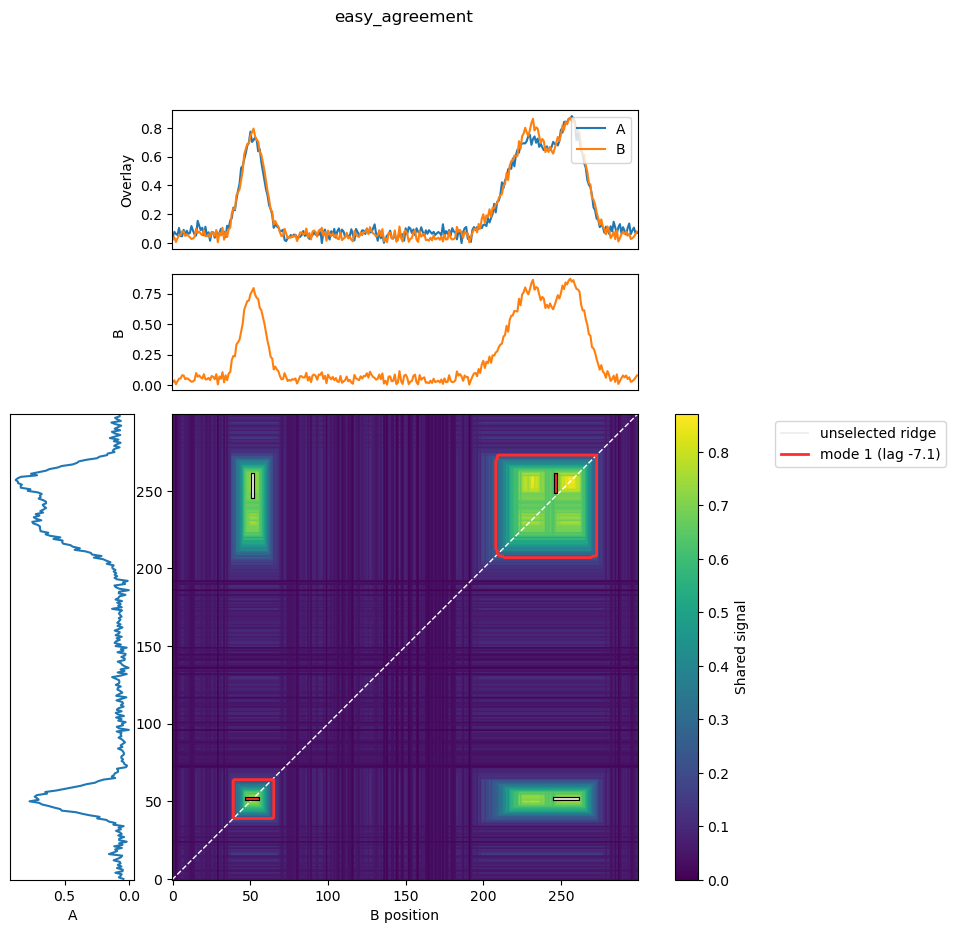

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-201.497186,"(3,)","(3,)",1,1,293.924242,293.924242,0.118181,False,0.0
1,2,-7.059687,"(1, 4)","(1, 4)",2,2,2487.058180,2487.058180,1.000000,True,0.0
2,3,202.002144,"(2,)","(2,)",1,1,275.447406,275.447406,0.110752,False,0.0


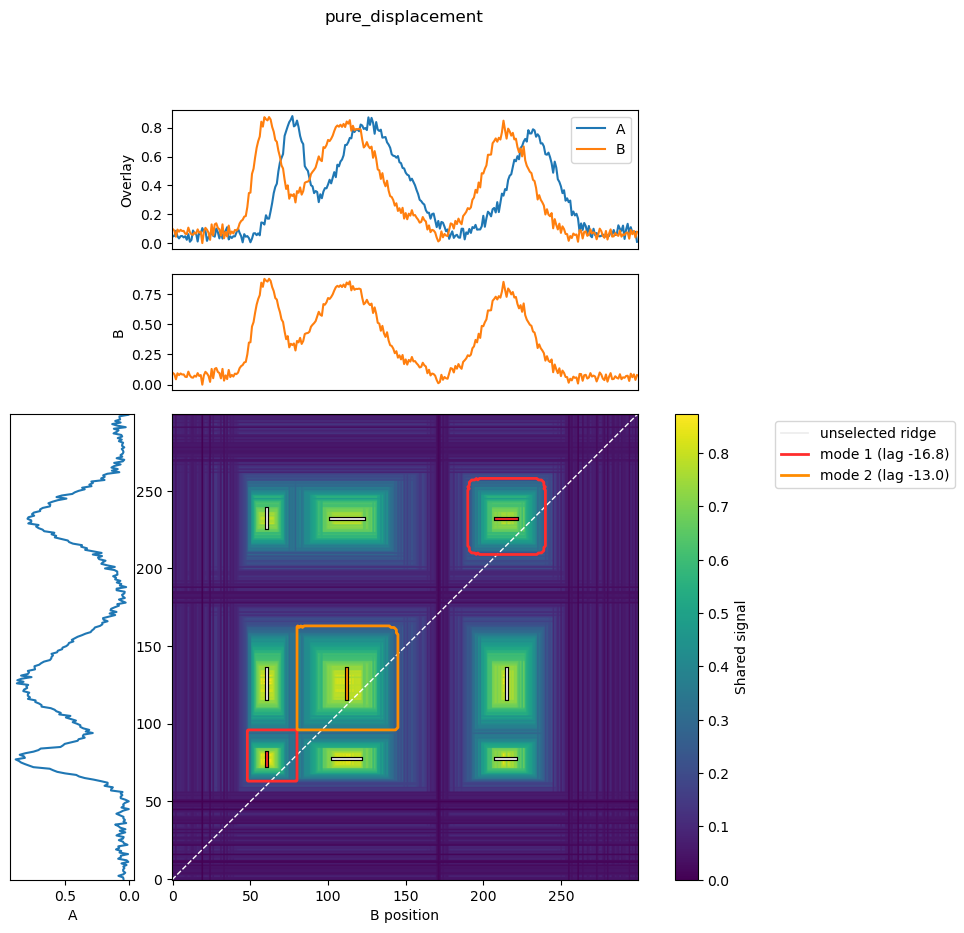

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-171.021941,"(8,)","(8,)",1,1,443.211528,443.211528,0.211770,False,0.0
1,2,-119.388392,"(7,)","(7,)",1,1,1081.820685,1081.820685,0.516903,False,0.0
2,3,-65.001369,"(3,)","(3,)",1,1,473.255292,473.255292,0.226126,False,0.0
3,4,-16.767774,"(9, 4)","(4, 9)",2,2,1501.459425,1501.459425,0.717411,False,0.0
4,5,-13.031626,"(1,)","(1,)",1,1,2092.887303,2092.887303,1.000000,True,0.0
5,6,34.980375,"(2,)","(2,)",1,1,495.190050,495.190050,0.236606,False,0.0
6,7,89.629630,"(5,)","(5,)",1,1,1145.867938,1145.867938,0.547506,False,0.0
7,8,137.480100,"(6,)","(6,)",1,1,471.048136,471.048136,0.225071,False,0.0


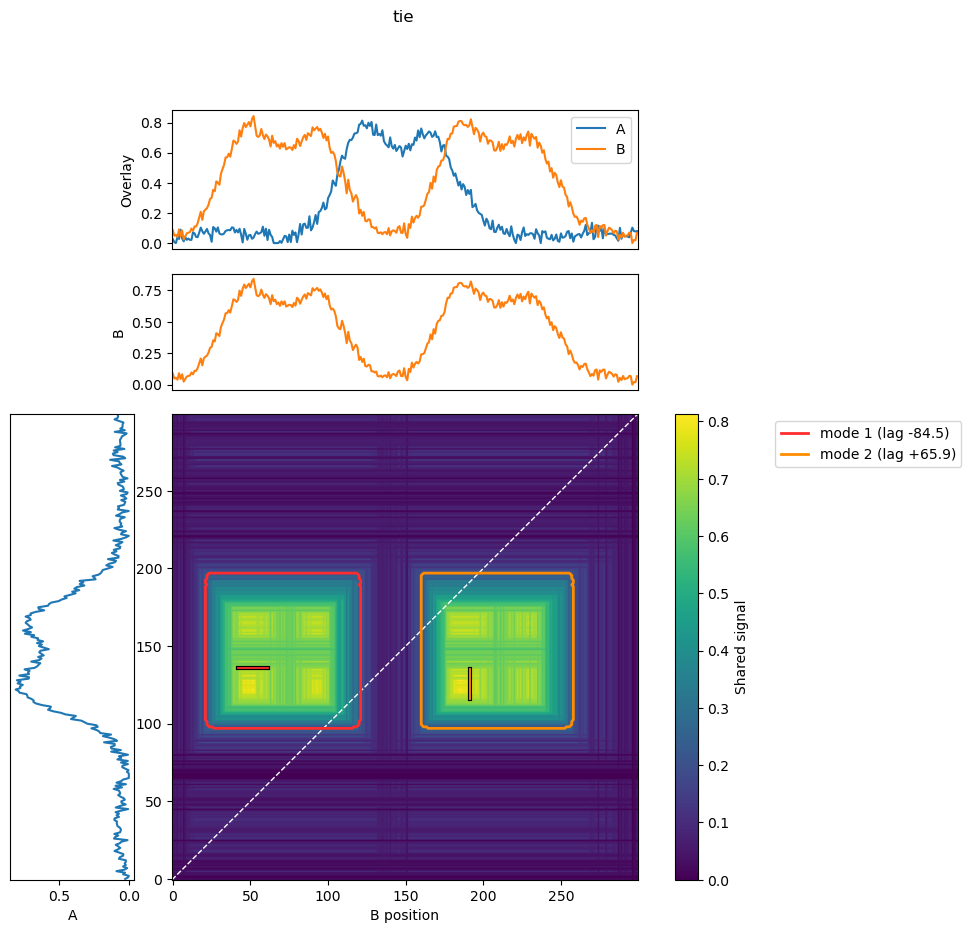

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-84.527924,"(1,)","(1,)",1,1,5038.525879,5038.525879,1.00000,False,0.0
1,2,65.856995,"(2,)","(2,)",1,1,4837.237673,4837.237673,0.96005,False,0.0


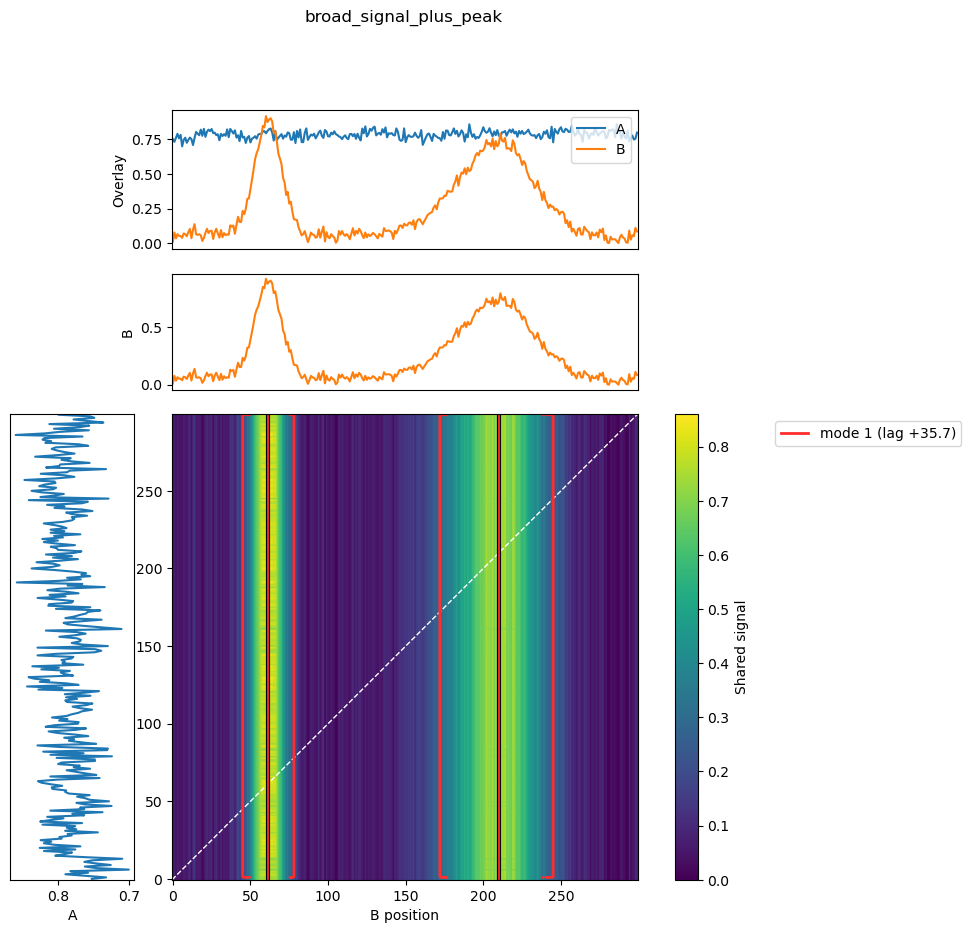

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,35.735135,"(1, 2)","(2,)",2,1,2667.682117,3205.467573,1.0,True,1.0


In [5]:
baseline_rng = np.random.default_rng(SEED)
simulation_parameters = dict(
    signal_level=0.75, signal_variation=0.15, noise_level=0.025,
    peak_count_range=(2, 3), unrelated_peak_count_range=(1, 2),
    location_range=(20, 280), width_range=(6, 24), displacement_range=(5, 30),
    tie_displacement_range=(30, 90), tie_strength_variation=0.03,
    shape_a="bell", shape_b="bell", n=N
)

baseline_cases = []
for scenario in ["easy_agreement", "pure_displacement", "tie", "broad_signal_plus_peak"]:
    a, b = utils.simulate_pair(scenario, baseline_rng, **simulation_parameters)
    baseline_cases.append({"label": scenario, "a": a, "b": b})

baseline_results = run_cases(baseline_cases, island_parameters, show_stages=False, show_full=True)

## 4. Island-formation cutoffs

These pairs put nearly identical signals immediately below and above the configured island-formation cutoffs.

### 4.1 Seed threshold: 0.399 versus 0.401 of the window maximum


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,seed just below: secondary height 0.399,2,2,1,1,1,retained,central_mode_won_conflicts,"(0.0,)"
1,seed just above: secondary height 0.401,4,3,1,2,2,retained,central_mode_won_conflicts,"(0.0,)"


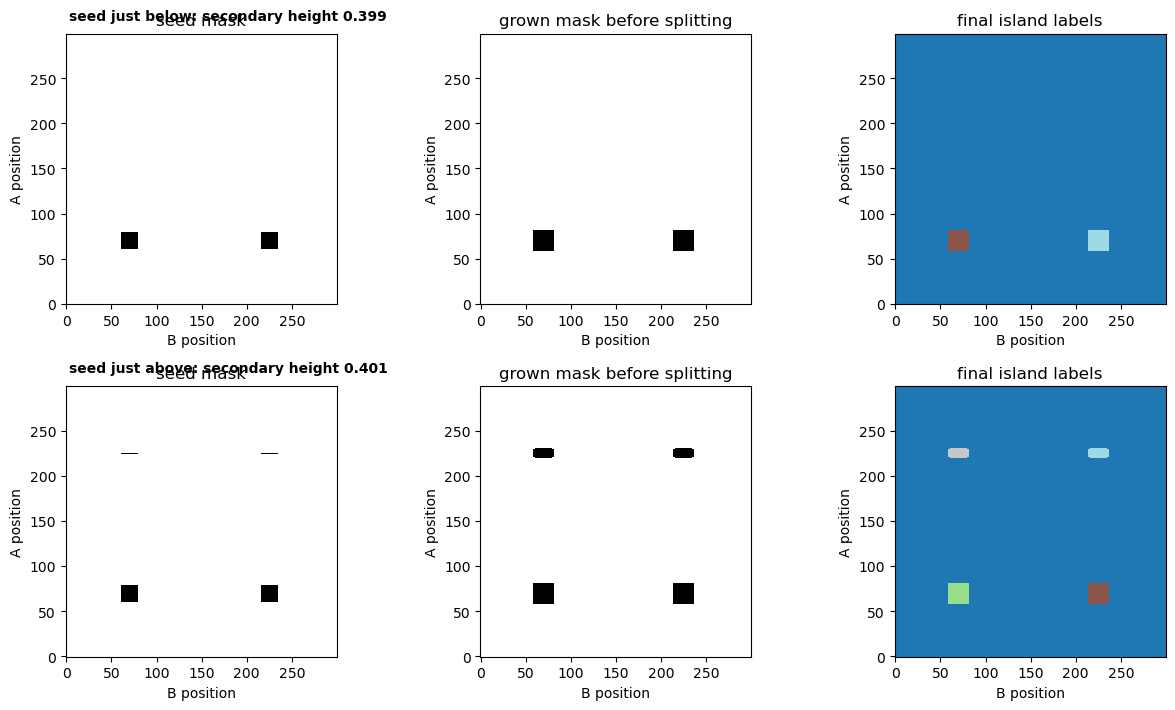

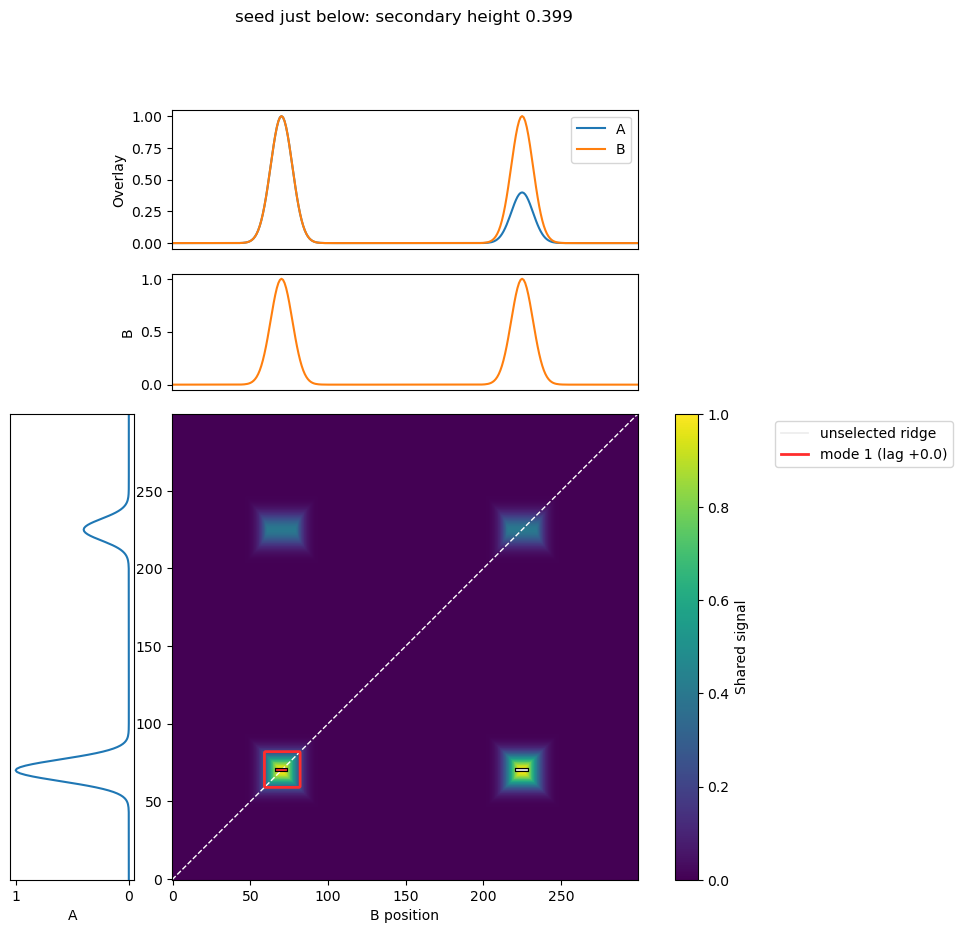

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,0.0,"(1,)","(1,)",1,1,290.805786,290.805786,1.0,True,0.0
1,2,155.0,"(2,)","(2,)",1,1,290.805786,290.805786,1.0,False,0.0


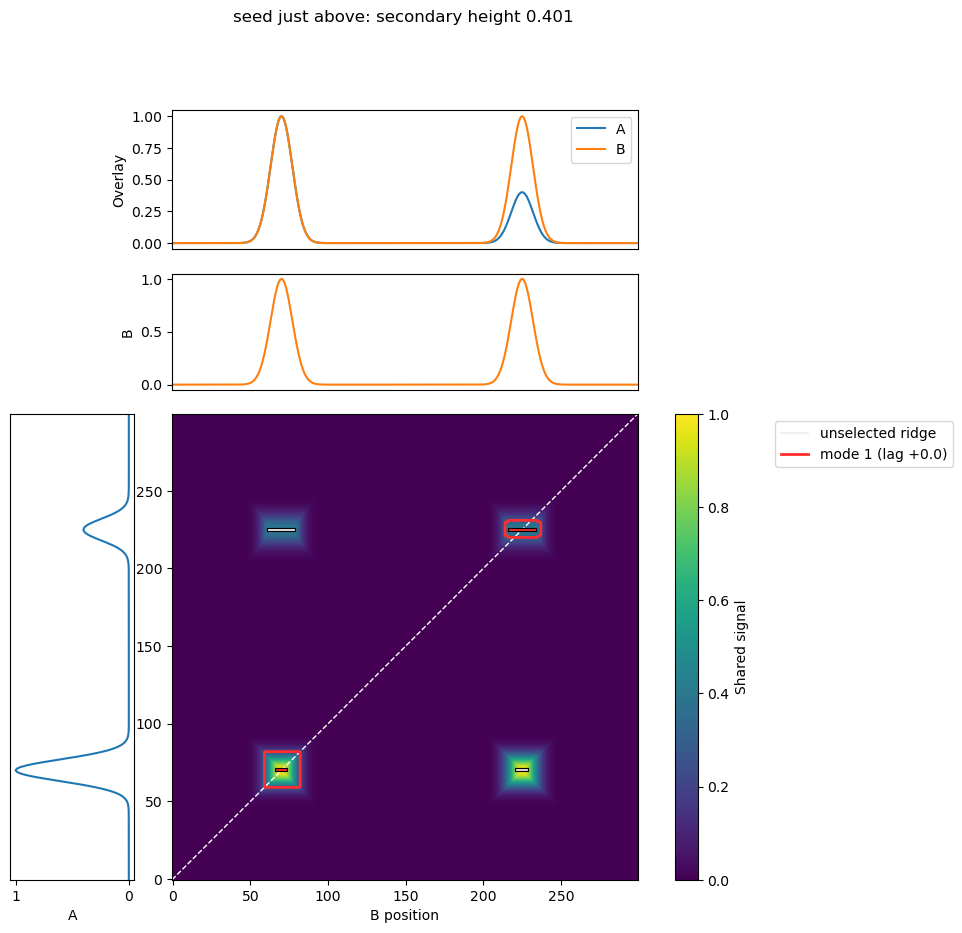

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-155.0,"(3,)","(3,)",1,1,40.390985,40.390985,0.121955,False,0.0
1,2,0.0,"(1, 4)","(1, 4)",2,2,331.196771,331.196771,1.000000,True,0.0
2,3,155.0,"(2,)","(2,)",1,1,290.805786,290.805786,0.878045,False,0.0


In [6]:
seed_reference = peak_track(N, [(70, 7, 1.0), (225, 7, 1.0)])
seed_cases = [
    {"label": "seed just below: secondary height 0.399", "a": peak_track(N, [(70, 7, 1.0), (225, 7, 0.399)]), "b": seed_reference},
    {"label": "seed just above: secondary height 0.401", "a": peak_track(N, [(70, 7, 1.0), (225, 7, 0.401)]), "b": seed_reference},
]
seed_results = run_cases(seed_cases, island_parameters)

### 4.2 Growth threshold: a bridge at 0.249 versus 0.251

This is intentionally followed by the local-minimum splitter. A robust result may change in the grown mask but converge again in the final labels.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,growth bridge just below: 0.249,2,1,1,2,0,retained,central_mode_won_conflicts,"(24.5,)"
1,growth bridge just above: 0.251,2,1,1,2,0,retained,central_mode_won_conflicts,"(24.5,)"


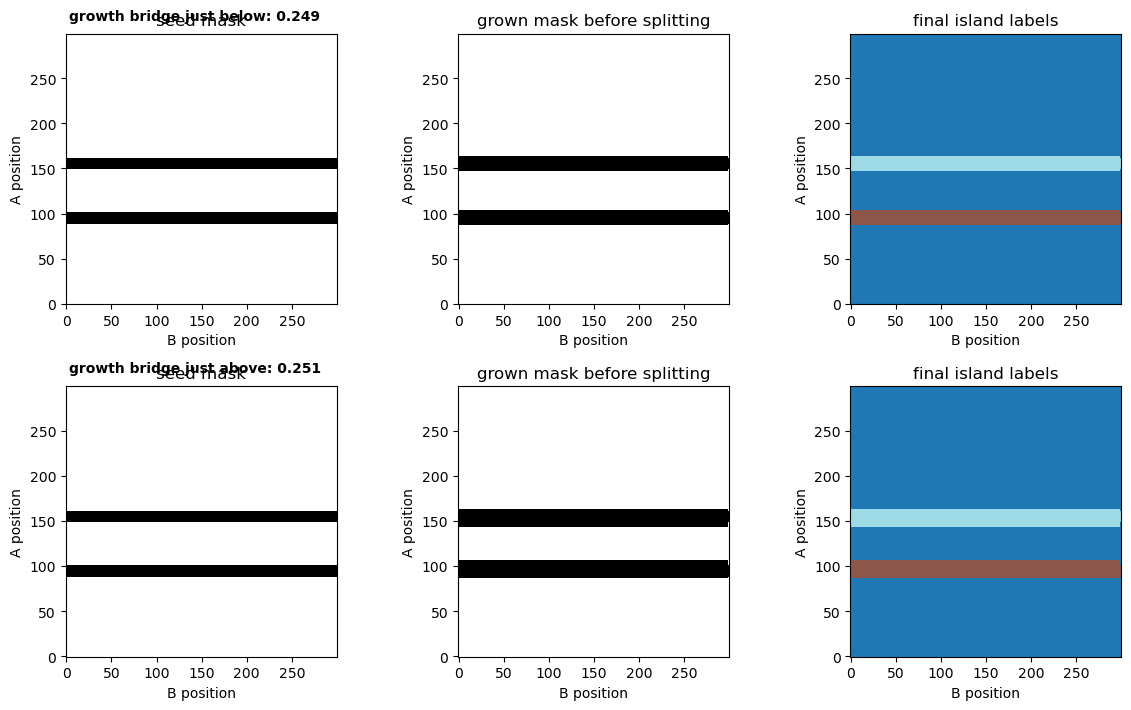

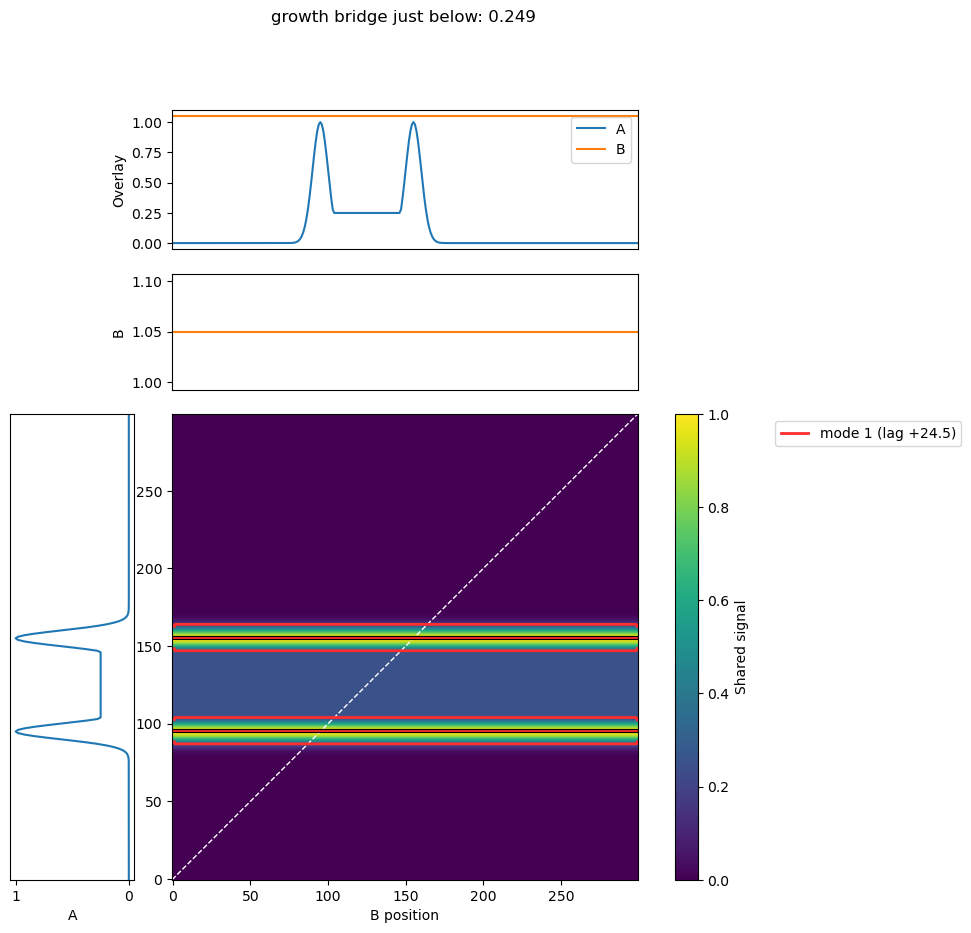

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,24.5,"(1, 2)","(1,)",2,1,168.094669,336.189338,1.0,True,1.0


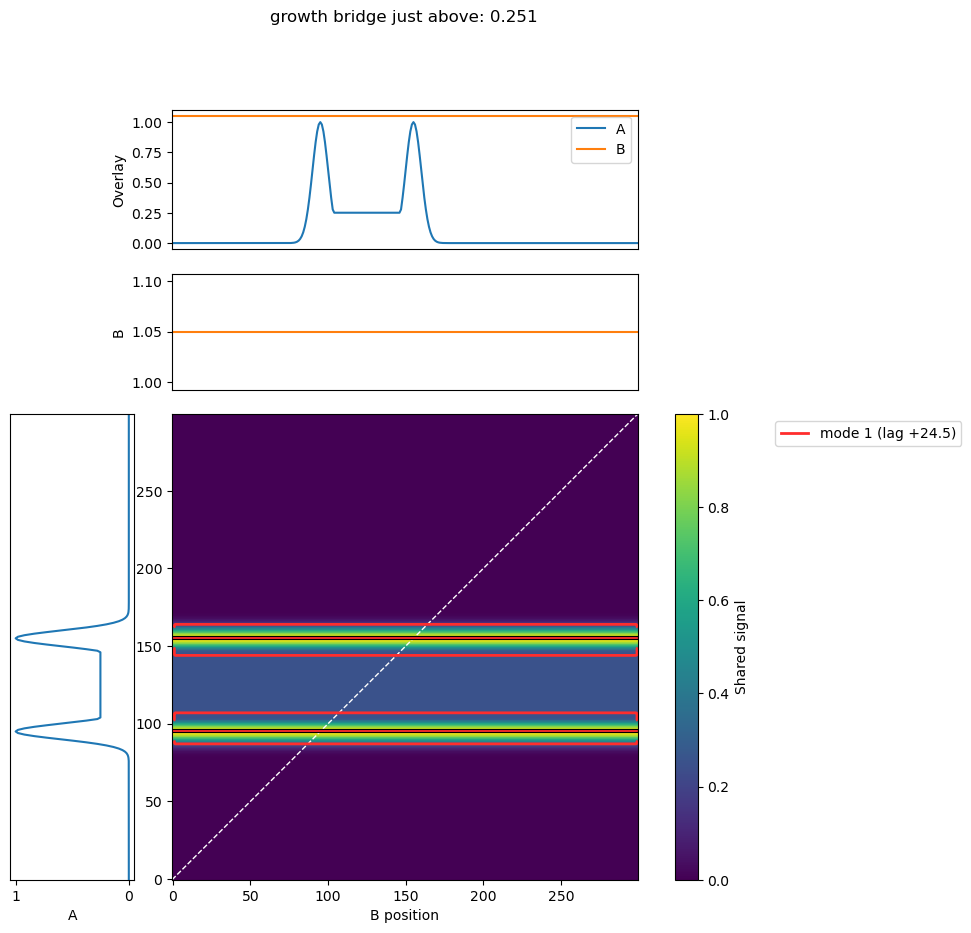

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,24.5,"(1, 2)","(1,)",2,1,212.437139,424.874278,1.0,True,1.0


In [7]:
growth_b = np.full(N, 1.05)
growth_cases = [
    {"label": "growth bridge just below: 0.249", "a": bridged_peaks(N, 95, 155, 5, 1.0, 1.0, 0.249), "b": growth_b},
    {"label": "growth bridge just above: 0.251", "a": bridged_peaks(N, 95, 155, 5, 1.0, 1.0, 0.251), "b": growth_b},
]
growth_results = run_cases(growth_cases, island_parameters)

### 4.3 Local split prominence: 24% versus 26% valley depth

The two peaks are already connected. Only the island-local valley rule should decide whether they remain merged.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,split just below prominence: valley depth abou...,1,1,1,1,0,retained,central_mode_won_conflicts,"(27.0,)"
1,split just above prominence: valley depth abou...,1,1,1,1,0,retained,central_mode_won_conflicts,"(27.0,)"


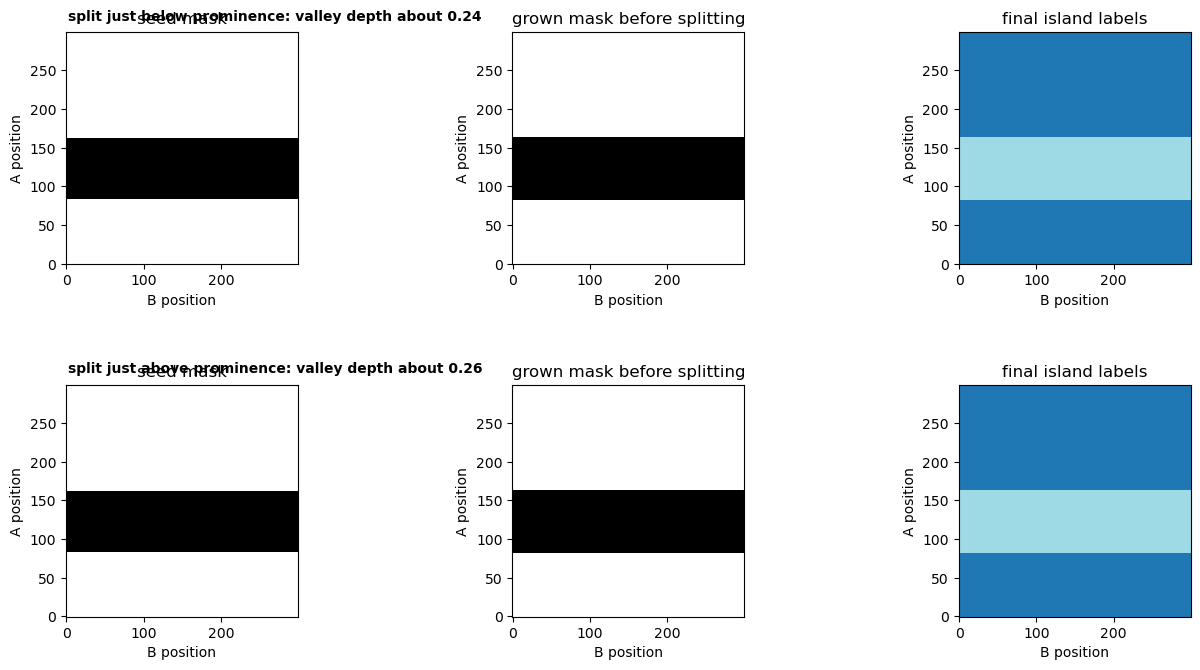

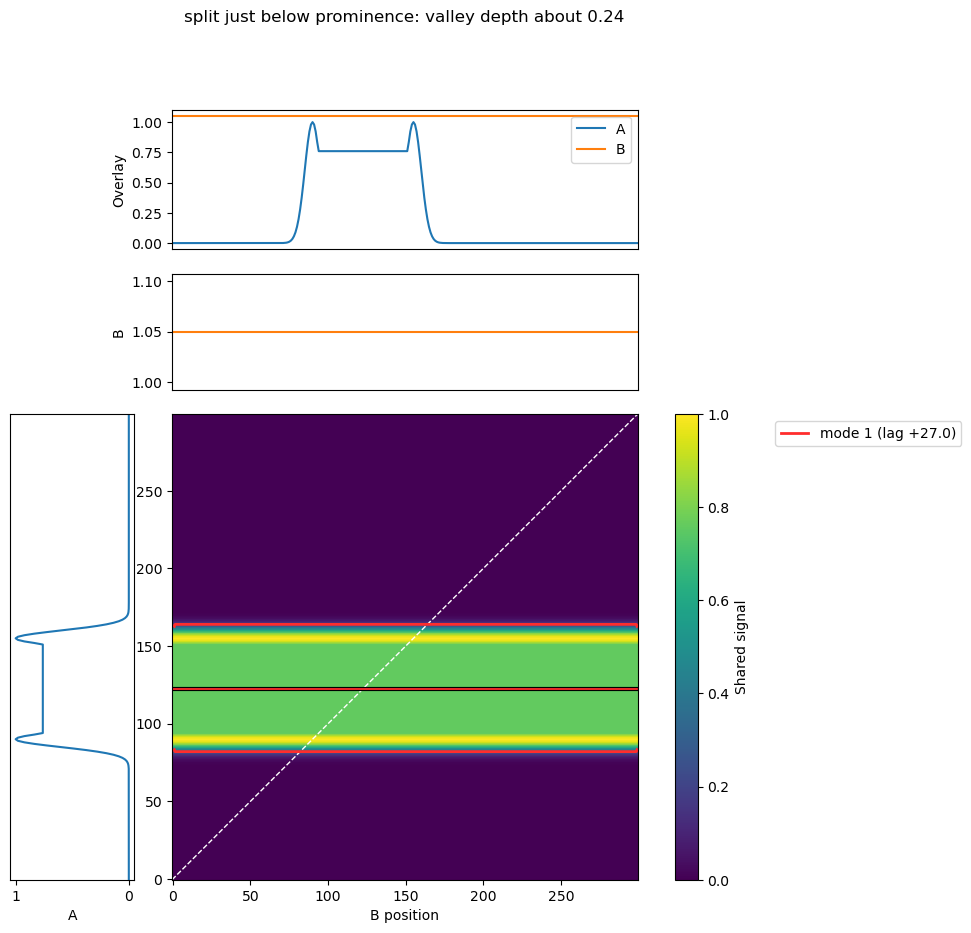

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,27.0,"(1,)","(1,)",1,1,4762.537118,4762.537118,1.0,True,0.0


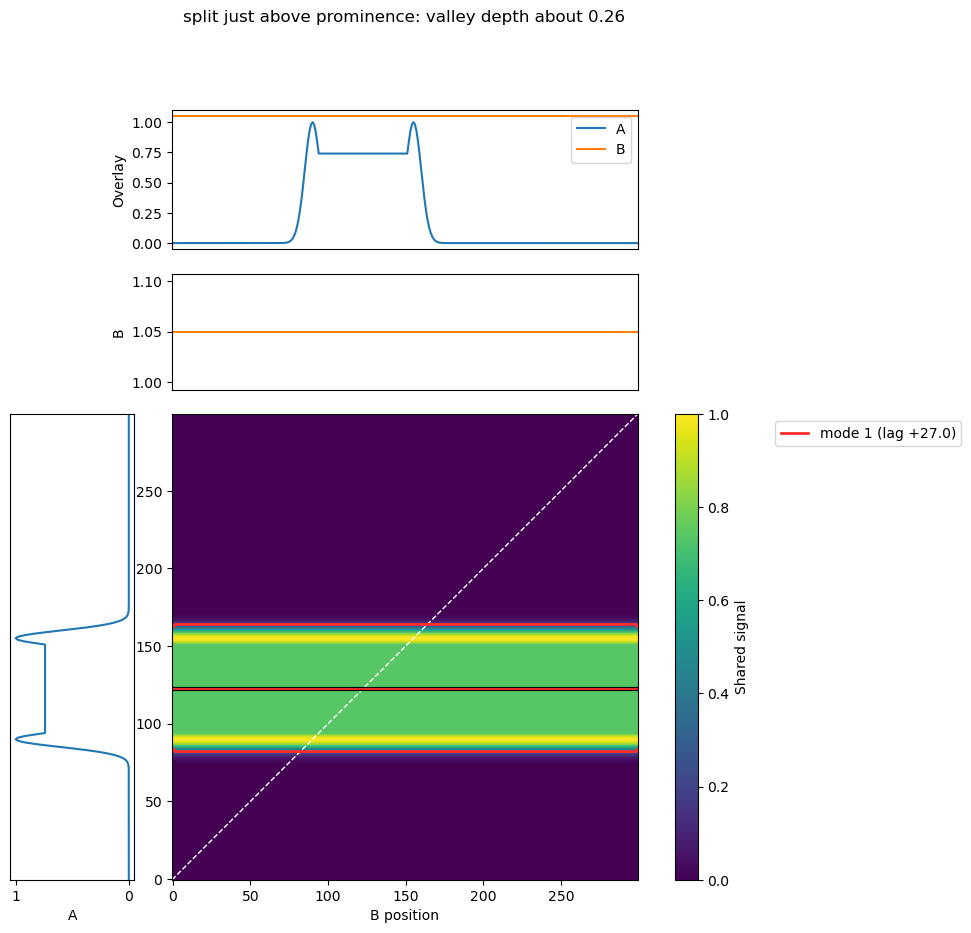

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,27.0,"(1,)","(1,)",1,1,4673.389171,4673.389171,1.0,True,0.0


In [8]:
prominence_b = np.full(N, 1.05)
prominence_cases = [
    {"label": "split just below prominence: valley depth about 0.24", "a": bridged_peaks(N, 90, 155, 5, 1.0, 1.0, 0.76), "b": prominence_b},
    {"label": "split just above prominence: valley depth about 0.26", "a": bridged_peaks(N, 90, 155, 5, 1.0, 1.0, 0.74), "b": prominence_b},
]
prominence_results = run_cases(prominence_cases, island_parameters)

### 4.4 Split peak height and separation cliffs

The first pair crosses `split_min_peak_fraction=0.5`. The second crosses `split_min_peak_distance=8` on the discrete position grid.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,secondary peak just below 0.5,2,1,1,2,0,retained,central_mode_won_conflicts,"(46.39,)"
1,secondary peak just above 0.5,2,1,1,2,0,retained,central_mode_won_conflicts,"(46.35,)"


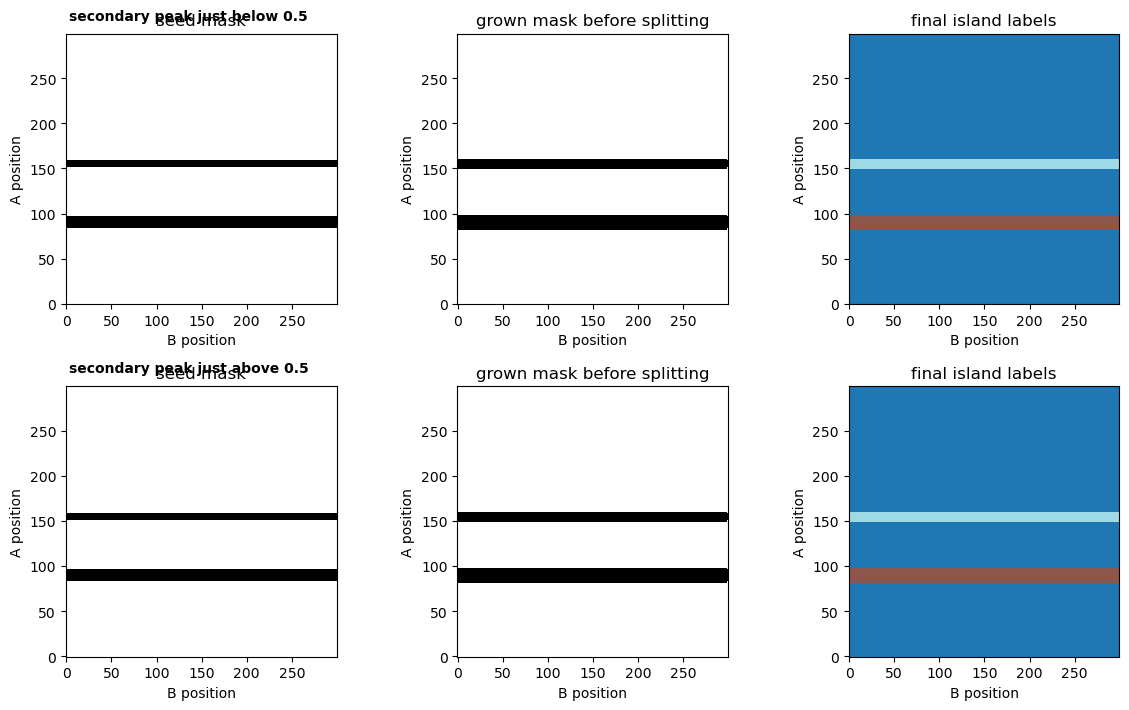

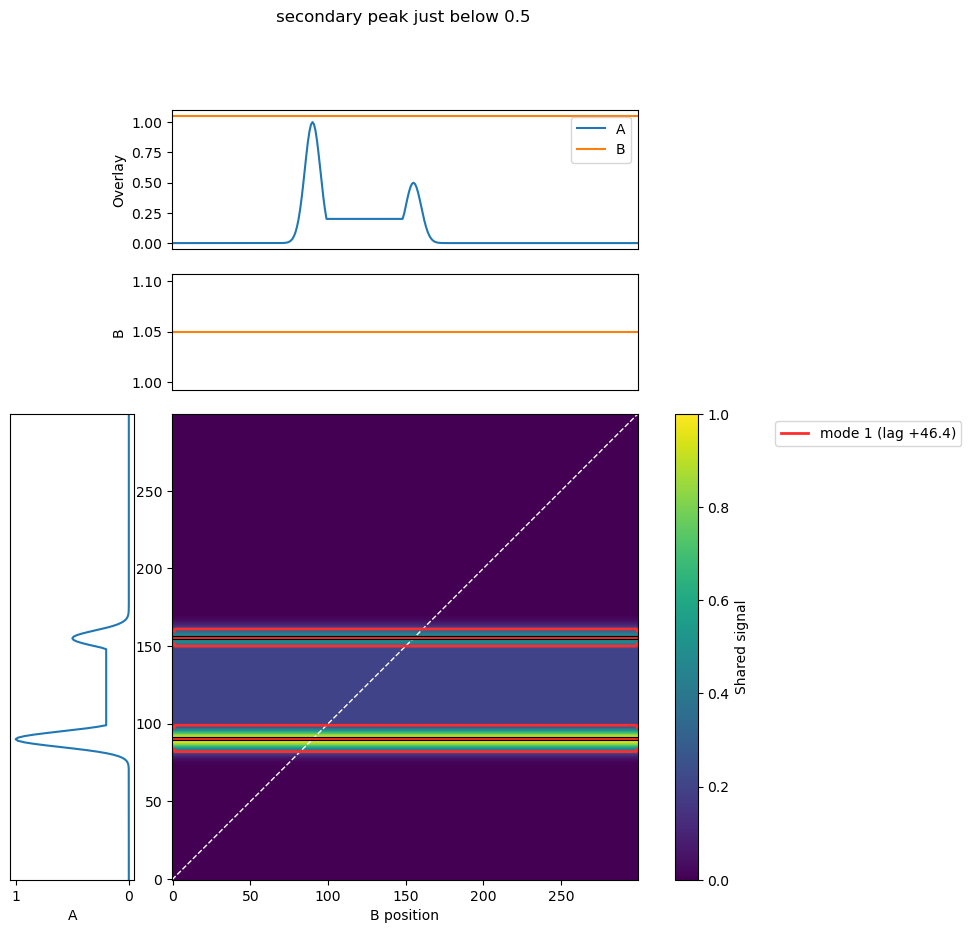

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,46.393485,"(1, 2)","(1,)",2,1,168.094669,210.549619,1.0,True,1.0


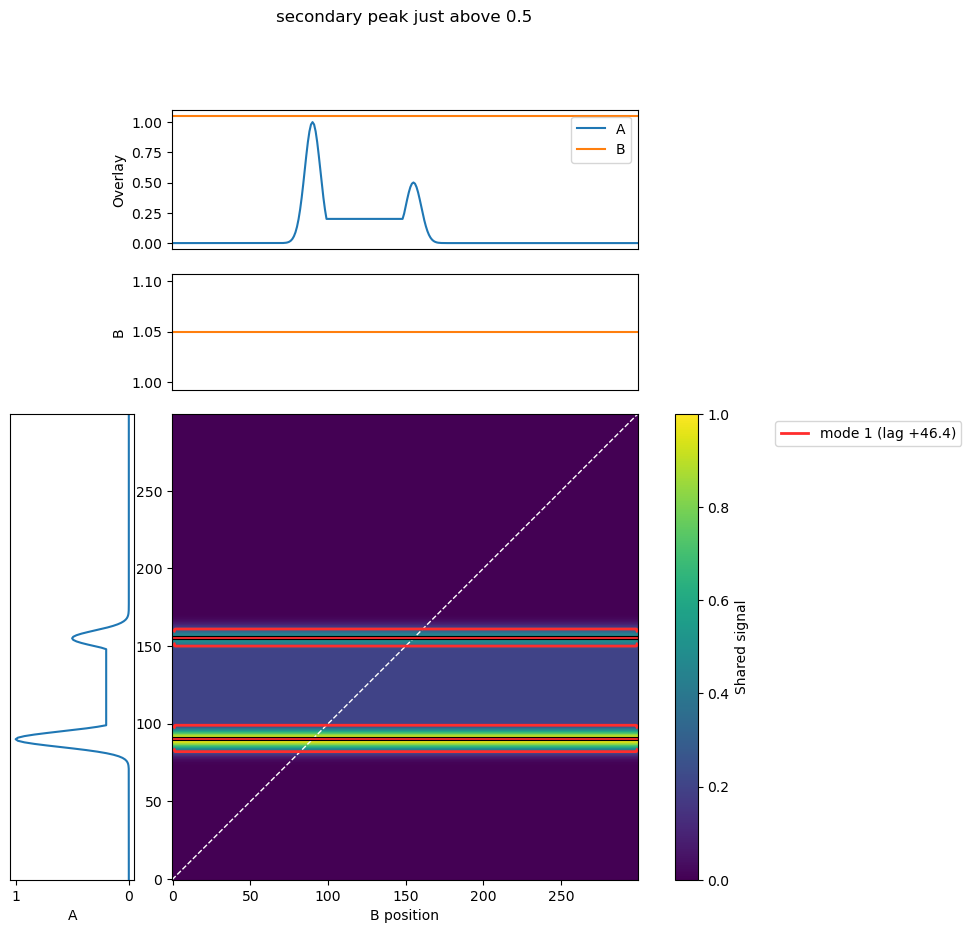

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,46.35158,"(1, 2)","(1,)",2,1,168.094669,210.719779,1.0,True,1.0


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,peak centers 7 positions apart,1,1,1,1,0,retained,central_mode_won_conflicts,"(1.0,)"
1,peak centers 9 positions apart,1,1,1,1,0,retained,central_mode_won_conflicts,"(0.0,)"


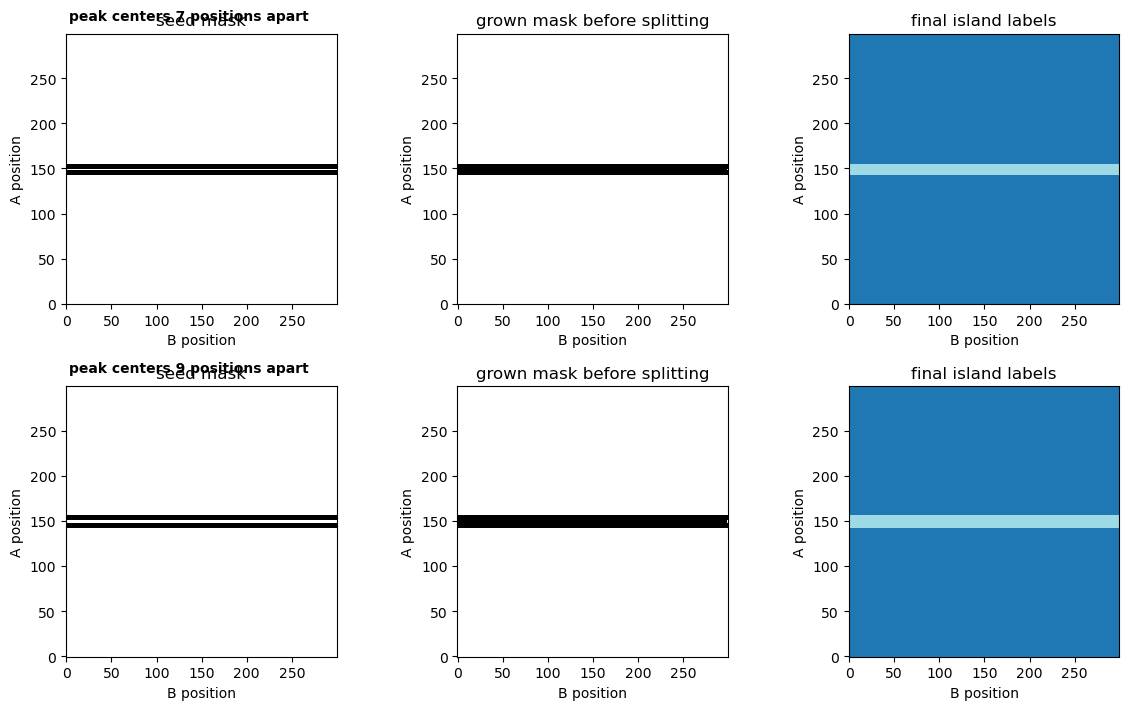

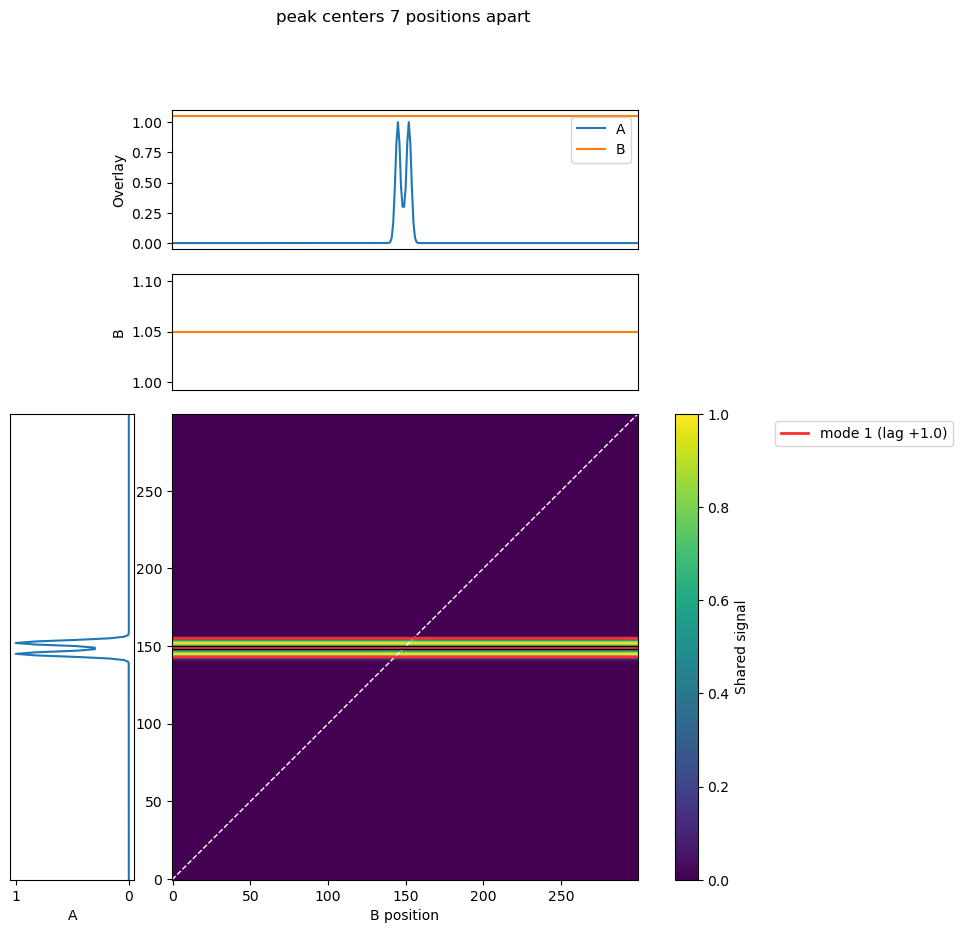

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,1.0,"(1,)","(1,)",1,1,79.018412,79.018412,1.0,True,0.0


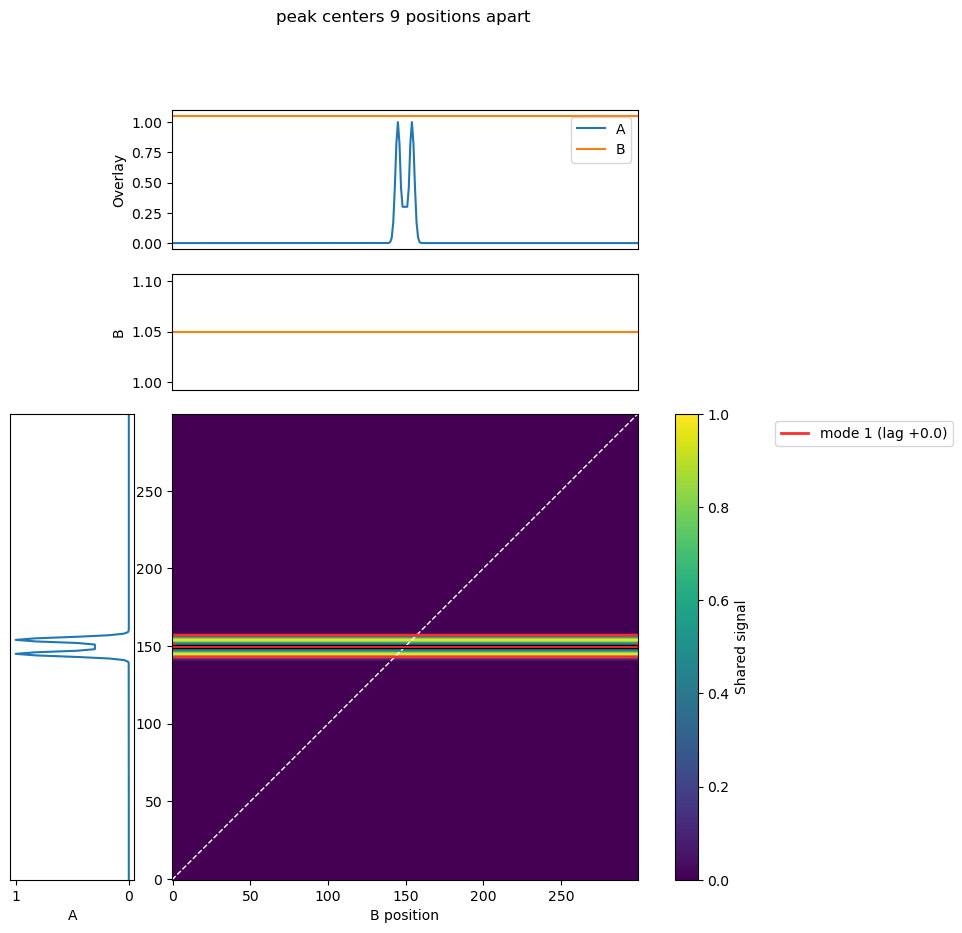

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,0.0,"(1,)","(1,)",1,1,99.856758,99.856758,1.0,True,0.0


In [9]:
split_b = np.full(N, 1.05)
split_fraction_cases = [
    {"label": "secondary peak just below 0.5", "a": bridged_peaks(N, 90, 155, 5, 1.0, 0.499, 0.20), "b": split_b},
    {"label": "secondary peak just above 0.5", "a": bridged_peaks(N, 90, 155, 5, 1.0, 0.501, 0.20), "b": split_b},
]
split_fraction_results = run_cases(split_fraction_cases, island_parameters)

distance_cases = [
    {"label": "peak centers 7 positions apart", "a": bridged_peaks(N, 145, 152, 1.6, 1.0, 1.0, 0.30), "b": split_b},
    {"label": "peak centers 9 positions apart", "a": bridged_peaks(N, 145, 154, 1.6, 1.0, 1.0, 0.30), "b": split_b},
]
distance_results = run_cases(distance_cases, island_parameters)

### 4.5 Minimum child seed area

This keeps the signal fixed and moves only the guard from 4 to the configured value of 5. It exposes whether a one-cell change in seed support can suppress an otherwise convincing split.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,same window with split_min_seed_area=4,2,2,1,1,0,absent,None,"(20.5,)"
1,same window with configured split_min_seed_area=5,2,2,1,1,0,absent,None,"(20.5,)"


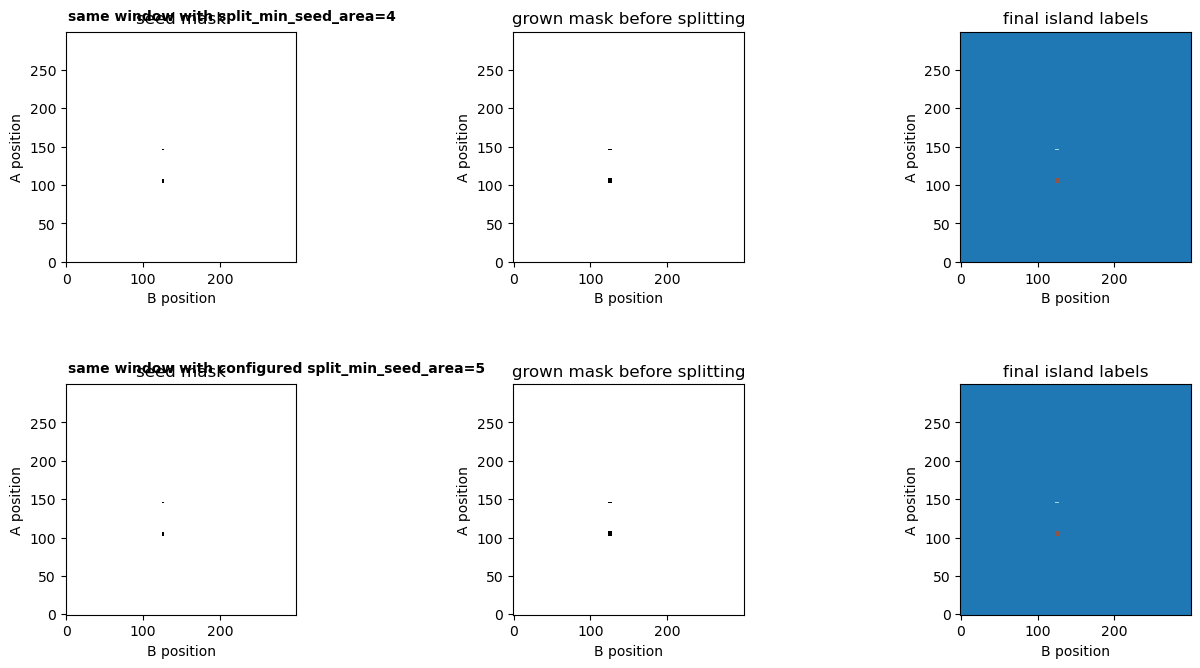

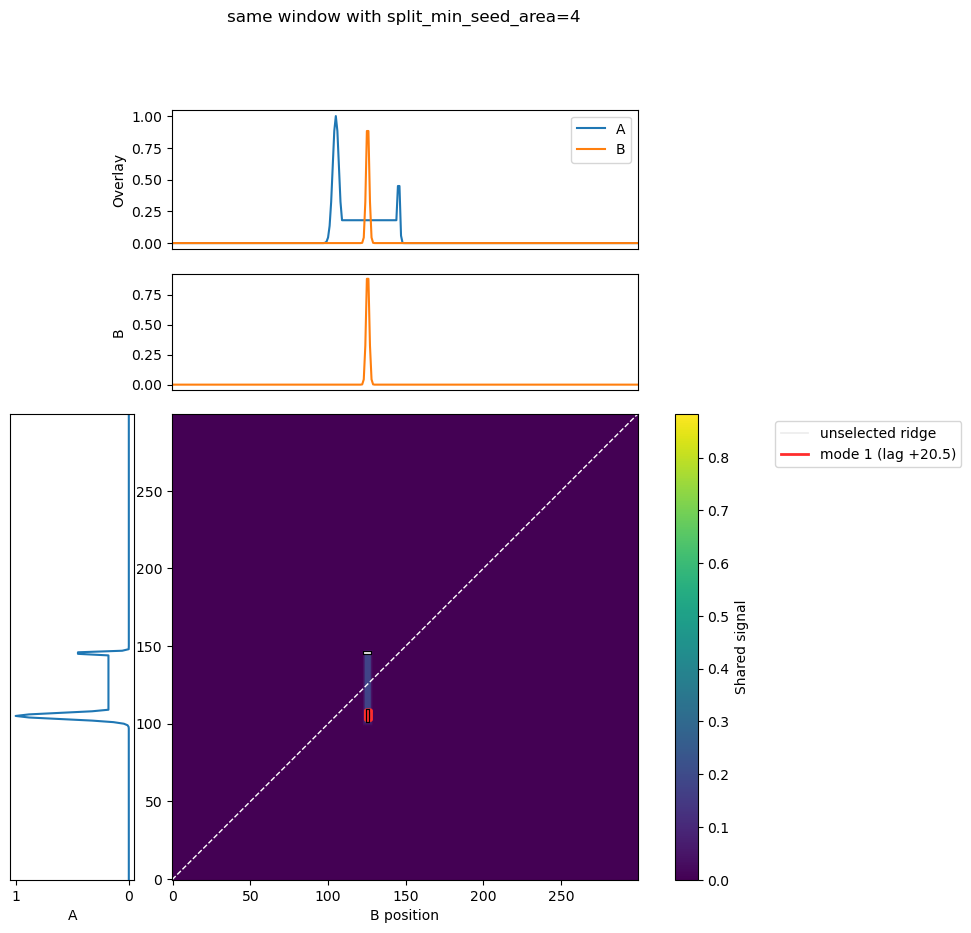

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-20.0,"(2,)","(2,)",1,1,1.495382,1.495382,0.198393,False,0.0
1,2,20.5,"(1,)","(1,)",1,1,7.537460,7.537460,1.000000,False,0.0


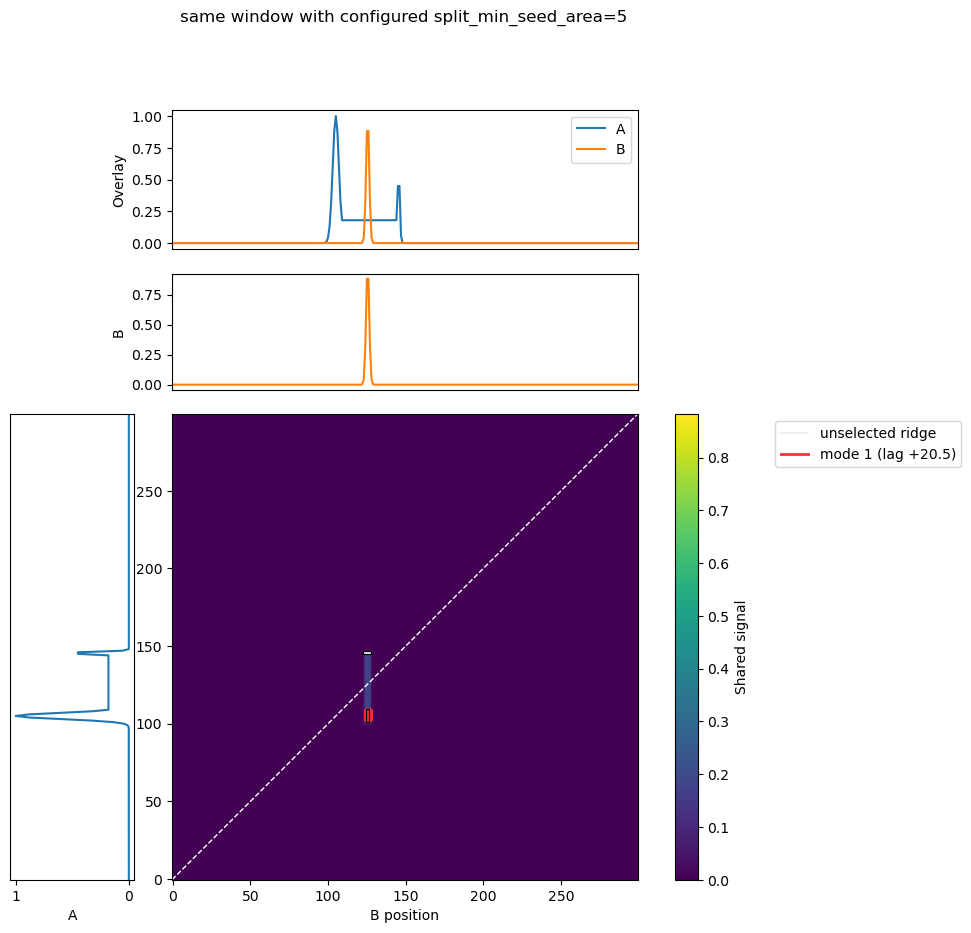

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-20.0,"(2,)","(2,)",1,1,1.495382,1.495382,0.198393,False,0.0
1,2,20.5,"(1,)","(1,)",1,1,7.537460,7.537460,1.000000,False,0.0


In [10]:
seed_area_a = peak_track(N, [(105, 2.0, 1.0), (145.5, 0.7, 0.58)])
seed_area_a[105:147] = np.maximum(seed_area_a[105:147], 0.18)
seed_area_b = peak_track(N, [(125.5, 1.0, 1.0)])
seed_area_cases = [
    {"label": "same window with split_min_seed_area=4", "a": seed_area_a, "b": seed_area_b, "overrides": {"split_min_seed_area": 4}},
    {"label": "same window with configured split_min_seed_area=5", "a": seed_area_a, "b": seed_area_b},
]
seed_area_results = run_cases(seed_area_cases, island_parameters)

## 5. Ridge and mode cutoffs

### 5.1 Zero-lag corridor: displacement 5 versus 6


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,shared displacement 5,9,5,1,3,6,retained,central_mode_won_conflicts,"(5.0,)"
1,shared displacement 6,9,5,1,3,6,retained,central_mode_won_conflicts,"(6.0,)"


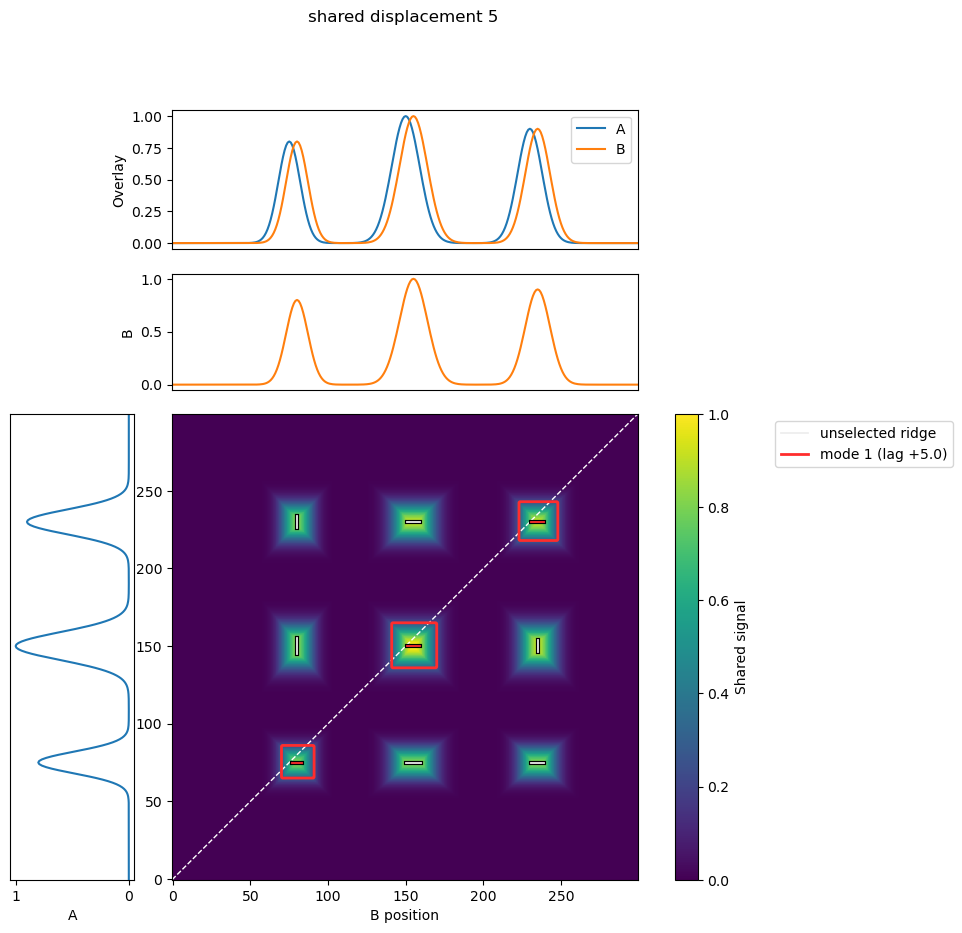

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-150.000000,"(7,)","(7,)",1,1,216.934438,216.934438,0.215012,False,0.0
1,2,-73.009615,"(8, 4)","(4, 8)",2,2,552.944707,552.944707,0.548045,False,0.0
2,3,5.000000,"(1, 5, 9)","(1, 5, 9)",3,3,1008.940308,1008.940308,1.000000,True,0.0
3,4,83.009615,"(2, 6)","(2, 6)",2,2,552.944681,552.944681,0.548045,False,0.0
4,5,160.000000,"(3,)","(3,)",1,1,216.934464,216.934464,0.215012,False,0.0


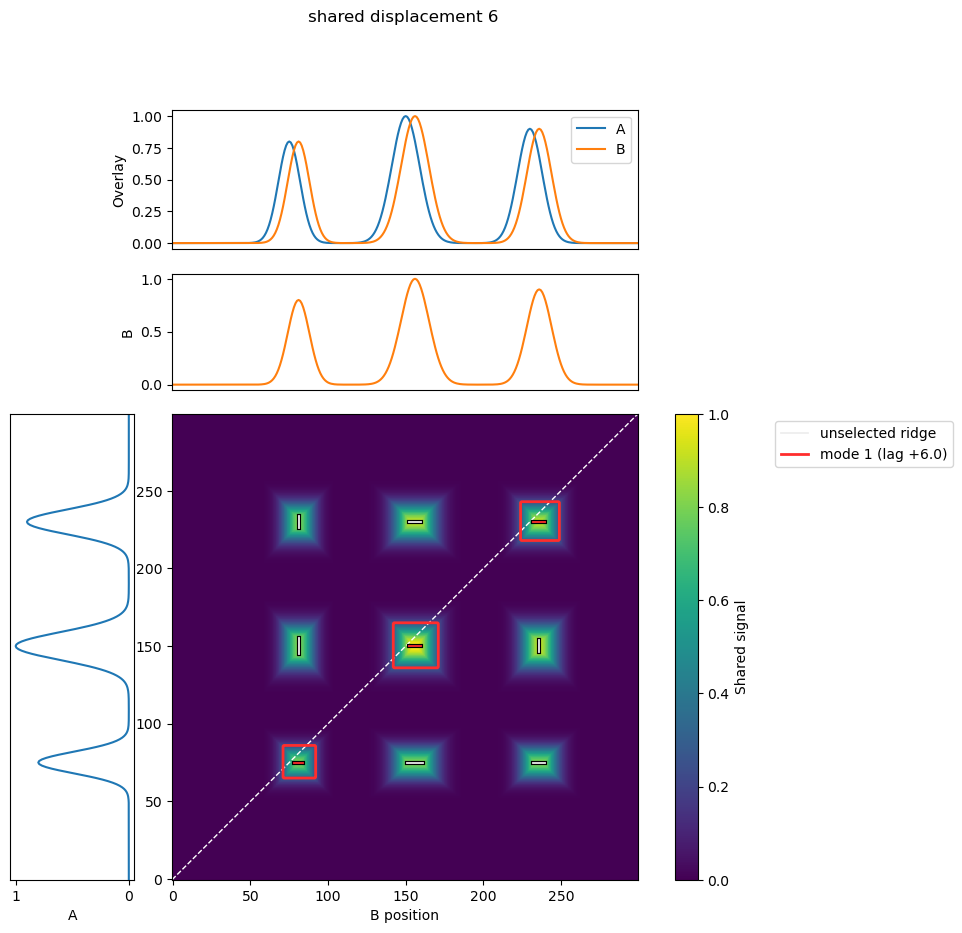

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-149.000000,"(7,)","(7,)",1,1,216.934438,216.934438,0.215012,False,0.0
1,2,-72.009615,"(8, 4)","(4, 8)",2,2,552.944707,552.944707,0.548045,False,0.0
2,3,6.000000,"(1, 5, 9)","(1, 5, 9)",3,3,1008.940308,1008.940308,1.000000,True,0.0
3,4,84.009615,"(2, 6)","(2, 6)",2,2,552.944681,552.944681,0.548045,False,0.0
4,5,161.000000,"(3,)","(3,)",1,1,216.934464,216.934464,0.215012,False,0.0


In [11]:
zero_lag_cases = []
for displacement in (5, 6):
    a, b = shifted_peak_pair(N, [75, 150, 230], [7, 9, 8], [0.8, 1.0, 0.9], [displacement] * 3, baseline=0.0)
    zero_lag_cases.append({"label": f"shared displacement {displacement}", "a": a, "b": b})
zero_lag_results = run_cases(zero_lag_cases, island_parameters, show_stages=False)

### 5.2 Mode lag tolerance: lag difference 5 versus 6

Both windows contain two clean correspondences. The only change is whether their displacements fall inside the configured mode radius.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,lags 20 and 25,4,3,3,4,0,absent,None,"(-110.0, 22.5, 155.0)"
1,lags 20 and 26,4,4,4,4,0,absent,None,"(-110.0, 20.0, 26.0, 156.0)"


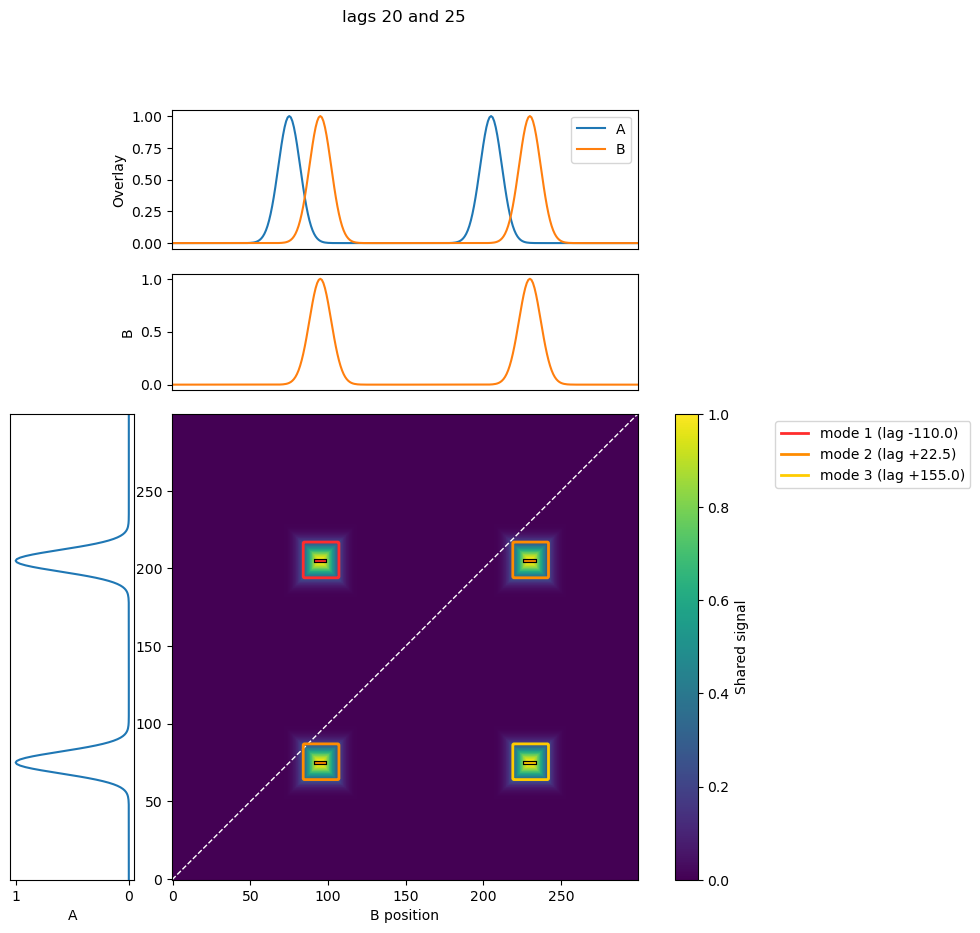

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-110.0,"(3,)","(3,)",1,1,290.805786,290.805786,0.5,False,0.0
1,2,22.5,"(1, 4)","(1, 4)",2,2,581.611572,581.611572,1.0,False,0.0
2,3,155.0,"(2,)","(2,)",1,1,290.805786,290.805786,0.5,False,0.0


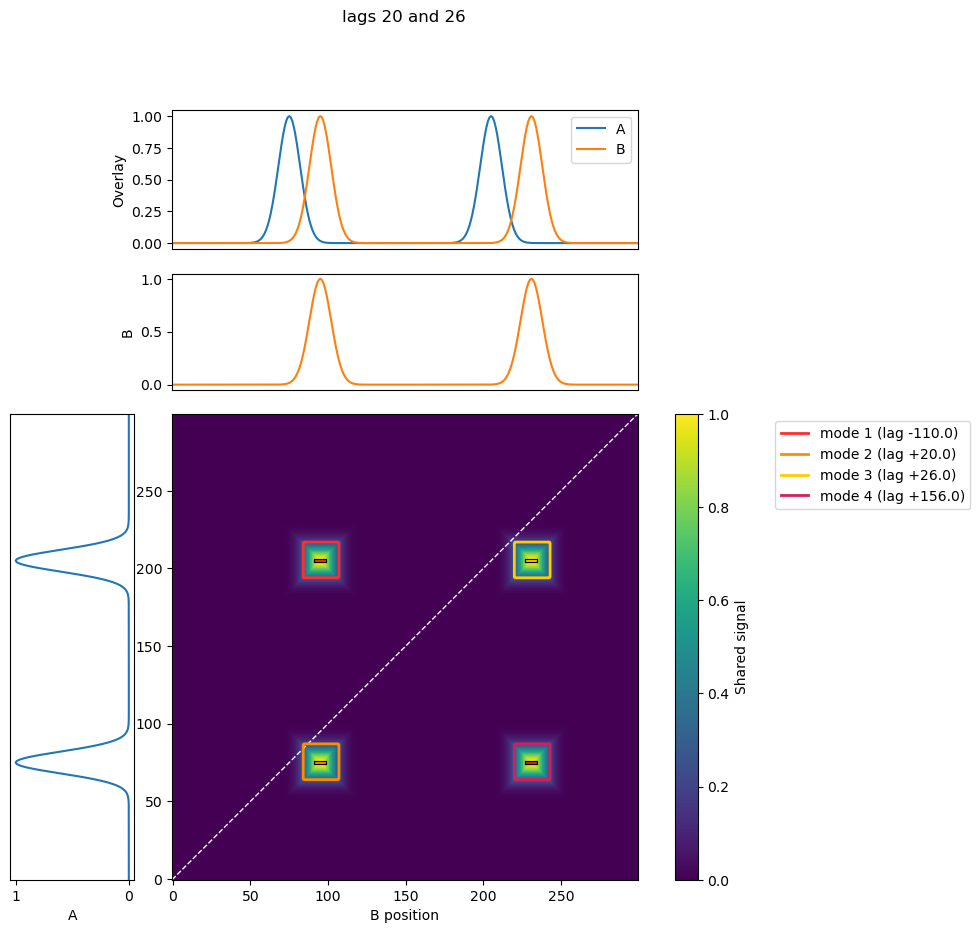

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-110.0,"(3,)","(3,)",1,1,290.805786,290.805786,1.0,False,0.0
1,2,20.0,"(1,)","(1,)",1,1,290.805786,290.805786,1.0,False,0.0
2,3,26.0,"(4,)","(4,)",1,1,290.805786,290.805786,1.0,False,0.0
3,4,156.0,"(2,)","(2,)",1,1,290.805786,290.805786,1.0,False,0.0


In [12]:
mode_lag_cases = []
for second_shift in (25, 26):
    a, b = shifted_peak_pair(N, [75, 205], [7, 7], [1.0, 1.0], [20, second_shift], baseline=0.0)
    mode_lag_cases.append({"label": f"lags 20 and {second_shift}", "a": a, "b": b})
mode_lag_results = run_cases(mode_lag_cases, island_parameters, show_stages=False)

### 5.3 Displaced-mode takeover: immediately below and above 2-fold

The calibration search compensates for ridge geometry and shape-adjusted scoring, so the displayed cases straddle the *measured* score ratio rather than merely assuming amplitude is proportional to score.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,measured displaced/central=1.883 (height=0.575),2,2,1,1,1,retained,central_mode_won_conflicts,"(0.0,)"
1,measured displaced/central=1.883 (height=0.575),2,2,1,1,1,retained,central_mode_won_conflicts,"(0.0,)"


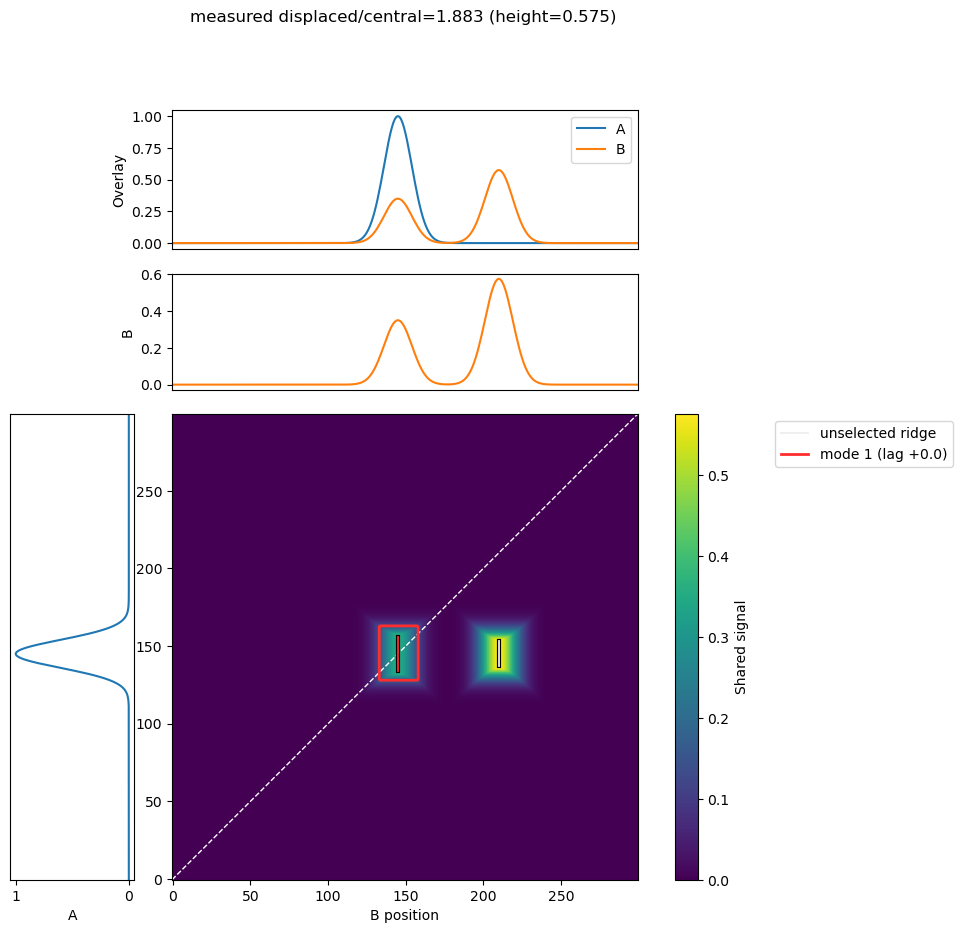

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,0.0,"(1,)","(1,)",1,1,154.500448,154.500448,0.531197,True,0.0
1,2,65.0,"(2,)","(2,)",1,1,290.853501,290.853501,1.000000,False,0.0


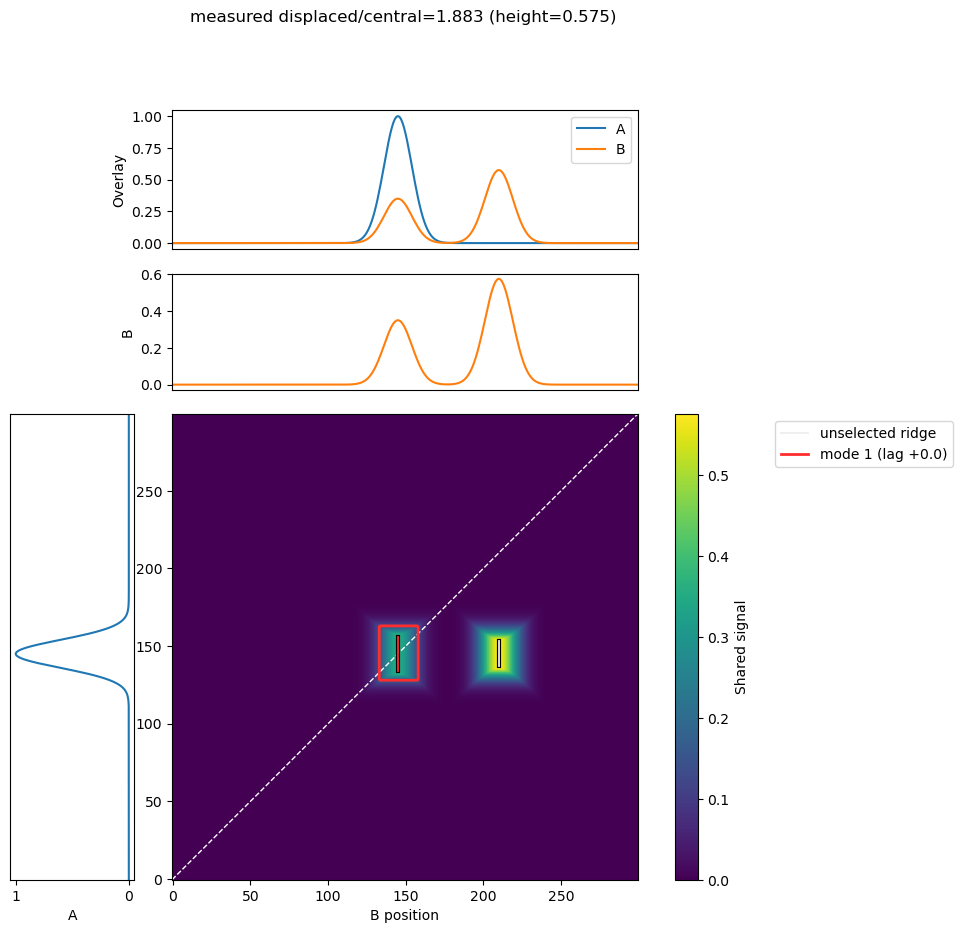

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,0.0,"(1,)","(1,)",1,1,154.500448,154.500448,0.531197,True,0.0
1,2,65.0,"(2,)","(2,)",1,1,290.853501,290.853501,1.000000,False,0.0


In [13]:
fold_search = np.linspace(0.45, 1.15, 141)
fold_low = find_case_near_metric(fold_competition_pair, fold_search, 1.98, displaced_to_central_ratio, island_parameters, {"n": N})
fold_high = find_case_near_metric(fold_competition_pair, fold_search, 2.02, displaced_to_central_ratio, island_parameters, {"n": N})
fold_cases = [
    {"label": f"measured displaced/central={fold_low[2]:.3f} (height={fold_low[1]:.3f})", "a": fold_low[3], "b": fold_low[4]},
    {"label": f"measured displaced/central={fold_high[2]:.3f} (height={fold_high[1]:.3f})", "a": fold_high[3], "b": fold_high[4]},
]
fold_results = run_cases(fold_cases, island_parameters, show_stages=False)

### 5.4 Mode retention: immediately below and above 0.33 of the strongest mode


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,weaker mode fraction=0.339 (height=0.470),2,2,2,2,0,absent,None,"(-65.0, 65.0)"
1,weaker mode fraction=0.339 (height=0.470),2,2,2,2,0,absent,None,"(-65.0, 65.0)"


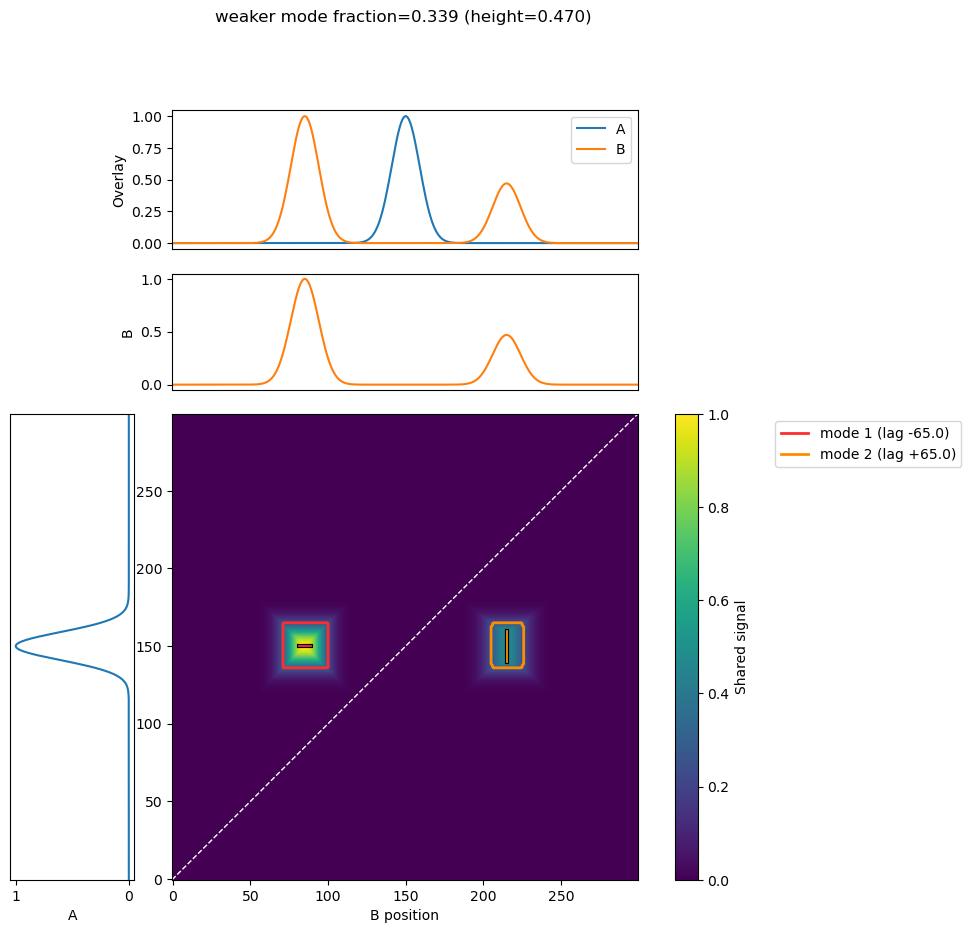

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-65.0,"(1,)","(1,)",1,1,471.495819,471.495819,1.000000,False,0.0
1,2,65.0,"(2,)","(2,)",1,1,159.715426,159.715426,0.338742,False,0.0


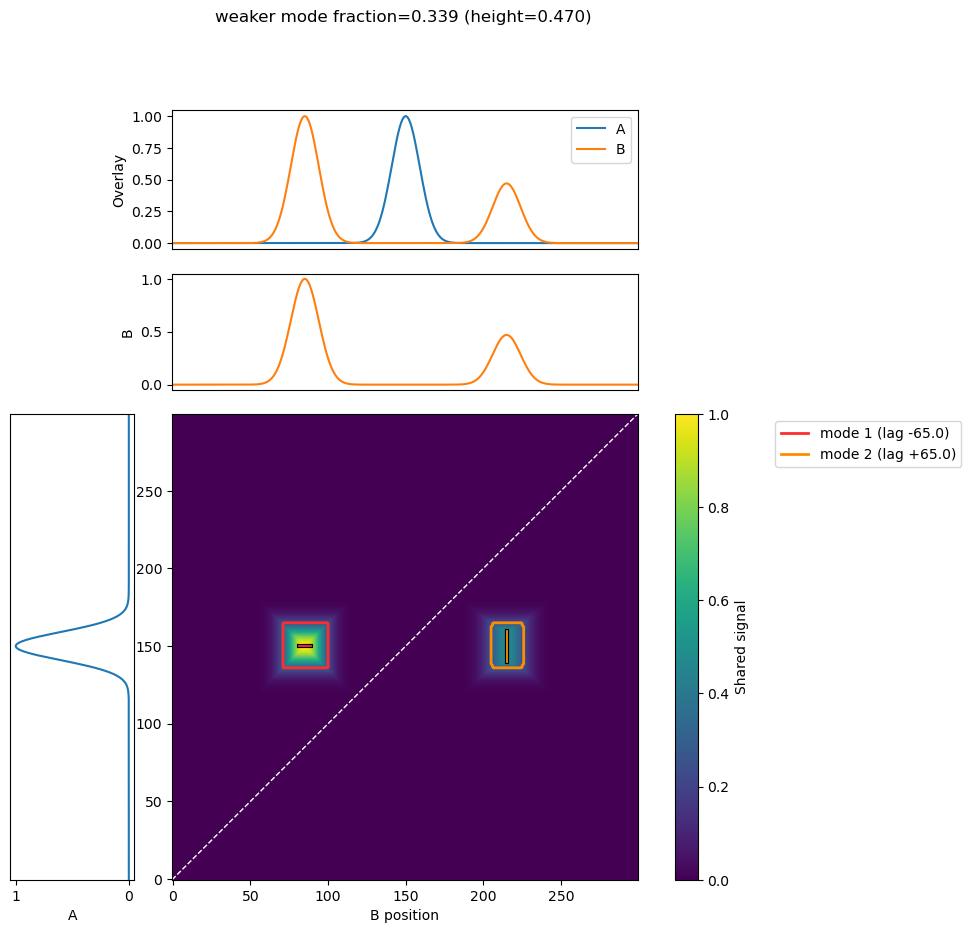

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-65.0,"(1,)","(1,)",1,1,471.495819,471.495819,1.000000,False,0.0
1,2,65.0,"(2,)","(2,)",1,1,159.715426,159.715426,0.338742,False,0.0


In [14]:
fraction_search = np.linspace(0.15, 0.75, 121)
fraction_low = find_case_near_metric(mode_fraction_pair, fraction_search, 0.32, weaker_mode_fraction, island_parameters, {"n": N})
fraction_high = find_case_near_metric(mode_fraction_pair, fraction_search, 0.34, weaker_mode_fraction, island_parameters, {"n": N})
fraction_cases = [
    {"label": f"weaker mode fraction={fraction_low[2]:.3f} (height={fraction_low[1]:.3f})", "a": fraction_low[3], "b": fraction_low[4]},
    {"label": f"weaker mode fraction={fraction_high[2]:.3f} (height={fraction_high[1]:.3f})", "a": fraction_high[3], "b": fraction_high[4]},
]
fraction_results = run_cases(fraction_cases, island_parameters, show_stages=False)

## 6. Geometry traps


### 6.1 Bumpy long ridge and ridge-fraction sensitivity

The ridge should follow the long side. Small bumps should not cause a transverse ridge or truncate the crest implausibly.

,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,bumpy ridge at ridge_fraction=0.88,1,1,1,1,0,retained,central_mode_won_conflicts,"(0.52,)"
1,bumpy ridge at configured ridge_fraction=0.90,1,1,1,1,0,retained,central_mode_won_conflicts,"(0.52,)"
2,bumpy ridge at ridge_fraction=0.92,1,1,1,1,0,retained,central_mode_won_conflicts,"(0.51,)"


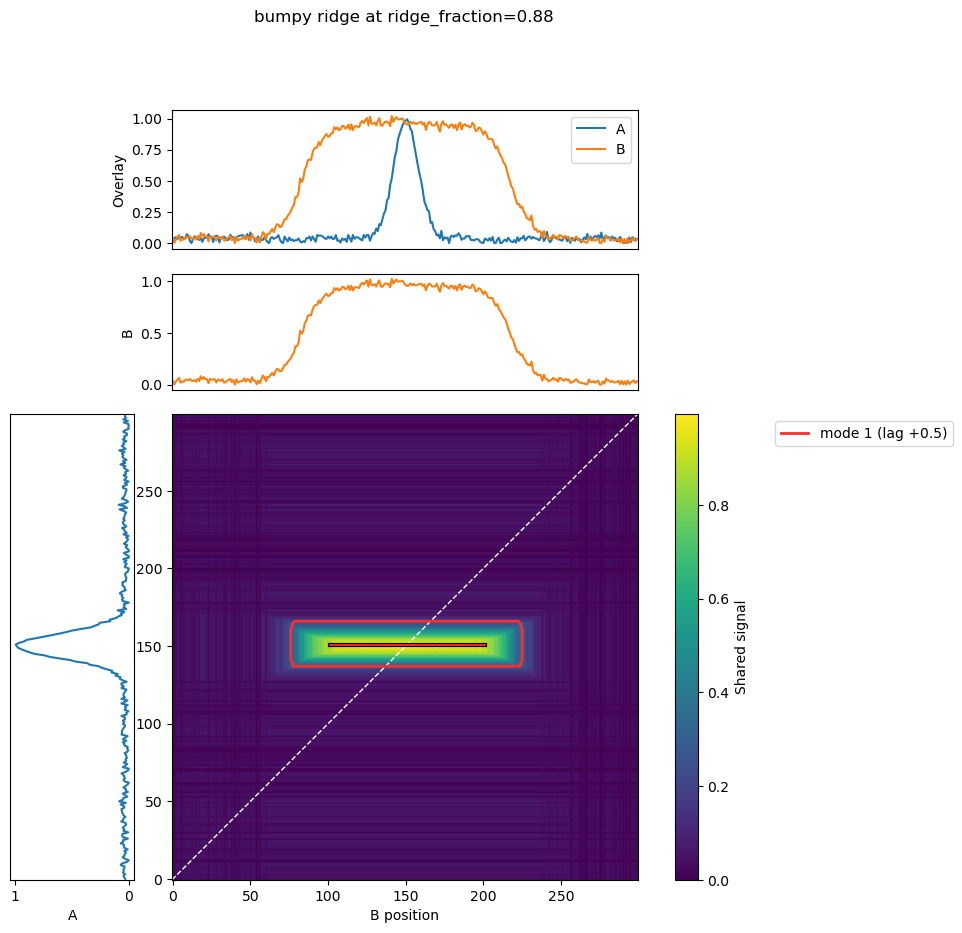

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,0.51622,"(1,)","(1,)",1,1,461.962422,461.962422,1.0,True,0.0


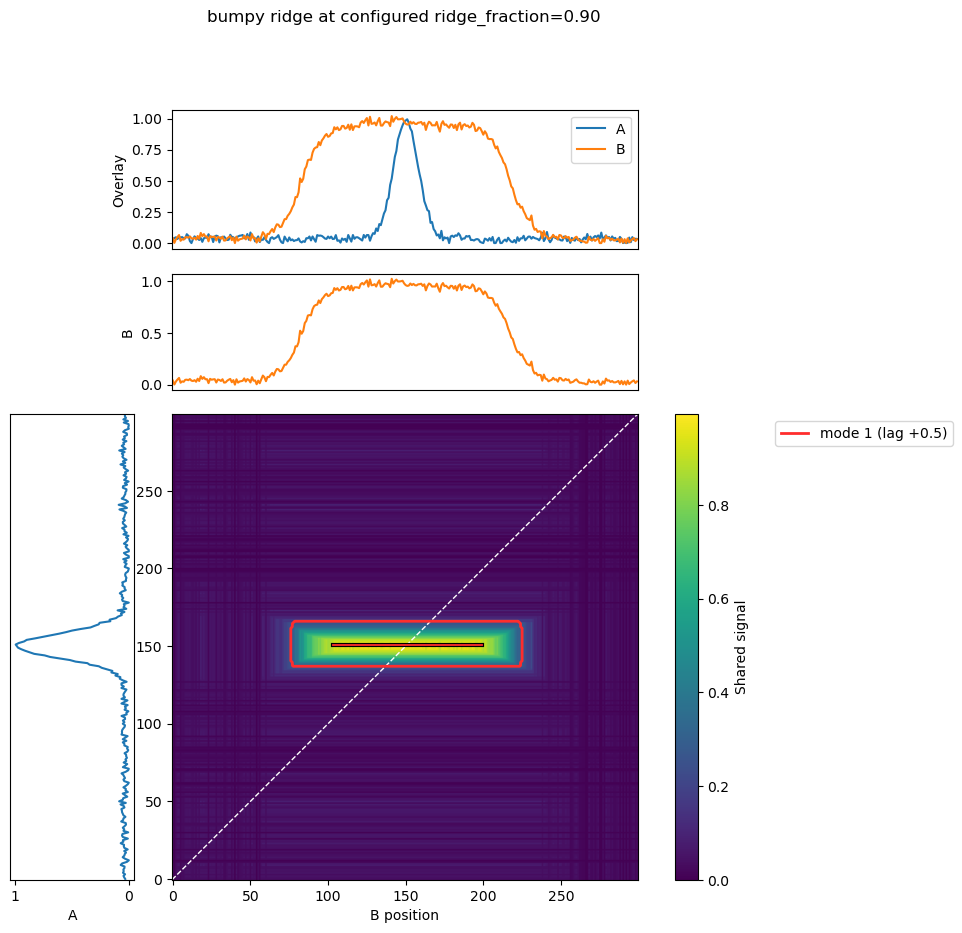

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,0.51622,"(1,)","(1,)",1,1,461.962422,461.962422,1.0,True,0.0


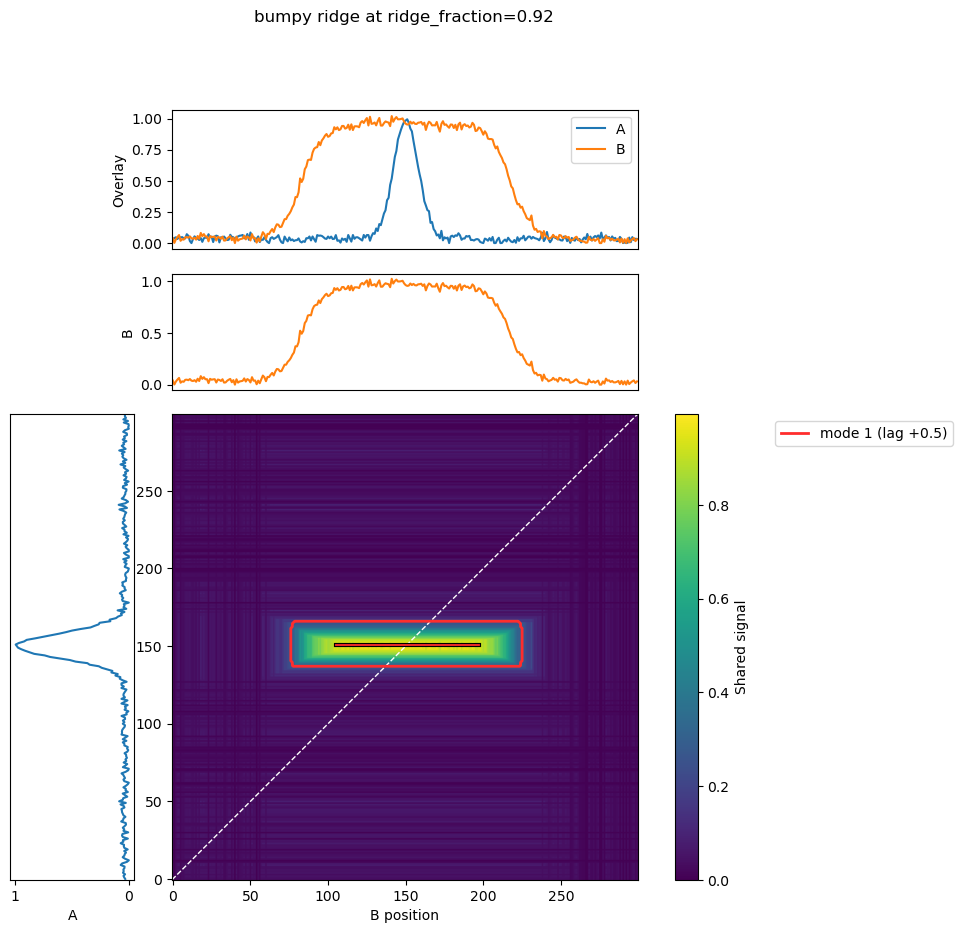

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,0.512498,"(1,)","(1,)",1,1,461.962422,461.962422,1.0,True,0.0


In [27]:
ridge_rng = np.random.default_rng(SEED + 11)
ridge_a = peak_track(N, [(150, 8, 0.95)], baseline=0.03, noise_level=0.018, rng=ridge_rng)
ridge_b = plateau_track(N, [(150, 135, 7, 0.92)], baseline=0.03, noise_level=0.018, rng=ridge_rng)
ridge_cases = [
    {"label": "bumpy ridge at ridge_fraction=0.88", "a": ridge_a, "b": ridge_b, "overrides": {"ridge_fraction": 0.88}},
    {"label": "bumpy ridge at configured ridge_fraction=0.90", "a": ridge_a, "b": ridge_b},
    {"label": "bumpy ridge at ridge_fraction=0.92", "a": ridge_a, "b": ridge_b, "overrides": {"ridge_fraction": 0.92}},
]
ridge_results = run_cases(ridge_cases, island_parameters, show_stages=False)

### 6.2 Width mismatch and shape-balance penalty

The peak centers and heights are fixed while B becomes progressively broader. This reveals how much the score drops purely from rectangle geometry.


,B width,A island width,B island width,shape balance,total support,adjusted score
0,7,23,23,1.000000,290.805786,290.805786
1,12,23,39,0.589744,495.380493,284.534735
2,20,23,65,0.353846,823.325439,276.583799
3,35,23,105,0.219048,1382.962402,280.786250
4,60,23,173,0.132948,2318.444336,278.652211


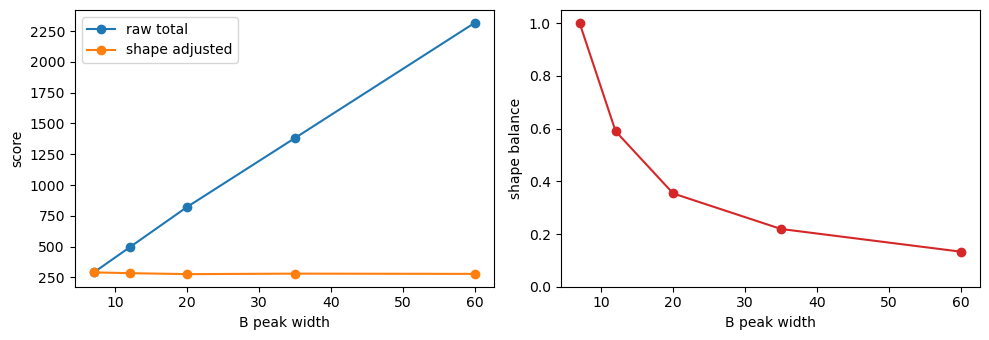

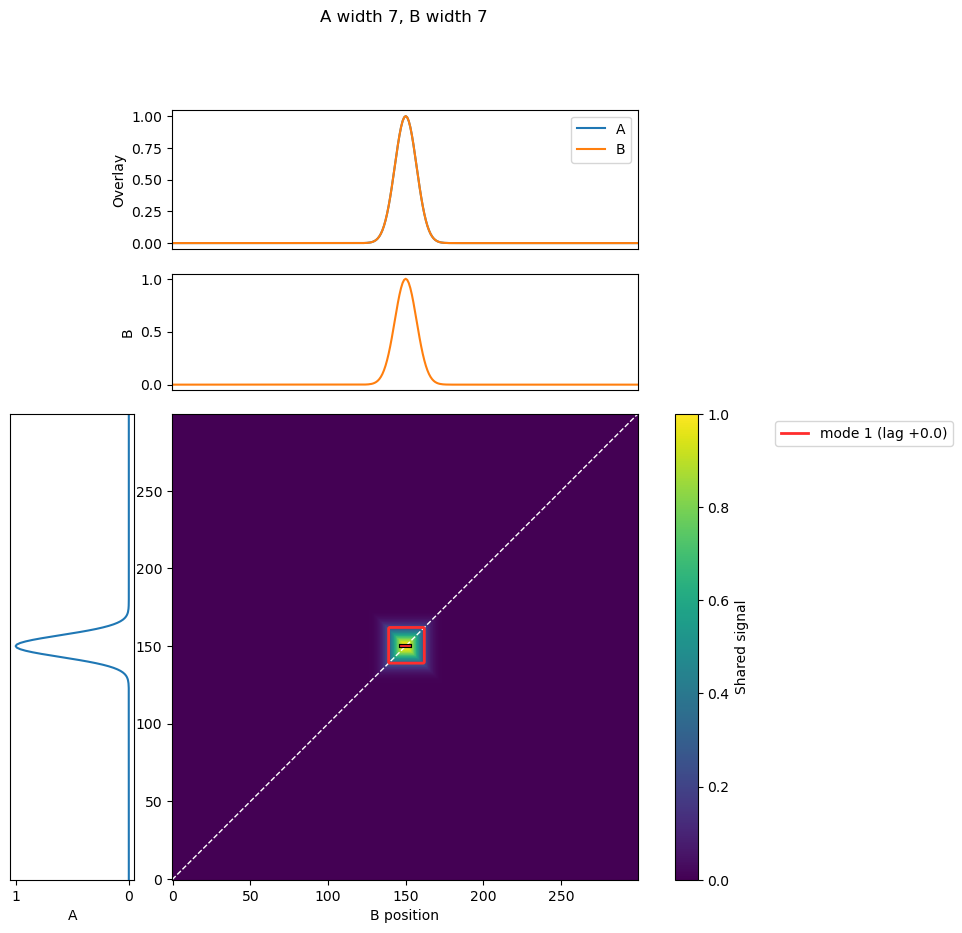

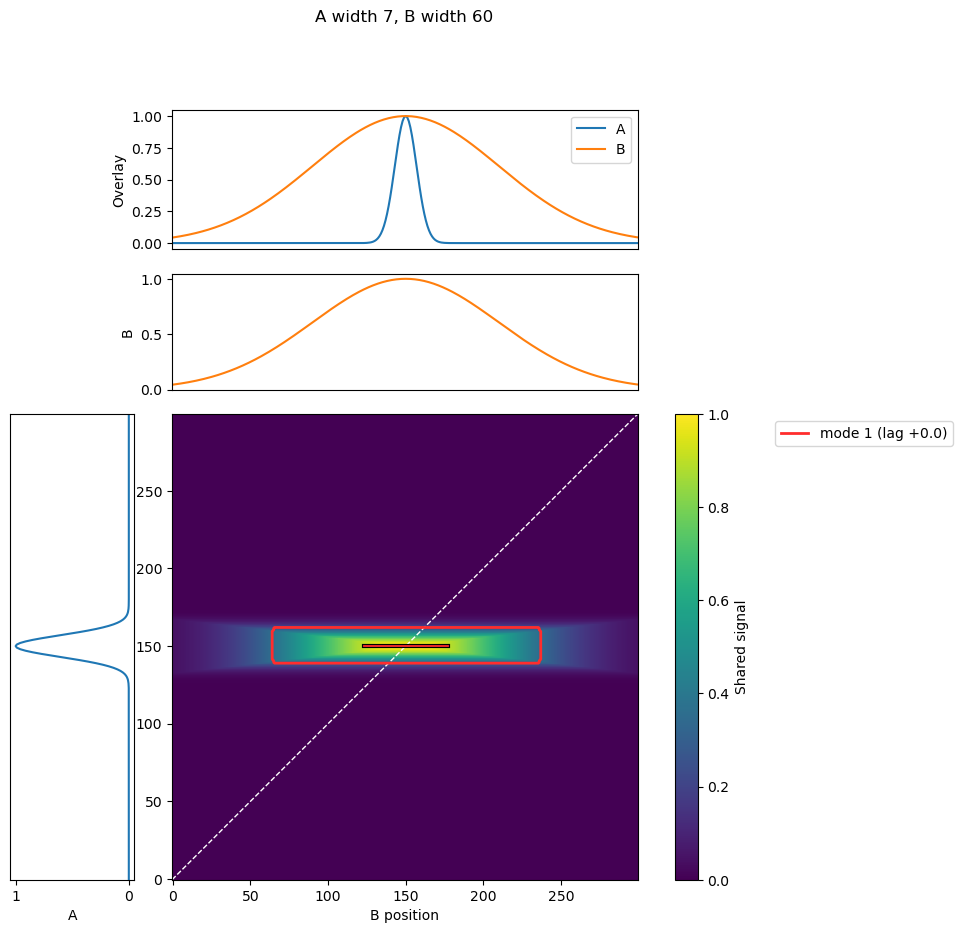

In [16]:
shape_results = []
for width_b in [7, 12, 20, 35, 60]:
    a = peak_track(N, [(150, 7, 1.0)])
    b = peak_track(N, [(150, width_b, 1.0)])
    shape_results.append(analyze_case(f"A width 7, B width {width_b}", a, b, island_parameters))

shape_rows = []
for width_b, result in zip([7, 12, 20, 35, 60], shape_results):
    strongest = max(result["islands"], key=lambda island: island["selection_score"])
    shape_rows.append({"B width": width_b, "A island width": strongest["A_width"], "B island width": strongest["B_width"],
                       "shape balance": strongest["shape_balance"], "total support": strongest["total_support"],
                       "adjusted score": strongest["selection_score"]})
shape_table = pd.DataFrame(shape_rows)
display(shape_table)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(shape_table["B width"], shape_table["total support"], "o-", label="raw total")
axes[0].plot(shape_table["B width"], shape_table["adjusted score"], "o-", label="shape adjusted")
axes[0].set(xlabel="B peak width", ylabel="score")
axes[0].legend()
axes[1].plot(shape_table["B width"], shape_table["shape balance"], "o-", color="C3")
axes[1].set(xlabel="B peak width", ylabel="shape balance", ylim=(0, 1.05))
plt.tight_layout()
plt.show()
for result in (shape_results[0], shape_results[-1]):
    utils.plot_simulated_islands(result, title=result["stress_label"])
### Implies that we are slightly overtuning the shape adjustment power. 

### 6.3 Broad pillars and contained alternatives

The first case should retain all three visual pillars in one central mode while allowing only independent ridges to contribute duplicate-free score. The second is less extreme: two narrow peaks sit inside a broad peak, with another correspondence elsewhere.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,three pillars from edge-to-edge A,3,1,1,3,0,retained,central_mode_won_conflicts,"(9.82,)"
1,two narrow peaks inside one broad peak plus an...,6,4,1,3,3,retained,central_mode_won_conflicts,"(0.0,)"


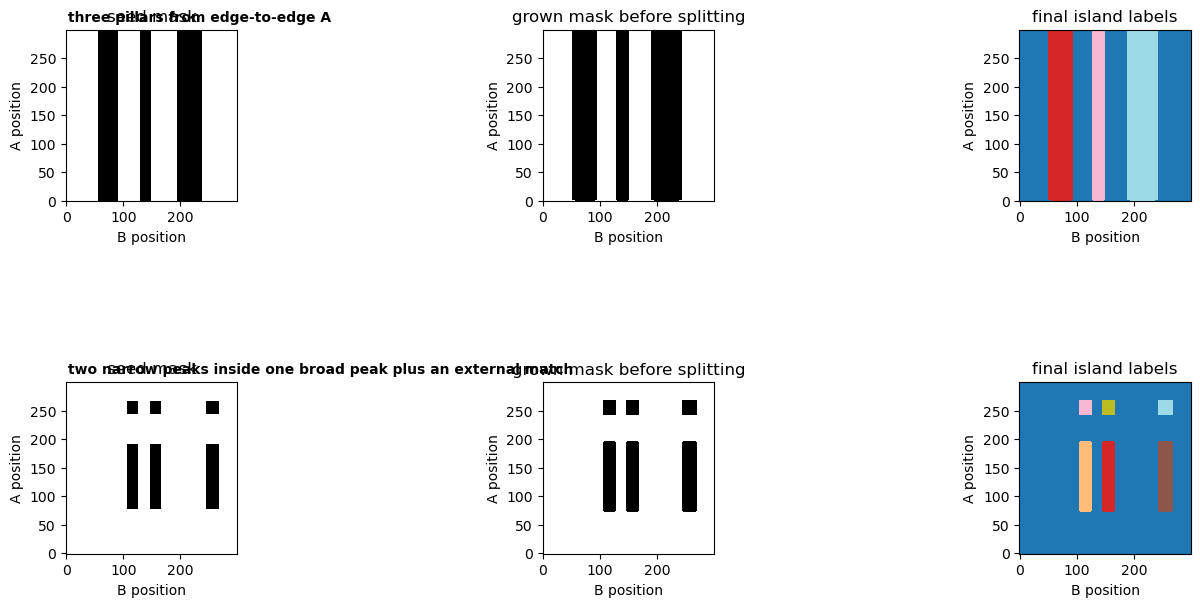

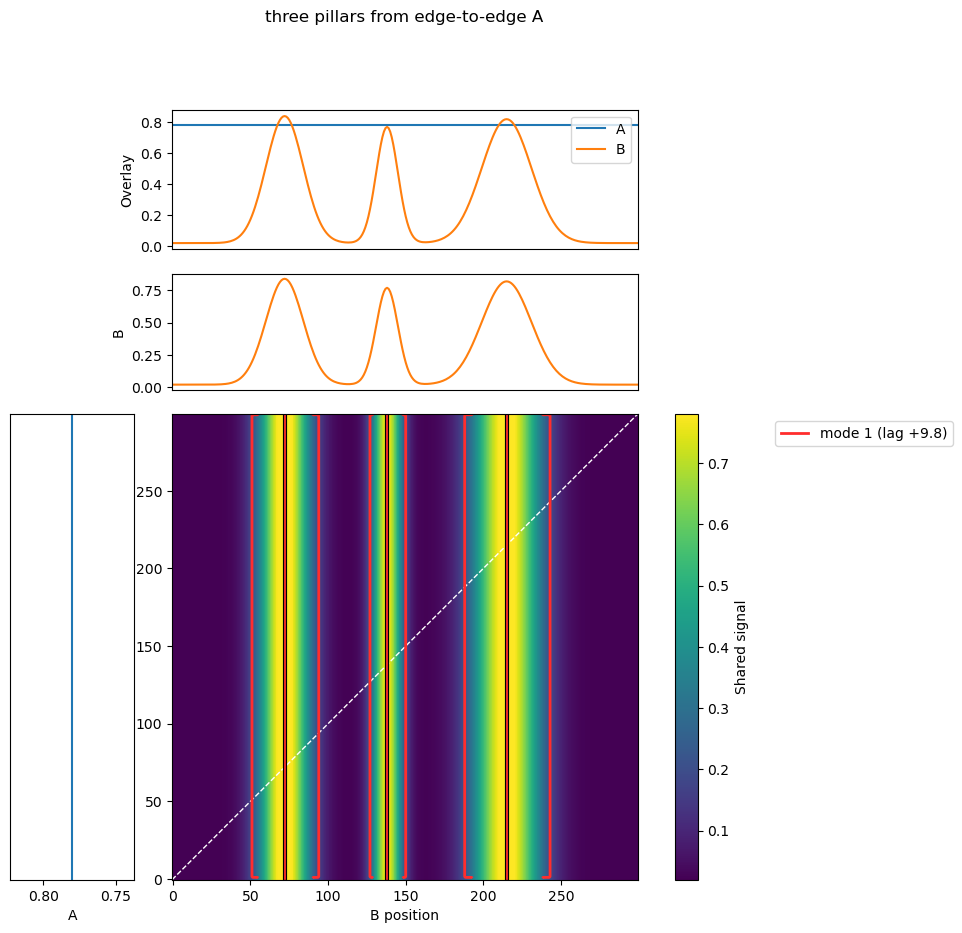

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,9.822348,"(1, 2, 3)","(3,)",3,1,1523.38652,2682.704793,1.0,True,1.0


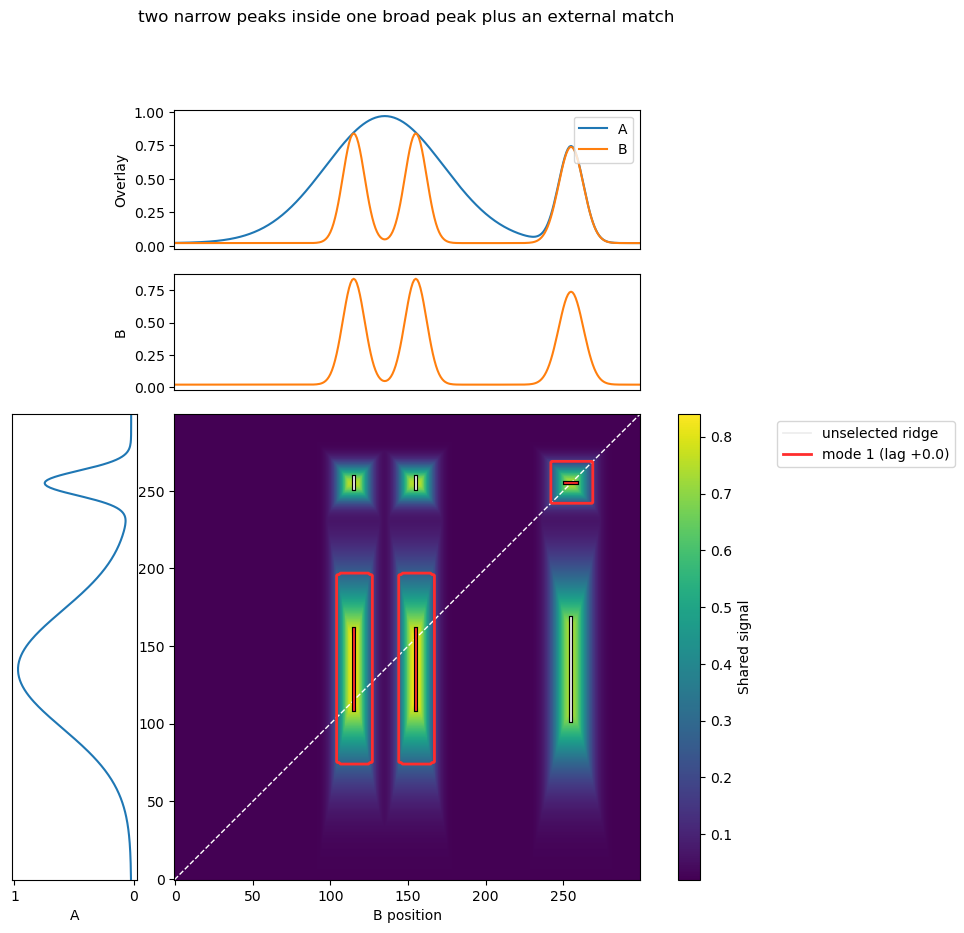

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-139.999999,"(4,)","(4,)",1,1,229.092501,229.092501,0.423048,False,0.000000
1,2,-100.000001,"(5,)","(5,)",1,1,229.092501,229.092501,0.423048,False,0.000000
2,3,0.001056,"(1, 2, 6)","(1, 6)",3,2,541.528805,785.408195,1.000000,True,0.333333
3,4,120.000000,"(3,)","(3,)",1,1,306.160492,306.160492,0.565363,False,0.000000


In [17]:
pillar_a = np.full(N, 0.78)
pillar_b = peak_track(N, [(72, 12, 0.82), (138, 7, 0.75), (215, 16, 0.80)], baseline=0.02)
contained_a = peak_track(N, [(135, 38, 0.95), (255, 8, 0.72)], baseline=0.02)
contained_b = peak_track(N, [(115, 7, 0.82), (155, 7, 0.82), (255, 8, 0.72)], baseline=0.02)
pillar_cases = [
    {"label": "three pillars from edge-to-edge A", "a": pillar_a, "b": pillar_b},
    {"label": "two narrow peaks inside one broad peak plus an external match", "a": contained_a, "b": contained_b},
]
pillar_results = run_cases(pillar_cases, island_parameters)

### 6.4 Window-edge clipping

The same displacement is applied to a centered peak and an edge-clipped peak. The edge case tests whether truncation changes ridge lag, shape balance, or mode retention in a surprising way.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,"center=150, displacement=18",1,1,1,1,0,absent,None,"(18.0,)"
1,"center=8, displacement=18",1,1,1,1,0,absent,None,"(18.0,)"


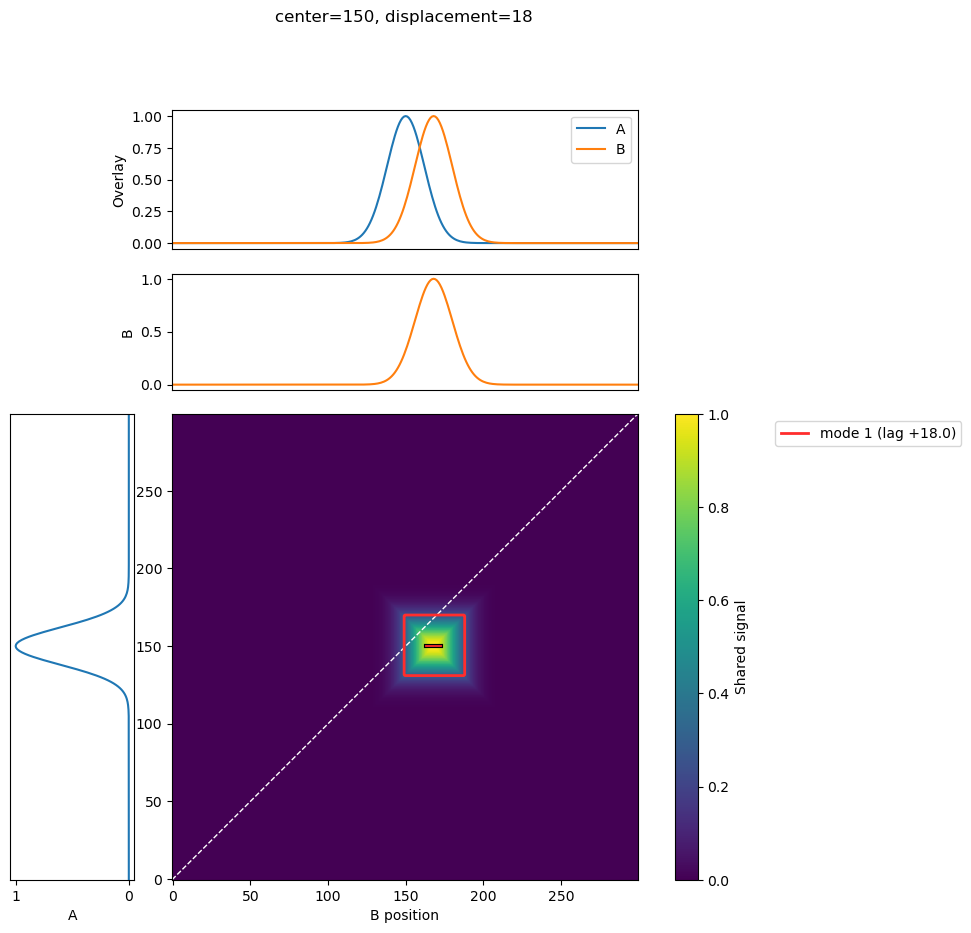

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,18.0,"(1,)","(1,)",1,1,844.835571,844.835571,1.0,False,0.0


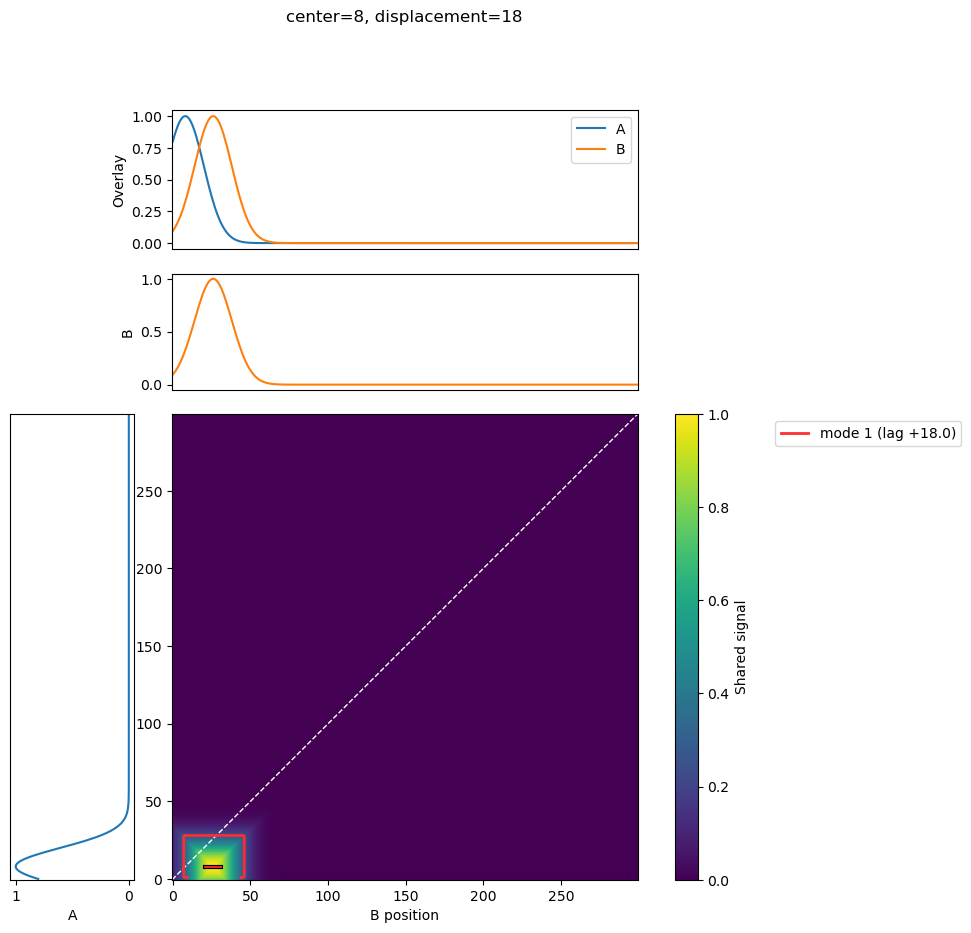

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,18.0,"(1,)","(1,)",1,1,454.853071,454.853071,1.0,False,0.0


In [18]:
edge_cases = []
for center in (150, 8):
    a, b = shifted_peak_pair(N, [center], [12], [1.0], [18], baseline=0.0)
    edge_cases.append({"label": f"center={center}, displacement=18", "a": a, "b": b})
edge_results = run_cases(edge_cases, island_parameters, show_stages=False)

## 7. Combined adversarial cases

These are not clean single-parameter tests. They combine multiple awkward features and are the best places to look for results that are technically consistent but biologically stupid.


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,"lag chain: +20, +25, +30",9,6,6,9,0,absent,None,"(-160.0, -67.57, 22.44, 30.0, 117.43, 210.0)"
1,broad peak with two subpeaks plus unrelated di...,6,5,3,4,2,retained,central_mode_won_conflicts,"(-157.98, 3.62, 24.03)"
2,shallow shoulder versus explicit double peak,1,1,1,1,0,retained,central_mode_won_conflicts,"(-0.01,)"
3,repeated peaks with one wide candidate partner,9,5,5,9,0,absent,None,"(-145.0, -60.0, 25.0, 110.0, 195.0)"


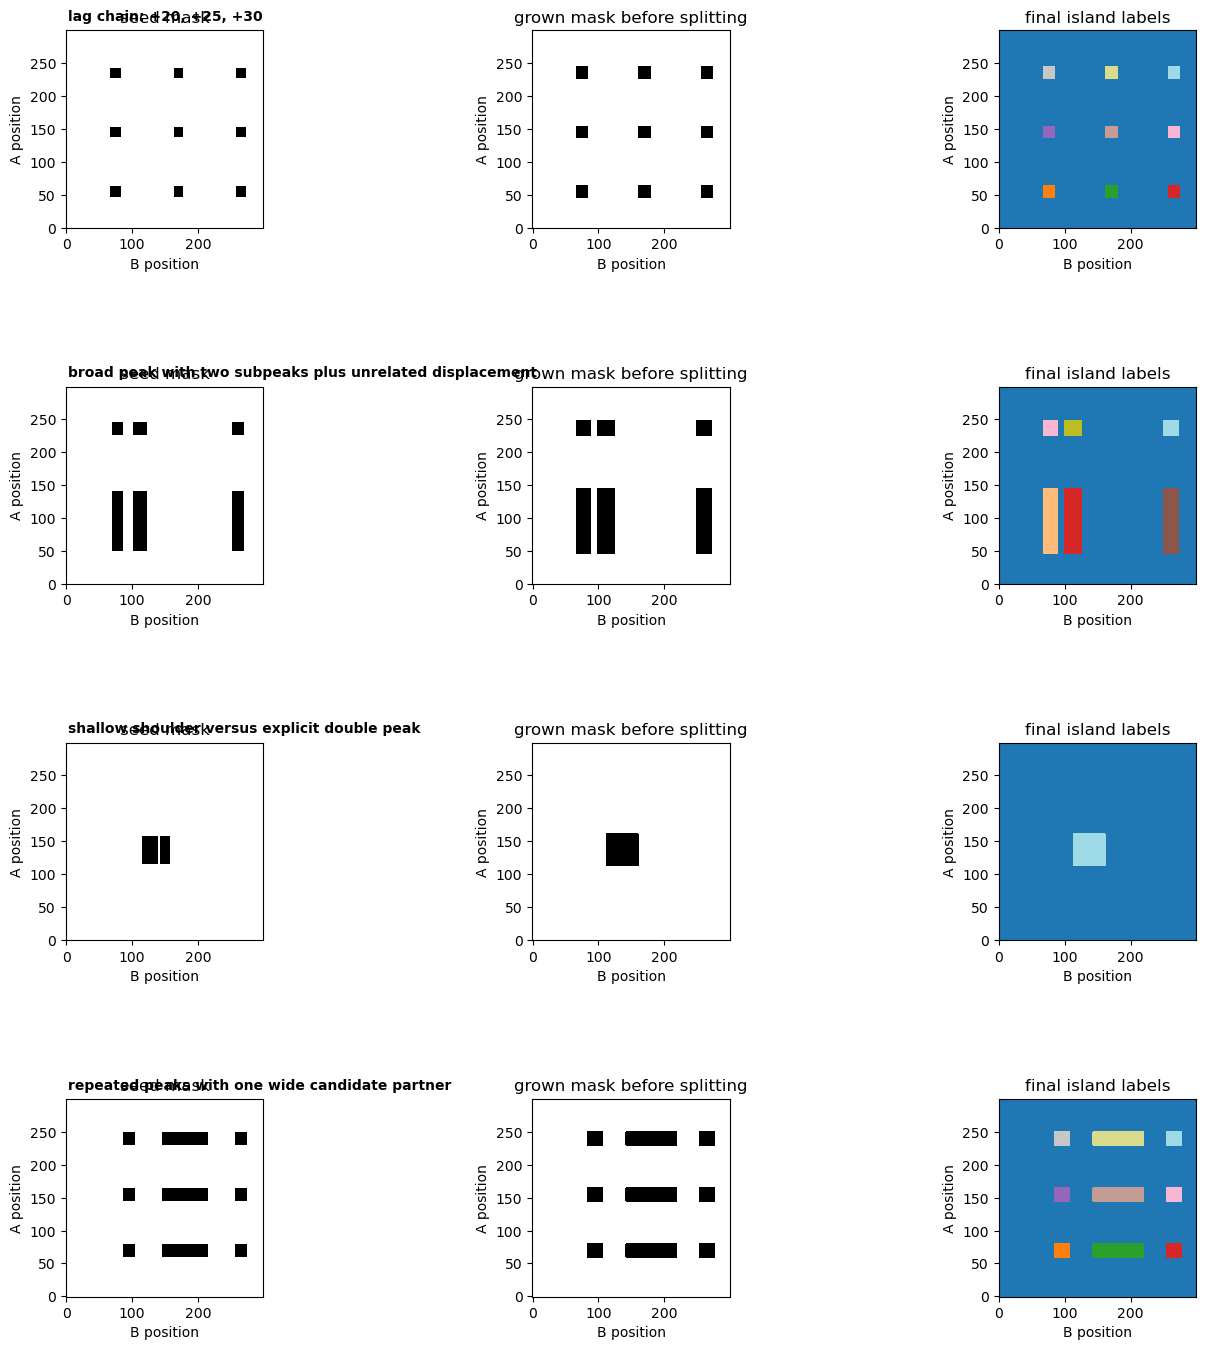

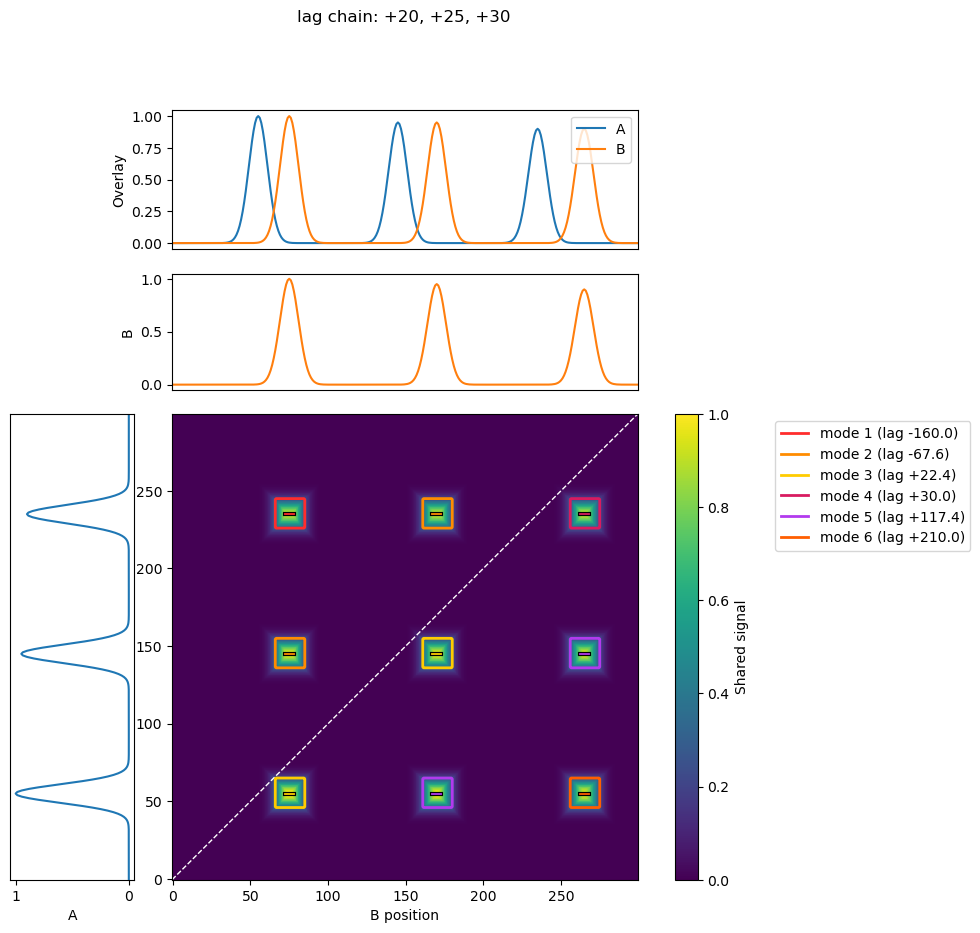

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-160.000000,"(7,)","(7,)",1,1,194.003998,194.003998,0.482375,False,0.0
1,2,-67.566105,"(4, 8)","(4, 8)",2,2,390.361984,390.361984,0.970602,False,0.0
2,3,22.435897,"(1, 5)","(1, 5)",2,2,402.185349,402.185349,1.000000,False,0.0
3,4,30.000000,"(9,)","(9,)",1,1,185.623993,185.623993,0.461538,False,0.0
4,5,117.433895,"(2, 6)","(2, 6)",2,2,390.362000,390.362000,0.970602,False,0.0
5,6,210.000000,"(3,)","(3,)",1,1,194.003998,194.003998,0.482375,False,0.0


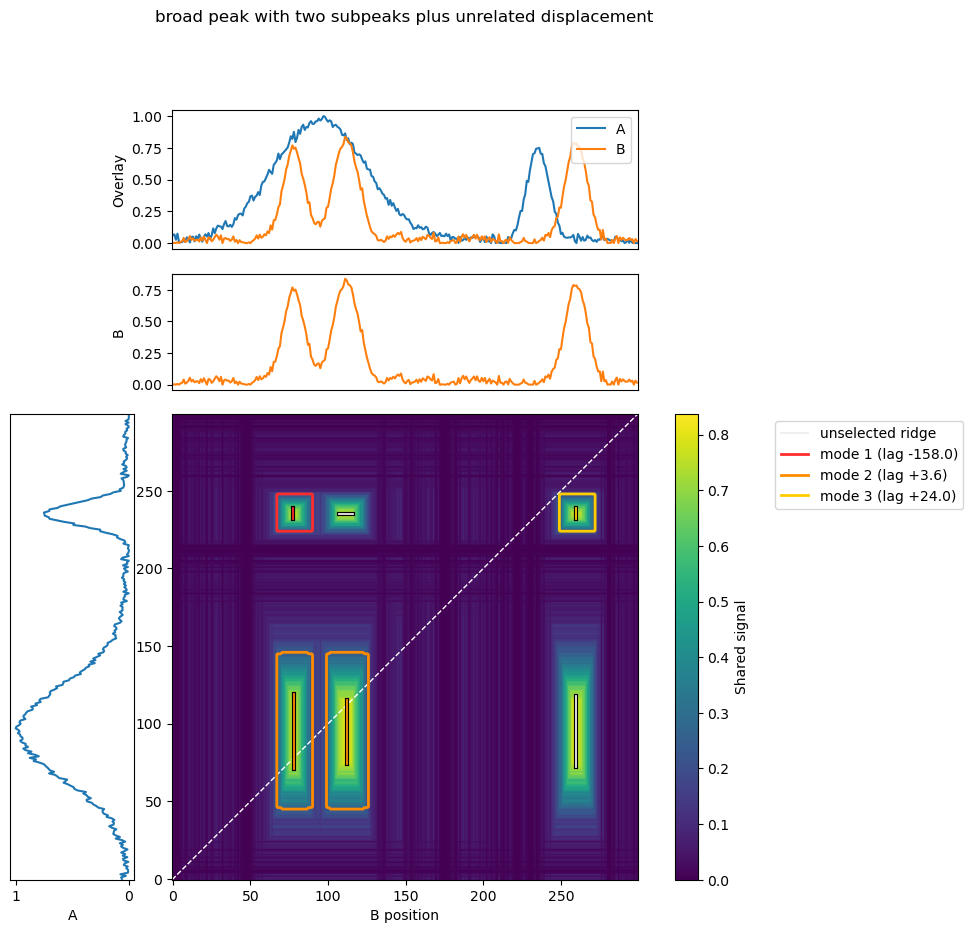

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-157.976791,"(4,)","(4,)",1,1,217.644963,217.644963,0.661760,False,0.0
1,2,-123.500376,"(5,)","(5,)",1,1,246.958946,246.958946,0.750890,False,0.0
2,3,3.621269,"(1, 2)","(2,)",2,1,328.888169,550.125826,1.000000,True,1.0
3,4,24.030969,"(6,)","(6,)",1,1,226.629910,226.629910,0.689079,False,0.0
4,5,164.968122,"(3,)","(3,)",1,1,234.170170,234.170170,0.712005,False,0.0


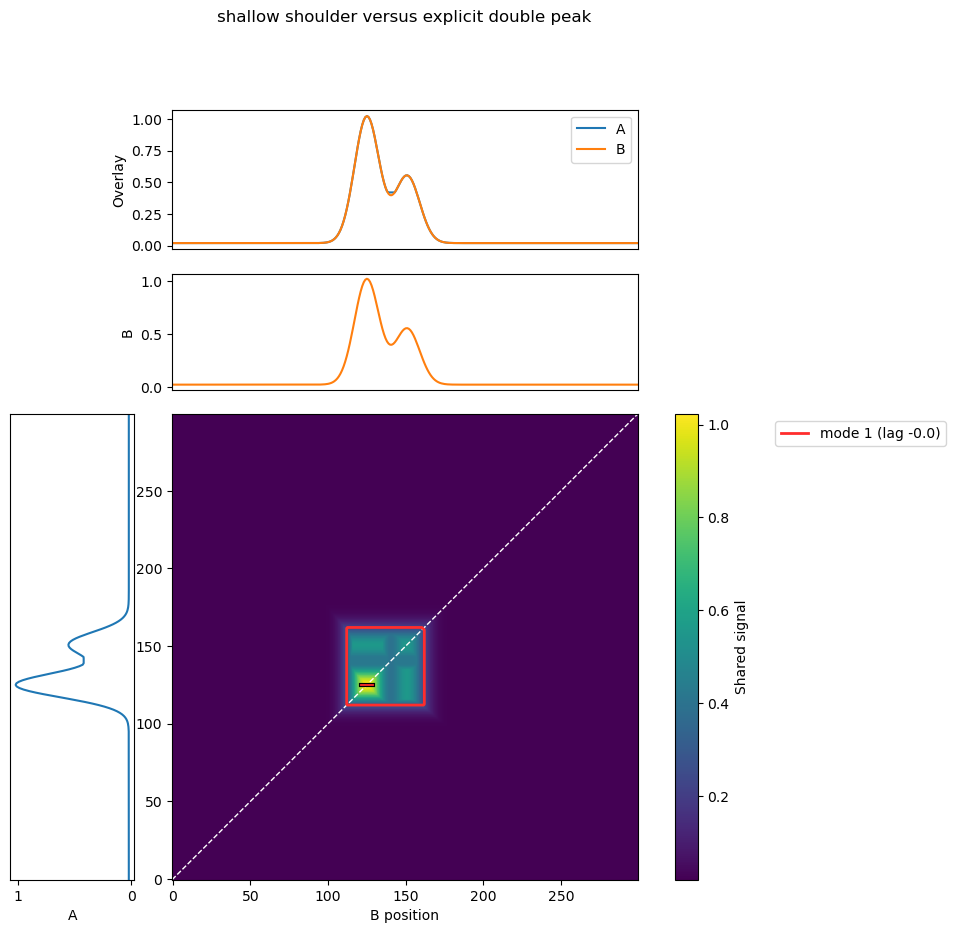

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-0.005029,"(1,)","(1,)",1,1,1184.765869,1184.765869,1.0,True,0.0


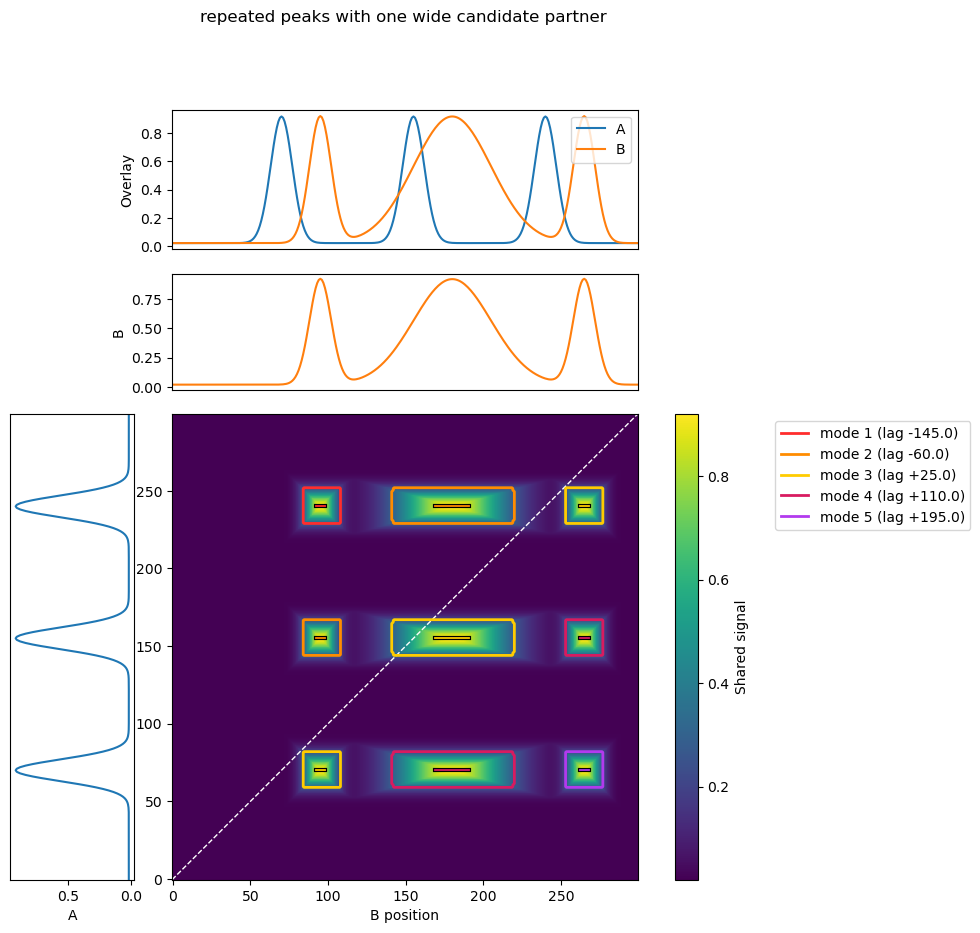

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-145.0,"(7,)","(7,)",1,1,266.716837,266.716837,0.336153,False,0.0
1,2,-60.0,"(4, 8)","(4, 8)",2,2,526.722506,526.722506,0.663847,False,0.0
2,3,25.0,"(1, 5, 9)","(1, 5, 9)",3,3,793.439343,793.439343,1.000000,False,0.0
3,4,110.0,"(2, 6)","(2, 6)",2,2,526.722506,526.722506,0.663847,False,0.0
4,5,195.0,"(3,)","(3,)",1,1,266.716837,266.716837,0.336153,False,0.0


In [19]:
combined_rng = np.random.default_rng(SEED + 29)

# A chain of lags where adjacent islands are close but the endpoints are not.
chain_a, chain_b = shifted_peak_pair(N, [55, 145, 235], [6, 6, 6], [1.0, 0.95, 0.90], [20, 25, 30], baseline=0.0)

# A broad peak, two close subpeaks, and an unrelated displaced pair.
mixed_a = peak_track(N, [(95, 30, 0.95), (235, 7, 0.75)], baseline=0.02, noise_level=0.018, rng=combined_rng)
mixed_b = peak_track(N, [(78, 7, 0.72), (112, 8, 0.80), (260, 7, 0.78)], baseline=0.02, noise_level=0.018, rng=combined_rng)

# A shallow shoulder that is almost, but not obviously, a second peak.
shoulder_a = bridged_peaks(N, 125, 151, 8, 1.0, 0.53, 0.40, baseline=0.02)
shoulder_b = peak_track(N, [(125, 8, 1.0), (151, 8, 0.53)], baseline=0.02)

# Repeated structure plus one much wider candidate partner.
repeated_a = peak_track(N, [(70, 7, 0.9), (155, 7, 0.9), (240, 7, 0.9)], baseline=0.02)
repeated_b = peak_track(N, [(95, 7, 0.9), (180, 25, 0.9), (265, 7, 0.9)], baseline=0.02)

combined_cases = [
    {"label": "lag chain: +20, +25, +30", "a": chain_a, "b": chain_b},
    {"label": "broad peak with two subpeaks plus unrelated displacement", "a": mixed_a, "b": mixed_b},
    {"label": "shallow shoulder versus explicit double peak", "a": shoulder_a, "b": shoulder_b},
    {"label": "repeated peaks with one wide candidate partner", "a": repeated_a, "b": repeated_b},
]
combined_results = run_cases(combined_cases, island_parameters)

###!!!### What the happened here? Why are none of these set into the same mode? 

## 8. Noise and peak-count scaling

This measures the combinatorial failure you already identified: more peaks and more noise can produce many islands and modes without adding useful biological structure. Only the worst grid cell is expanded into full heatmaps.


In [20]:
def run_scaling_grid(noise_levels, peak_counts, replicates, seed, n, island_parameters):
    rng = np.random.default_rng(seed)
    records = []
    for noise_level in noise_levels:
        for peak_count in peak_counts:
            for replicate in range(replicates):
                a, b = utils.simulate_pair(
                    "multiple_correspondences", rng, signal_level=0.75, signal_variation=0.2,
                    noise_level=noise_level, peak_count_range=(peak_count, peak_count),
                    unrelated_peak_count_range=(1, 3), location_range=(12, n - 12),
                    width_range=(4, 18), displacement_range=(4, 45),
                    tie_displacement_range=(30, 90), tie_strength_variation=0.03,
                    shape_a="bell", shape_b="bell", n=n)
                label = f"noise={noise_level:.3f}, peaks={peak_count}, replicate={replicate + 1}"
                result = analyze_case(label, a, b, island_parameters)
                row = result_summary(result)
                row.update({"noise": noise_level, "peak_count": peak_count, "replicate": replicate, "result": result})
                records.append(row)
    return records

def plot_scaling_grid(records, noise_levels, peak_counts):
    frame = pd.DataFrame([{key: value for key, value in row.items() if key != "result"} for row in records])
    metrics = ["islands", "provisional_modes", "selected_modes"]
    fig, axes = plt.subplots(1, len(metrics), figsize=(14, 4))
    for axis, metric in zip(axes, metrics):
        table = frame.pivot_table(index="noise", columns="peak_count", values=metric, aggfunc="mean").reindex(index=noise_levels, columns=peak_counts)
        image = axis.imshow(table.values, origin="lower", aspect="auto", cmap="magma")
        axis.set(title=f"mean {metric}", xlabel="input peak count", ylabel="noise")
        axis.set_xticks(range(len(peak_counts)), peak_counts)
        axis.set_yticks(range(len(noise_levels)), [f"{value:.3f}" for value in noise_levels])
        fig.colorbar(image, ax=axis)
    plt.tight_layout()
    plt.show()
    return frame

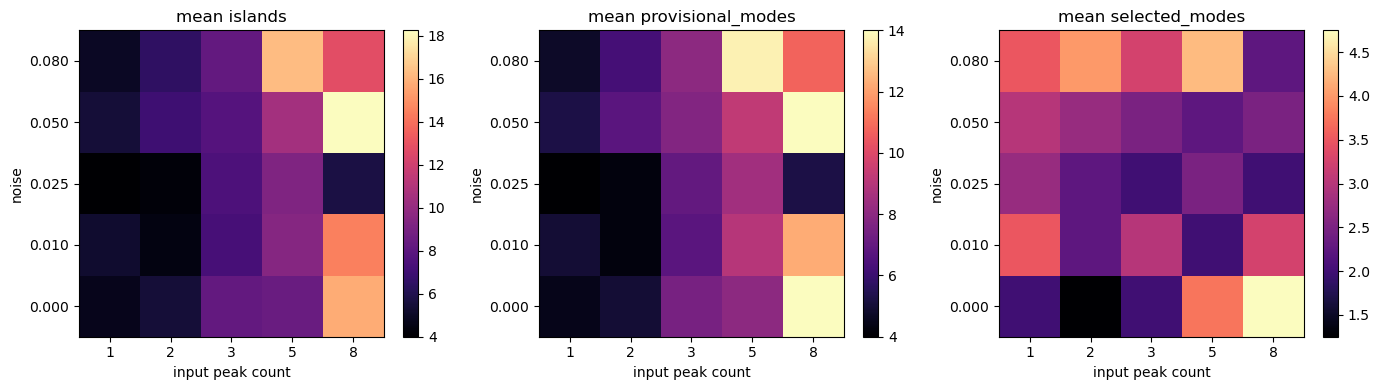

,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags,noise,peak_count,replicate
78,"noise=0.050, peaks=8, replicate=3",30,22,5,8,16,retained,central_mode_won_conflicts,"(-231.34, -124.04, -88.95, 3.42, 19.27)",0.050,8,2
79,"noise=0.050, peaks=8, replicate=4",28,20,1,4,20,retained,central_mode_won_conflicts,"(7.49,)",0.050,8,3
92,"noise=0.080, peaks=5, replicate=1",23,18,10,14,2,rejected,below_mode_score_fraction,"(-169.8, -90.59, -50.98, -21.3, 20.64, 35.94, ...",0.080,5,0
19,"noise=0.000, peaks=8, replicate=4",20,19,6,7,1,rejected,below_mode_score_fraction,"(-90.75, -17.5, 31.99, 104.0, 138.95, 211.0)",0.000,8,3
36,"noise=0.010, peaks=8, replicate=1",20,18,2,3,2,rejected,below_mode_score_fraction,"(-41.96, 47.11)",0.010,8,0
16,"noise=0.000, peaks=8, replicate=1",20,17,1,2,12,retained,central_mode_won_conflicts,"(4.03,)",0.000,8,0
17,"noise=0.000, peaks=8, replicate=2",20,17,10,13,1,rejected,below_mode_score_fraction,"(-177.99, -162.5, -115.91, -108.49, -80.5, -45...",0.000,8,1
38,"noise=0.010, peaks=8, replicate=3",20,17,5,8,1,rejected,below_mode_score_fraction,"(-164.92, -98.89, -39.49, -15.5, 43.48)",0.010,8,2
94,"noise=0.080, peaks=5, replicate=3",20,17,2,2,2,rejected,below_mode_score_fraction,"(-148.51, 42.62)",0.080,5,2
98,"noise=0.080, peaks=8, replicate=3",19,16,2,3,2,rejected,below_mode_score_fraction,"(56.12, 105.78)",0.080,8,2


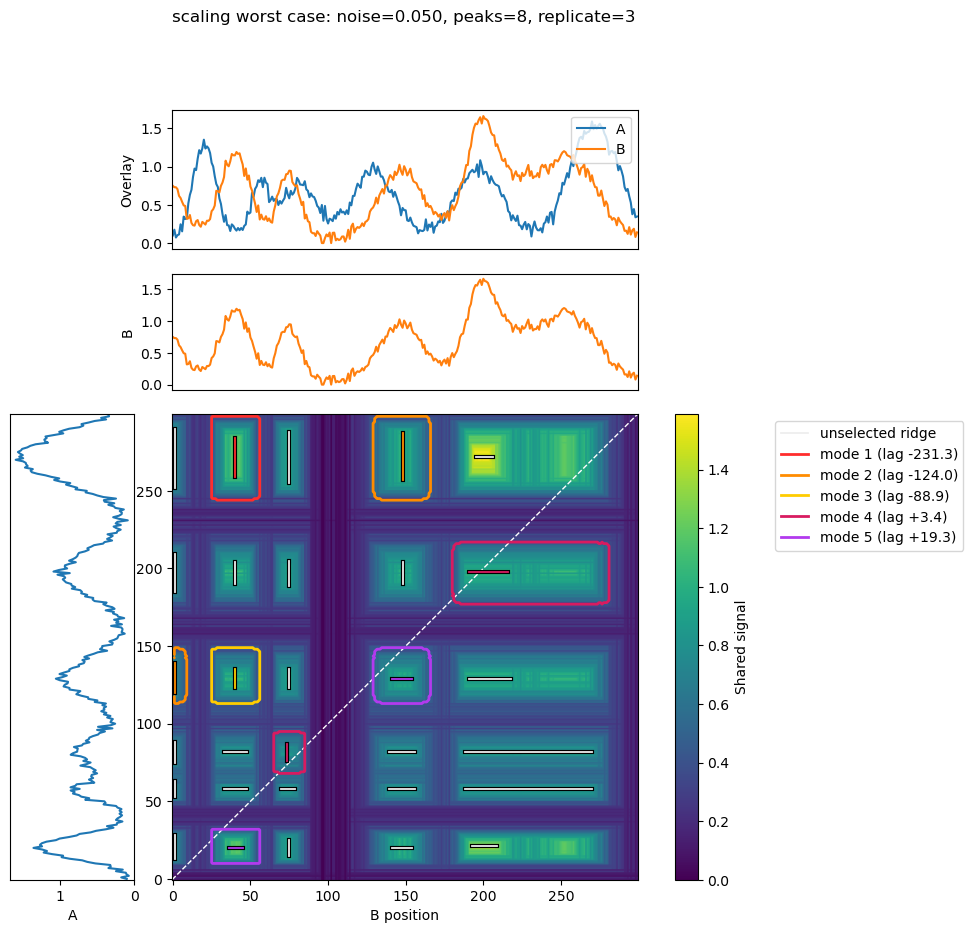

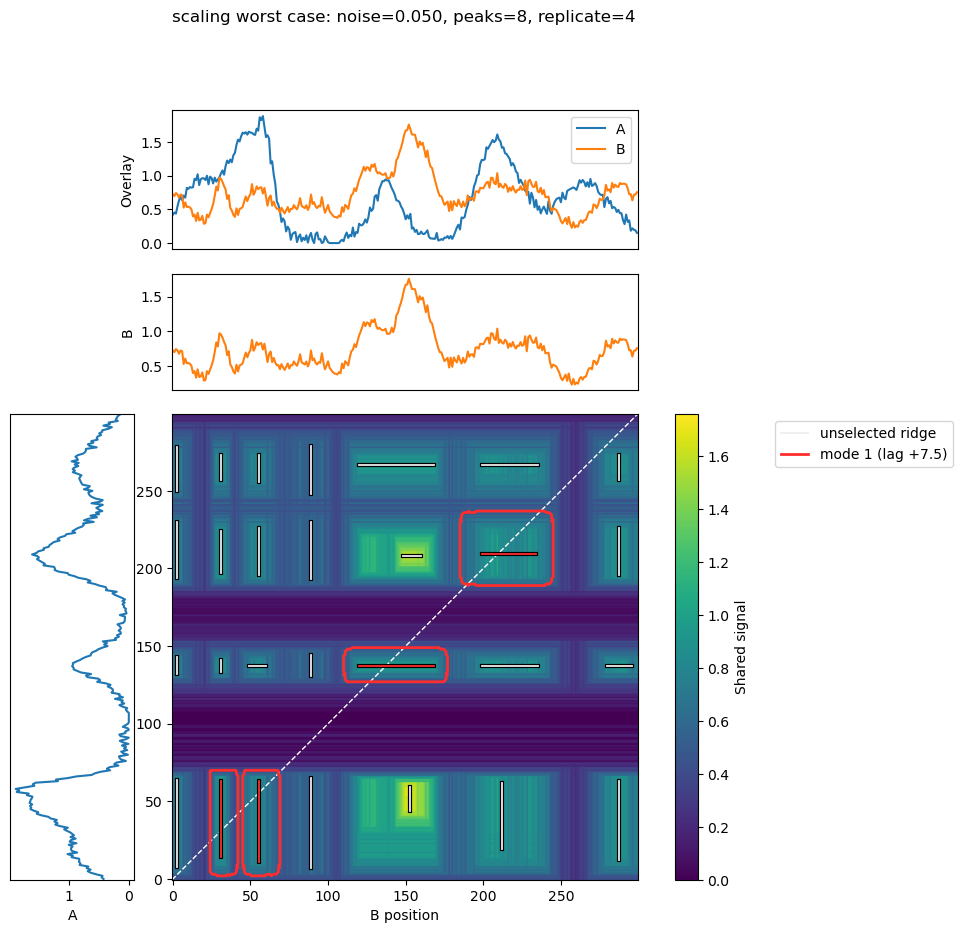

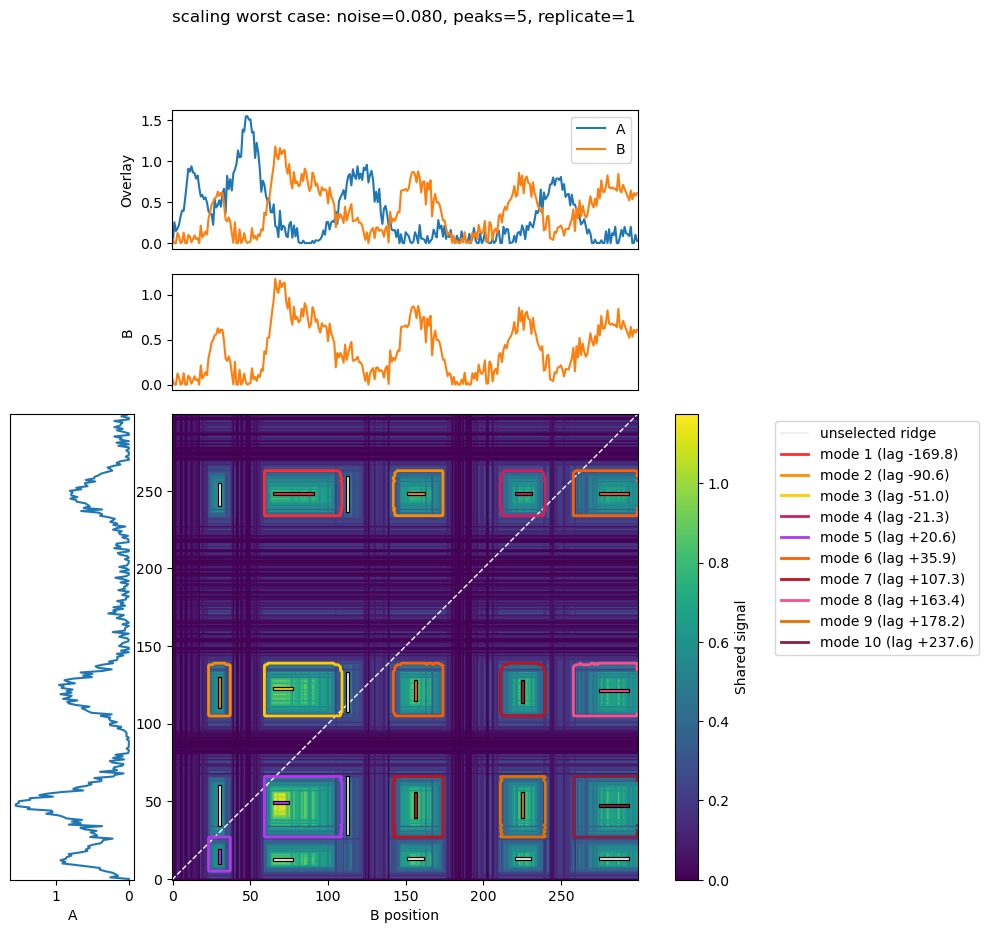

In [21]:
noise_levels = [0.0, 0.01, 0.025, 0.05, 0.08]
peak_counts = [1, 2, 3, 5, 8]
scaling_records = run_scaling_grid(noise_levels, peak_counts, SCALING_REPLICATES, SEED + 101, N, island_parameters)
scaling_table = plot_scaling_grid(scaling_records, noise_levels, peak_counts)
display(scaling_table.sort_values(["islands", "provisional_modes"], ascending=False).head(15))

worst_scaling = sorted(scaling_records, key=lambda row: (row["islands"], row["provisional_modes"]), reverse=True)[:3]
for row in worst_scaling:
    utils.plot_simulated_islands(row["result"], title=f"scaling worst case: {row['case']}")

## 9. Random adversarial search

This generator deliberately mixes shared peaks, independent shifts, missing partners, extra peaks, width distortions, broad backgrounds, local depletion, edge clipping, and noise. The ranking is not a correctness score; it is a queue of structurally complicated outputs most likely to reveal something stupid.


In [22]:
def random_adversarial_pair(rng, n, max_peaks, noise_range):
    peak_count = int(rng.integers(1, max_peaks + 1))
    centers = np.sort(rng.uniform(4, n - 4, peak_count))
    widths = np.exp(rng.uniform(np.log(2.5), np.log(35), peak_count))
    heights = rng.uniform(0.18, 1.25, peak_count)
    a_peaks = list(zip(centers, widths, heights))

    shared_shift = rng.uniform(-50, 50)
    b_peaks = []
    for center, width, height in a_peaks:
        if rng.random() < 0.20:
            continue
        shift = shared_shift if rng.random() < 0.55 else rng.uniform(-80, 80)
        b_center = np.clip(center + shift, 0, n - 1)
        b_width = width * np.exp(rng.uniform(np.log(0.35), np.log(3.0)))
        b_height = height * rng.uniform(0.35, 1.55)
        b_peaks.append((b_center, b_width, b_height))
        if rng.random() < 0.22:
            b_peaks.append((np.clip(center + rng.uniform(-100, 100), 0, n - 1), b_width * rng.uniform(0.7, 1.4), b_height * rng.uniform(0.7, 1.3)))

    for _ in range(int(rng.integers(0, 4))):
        b_peaks.append((rng.uniform(0, n - 1), rng.uniform(2.5, 35), rng.uniform(0.15, 1.1)))
    if not b_peaks:
        b_peaks.append((rng.uniform(0, n - 1), rng.uniform(3, 20), rng.uniform(0.2, 0.8)))

    baseline_a = rng.uniform(0, 0.08)
    baseline_b = rng.uniform(0, 0.08)
    noise_a = rng.uniform(*noise_range)
    noise_b = rng.uniform(*noise_range)
    a = peak_track(n, a_peaks, baseline=baseline_a, noise_level=noise_a, rng=rng)
    b = peak_track(n, b_peaks, baseline=baseline_b, noise_level=noise_b, rng=rng)

    broad_a = rng.random() < 0.12
    broad_b = rng.random() < 0.12
    if broad_a:
        a += rng.uniform(0.25, 0.9)
    if broad_b:
        b += rng.uniform(0.25, 0.9)
    if rng.random() < 0.18:
        target = "A" if rng.random() < 0.5 else "B"
        dip = utils.gaussian(np.arange(n), rng.uniform(10, n - 10), rng.uniform(3, 20), rng.uniform(0.15, 0.8))
        if target == "A":
            a = np.maximum(a - dip, 0)
        else:
            b = np.maximum(b - dip, 0)

    metadata = {"input_peaks_A": len(a_peaks), "input_peaks_B": len(b_peaks),
                "shared_shift": shared_shift, "noise_A": noise_a, "noise_B": noise_b,
                "broad_A": broad_a, "broad_B": broad_b}
    return a, b, metadata

def adversarial_score(result):
    provisional = result["selection"]["provisional_modes"]
    conflict_mass = sum(mode["conflict_fraction"] * mode["n_islands"] for mode in provisional)
    broad_lag_modes = sum(mode["lag_max"] - mode["lag_min"] > result["stress_parameters"]["mode_lag_tolerance"] for mode in provisional)
    gate_penalty = 3 if result["selection"]["central_gate"].get("status") == "rejected" else 0
    return (len(result["islands"]) + 2 * len(provisional) + 0.75 * len(result["selection"]["deleted_island_ids"])
            + 2.5 * conflict_mass + 3 * broad_lag_modes + gate_penalty)

def run_adversarial_search(n_windows, seed, n, max_peaks, noise_range, island_parameters):
    rng = np.random.default_rng(seed)
    records = []
    for index in range(n_windows):
        a, b, metadata = random_adversarial_pair(rng, n, max_peaks, noise_range)
        result = analyze_case(f"fuzz {index + 1}", a, b, island_parameters)
        row = result_summary(result)
        row.update(metadata)
        row["adversarial_score"] = adversarial_score(result)
        row["result"] = result
        records.append(row)
    return sorted(records, key=lambda row: row["adversarial_score"], reverse=True)


,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags,input_peaks_A,input_peaks_B,shared_shift,noise_A,noise_B,broad_A,broad_B,adversarial_score
0,fuzz 108,56,37,1,5,39,retained,central_mode_won_conflicts,"(0.64,)",1,4,6.837806,0.065058,0.047196,False,False,183.500000
1,fuzz 21,30,28,2,3,16,retained,central_mode_won_conflicts,"(-149.98, 4.87)",8,11,32.252937,0.078144,0.078616,False,False,101.000000
2,fuzz 30,28,20,1,6,22,retained,central_mode_won_conflicts,"(17.79,)",4,3,-16.864662,0.043103,0.082399,True,True,90.500000
3,fuzz 192,24,21,5,7,14,retained,central_mode_won_conflicts,"(-202.53, -94.0, -29.94, -13.42, 69.08)",6,9,-30.759303,0.056434,0.066035,False,False,79.500000
4,fuzz 169,26,21,4,5,3,rejected,below_mode_score_fraction,"(-50.51, 40.5, 47.5, 140.99)",3,2,39.751931,0.082409,0.005569,False,False,78.750000
5,fuzz 197,23,17,1,4,17,retained,central_mode_won_conflicts,"(-5.29,)",7,7,36.885675,0.059509,0.010007,False,False,74.416667
6,fuzz 140,24,21,6,8,2,rejected,below_mode_score_fraction,"(-44.01, 23.74, 30.9, 98.71, 161.45, 222.21)",8,12,28.470552,0.067811,0.048001,False,False,70.500000
7,fuzz 27,24,20,2,4,0,absent,None,"(-29.32, 143.24)",3,3,-27.296836,0.039035,0.057365,False,False,69.000000
8,fuzz 165,20,18,2,3,12,retained,central_mode_won_conflicts,"(-42.01, 7.68)",8,10,2.526380,0.045549,0.039421,False,False,65.000000
9,fuzz 82,20,18,7,8,2,rejected,below_mode_score_fraction,"(-244.52, -193.46, -94.52, -43.46, -12.72, 40....",5,5,40.326039,0.018902,0.042170,False,False,63.500000


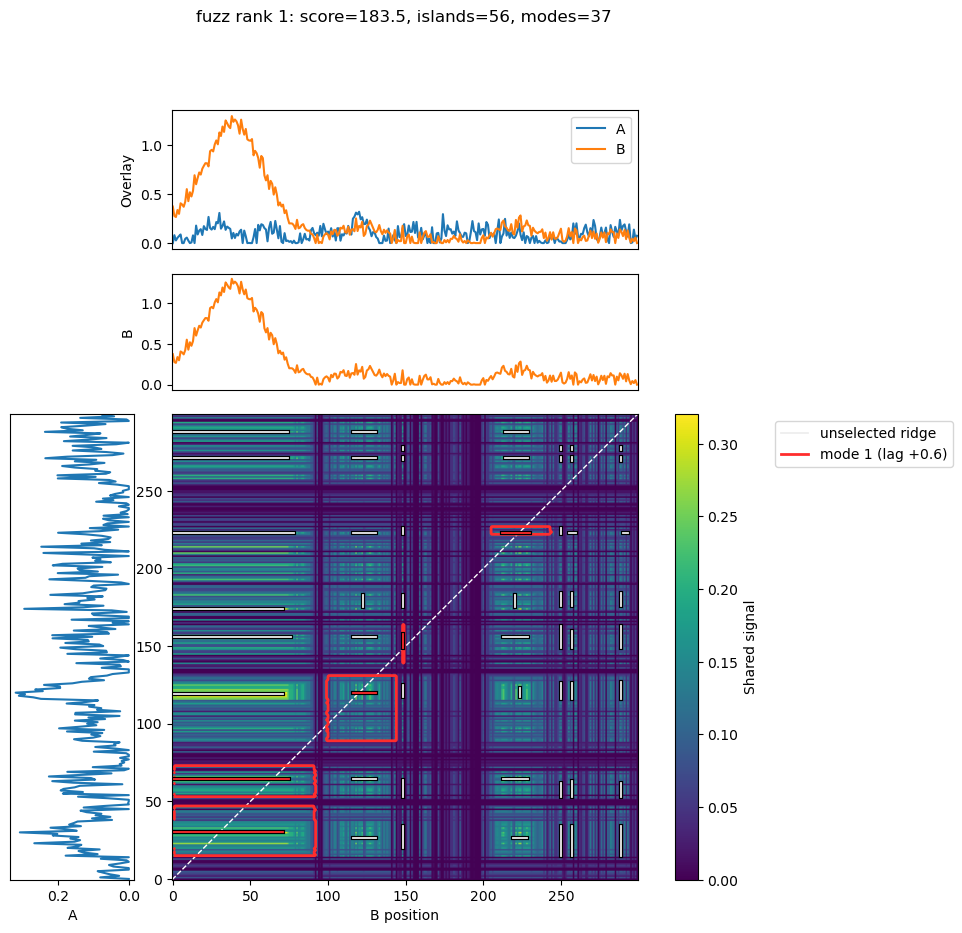

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-251.000000,"(50,)","(50,)",1,1,49.920374,49.920374,0.158804,False,0.000000
1,2,-234.000000,"(43,)","(43,)",1,1,34.579911,34.579911,0.110004,False,0.000000
2,3,-184.000000,"(36,)","(36,)",1,1,2.291268,2.291268,0.007289,False,0.000000
3,4,-164.500000,"(51,)","(51,)",1,1,40.831000,40.831000,0.129889,False,0.000000
4,5,-147.500000,"(44,)","(44,)",1,1,28.373608,28.373608,0.090260,False,0.000000
5,6,-138.500000,"(29,)","(29,)",1,1,273.666874,273.666874,0.870573,False,0.000000
6,7,-129.000000,"(52,)","(52,)",1,1,0.094101,0.094101,0.000299,False,0.000000
7,8,-118.010524,"(45, 22)","(22, 45)",2,2,57.546649,57.546649,0.183064,False,0.000000
8,9,-99.500000,"(37,)","(37,)",1,1,1.953329,1.953329,0.006214,False,0.000000
9,10,-83.509671,"(15,)","(15,)",1,1,236.982895,236.982895,0.753876,False,0.000000


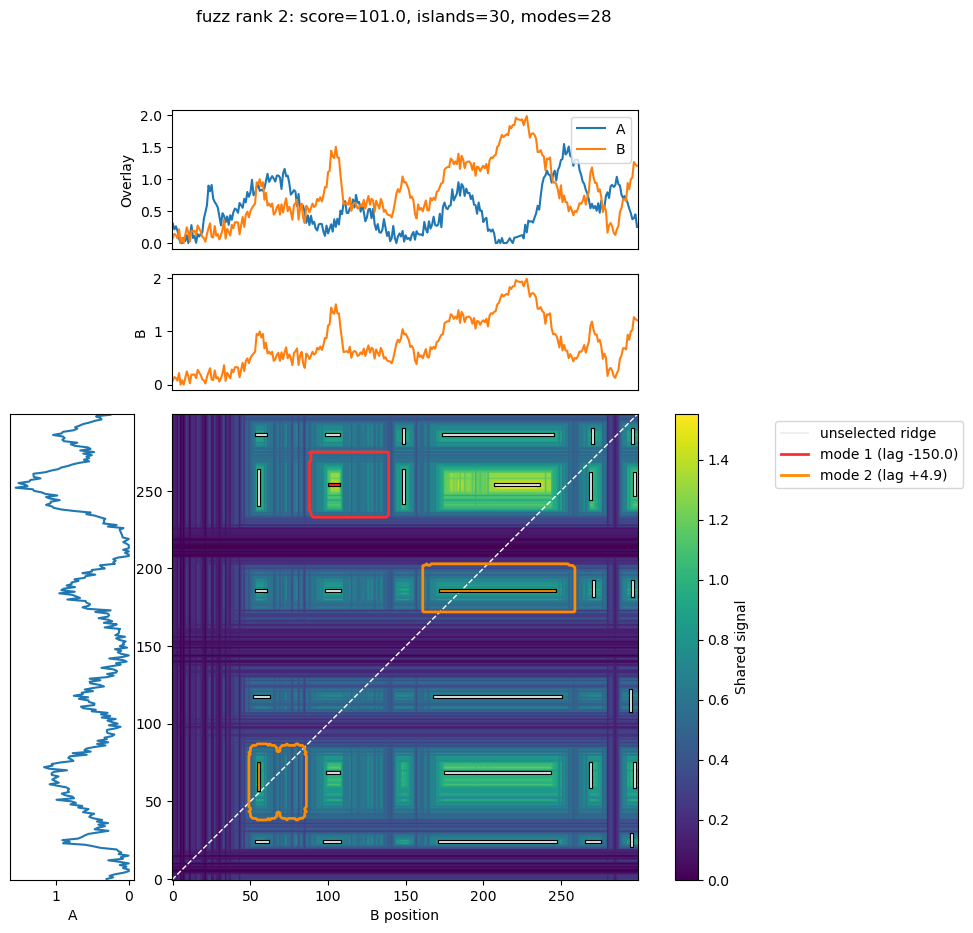

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-228.804144,"(19,)","(19,)",1,1,289.574986,289.574986,0.167218,False,0.0
1,2,-196.241281,"(20,)","(20,)",1,1,770.470754,770.470754,0.444916,False,0.0
2,3,-183.000000,"(27,)","(27,)",1,1,320.994433,320.994433,0.185361,False,0.0
3,4,-149.976297,"(28,)","(28,)",1,1,1156.310594,1156.310594,0.667723,False,0.0
4,5,-136.028295,"(25,)","(25,)",1,1,273.792294,273.792294,0.158104,False,0.0
5,6,-128.632488,"(14,)","(14,)",1,1,471.794591,471.794591,0.272442,False,0.0
6,7,-103.529899,"(26,)","(26,)",1,1,296.753063,296.753063,0.171363,False,0.0
7,8,-82.132488,"(17,)","(17,)",1,1,507.115171,507.115171,0.292839,False,0.0
8,9,-76.000000,"(23,)","(23,)",1,1,357.673537,357.673537,0.206542,False,0.0
9,10,-59.549498,"(11,)","(11,)",1,1,143.516785,143.516785,0.082875,False,0.0


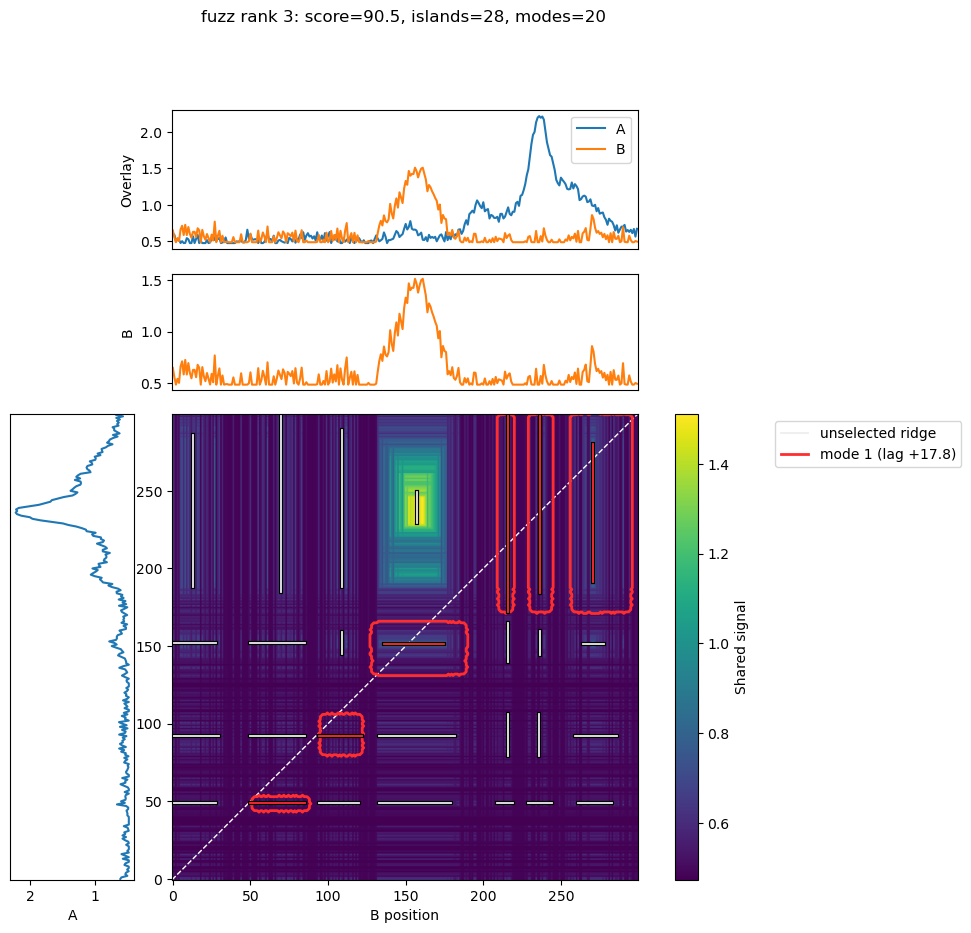

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-223.974405,"(22,)","(22,)",1,1,688.578491,688.578491,0.194987,False,0.0
1,2,-172.336042,"(23,)","(23,)",1,1,763.899591,763.899591,0.216316,False,0.0
2,3,-137.679256,"(15,)","(15,)",1,1,615.072009,615.072009,0.174172,False,0.0
3,4,-129.342238,"(24,)","(24,)",1,1,417.882785,417.882785,0.118333,False,0.0
4,5,-82.414550,"(16, 25)","(16, 25)",2,2,3531.408659,3531.408659,1.000000,False,0.0
5,6,-77.317036,"(8,)","(8,)",1,1,371.975045,371.975045,0.105333,False,0.0
6,7,-42.842238,"(17,)","(17,)",1,1,400.239943,400.239943,0.113337,False,0.0
7,8,-34.948877,"(1,)","(1,)",1,1,48.591901,48.591901,0.013760,False,0.0
8,9,-24.817036,"(9,)","(9,)",1,1,360.485343,360.485343,0.102080,False,0.0
9,10,17.785841,"(2, 10, 18, 26, 27, 28)","(2, 10, 18, 28)",6,4,1913.386372,2088.151917,0.541820,True,0.2


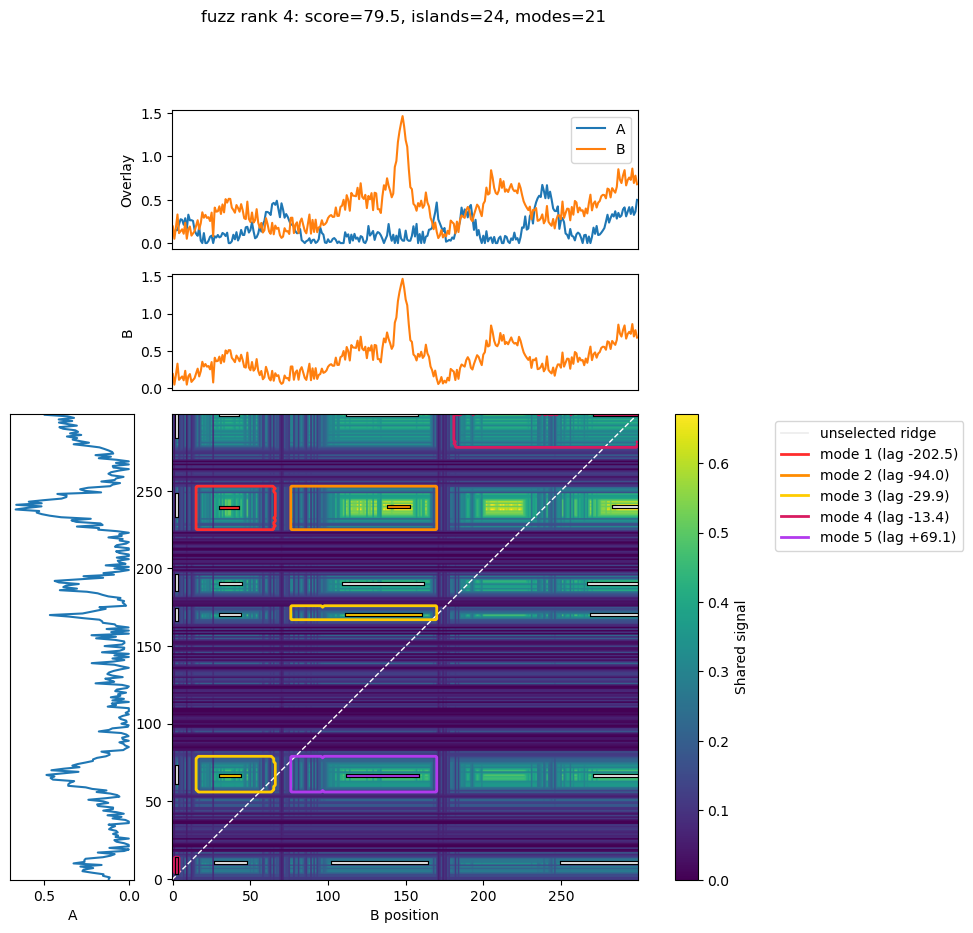

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-289.000000,"(21,)","(21,)",1,1,1.434497,1.434497,0.005974,False,0.0
1,2,-262.500000,"(22,)","(22,)",1,1,122.582890,122.582890,0.510491,False,0.0
2,3,-237.500000,"(17,)","(17,)",1,1,1.393198,1.393198,0.005802,False,0.0
3,4,-202.530344,"(18,)","(18,)",1,1,200.697558,200.697558,0.835797,False,0.0
4,5,-187.500000,"(13,)","(13,)",1,1,1.437738,1.437738,0.005987,False,0.0
5,6,-164.029600,"(9, 23)","(9, 23)",2,2,132.007966,132.007966,0.549742,False,0.0
6,7,-152.228663,"(14,)","(14,)",1,1,33.928661,33.928661,0.141295,False,0.0
7,8,-133.000000,"(10,)","(10,)",1,1,15.764024,15.764024,0.065649,False,0.0
8,9,-93.996204,"(19,)","(19,)",1,1,228.594256,228.594256,0.951972,False,0.0
9,10,-64.000000,"(5,)","(5,)",1,1,1.392204,1.392204,0.005798,False,0.0


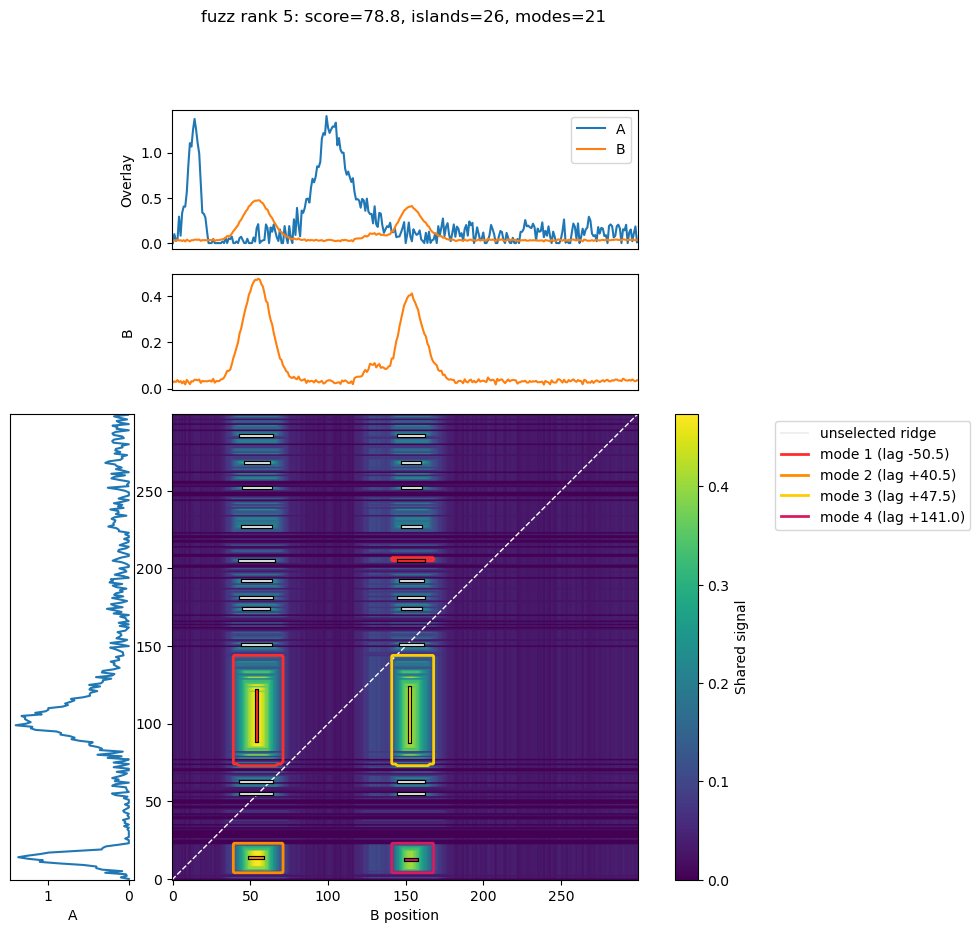

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-231.640682,"(25,)","(25,)",1,1,34.225889,34.225889,0.135178,False,0.000000
1,2,-213.500000,"(23,)","(23,)",1,1,19.717879,19.717879,0.077877,False,0.000000
2,3,-197.500000,"(21,)","(21,)",1,1,0.633026,0.633026,0.002500,False,0.000000
3,4,-173.000000,"(19,)","(19,)",1,1,55.925893,55.925893,0.220884,False,0.000000
4,5,-151.000000,"(17,)","(17,)",1,1,0.591488,0.591488,0.002336,False,0.000000
5,6,-137.967056,"(15,)","(15,)",1,1,10.704462,10.704462,0.042278,False,0.000000
6,7,-131.368529,"(26, 13)","(13, 26)",2,2,36.536961,36.536961,0.144306,False,0.000000
7,8,-120.000000,"(11,)","(11,)",1,1,7.338759,7.338759,0.028985,False,0.000000
8,9,-114.500000,"(24,)","(24,)",1,1,19.704080,19.704080,0.077823,False,0.000000
9,10,-96.613953,"(22, 9)","(9, 22)",2,2,7.525794,7.525794,0.029724,False,0.000000


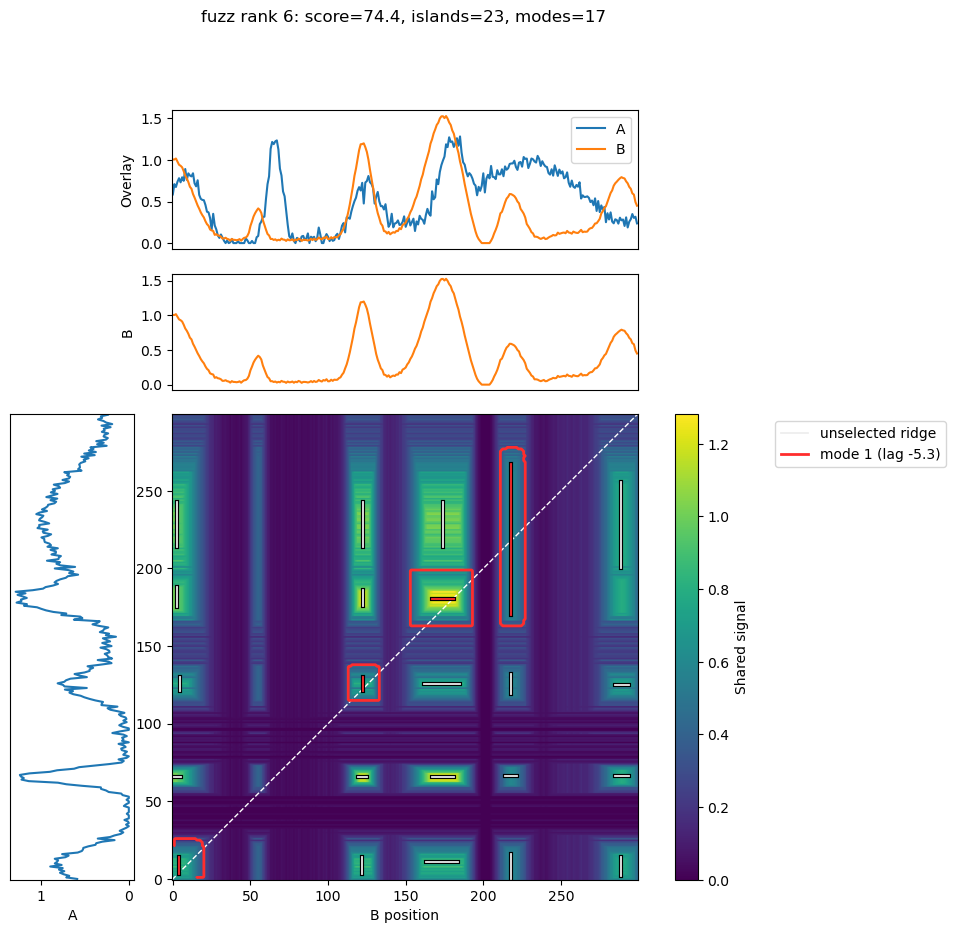

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-226.051521,"(16,)","(16,)",1,1,237.963748,237.963748,0.174145,False,0.000000
1,2,-179.051521,"(17,)","(17,)",1,1,244.416669,244.416669,0.178867,False,0.000000
2,3,-120.554741,"(11,)","(11,)",1,1,200.915787,200.915787,0.147032,False,0.000000
3,4,-106.003146,"(18,)","(18,)",1,1,249.092091,249.092091,0.182288,False,0.000000
4,5,-59.946859,"(6, 19)","(6, 19)",2,2,385.227703,385.227703,0.281914,False,0.000000
5,6,-54.492458,"(20,)","(20,)",1,1,1087.792406,1087.792406,0.796059,False,0.000000
6,7,-5.293872,"(1, 12, 21, 22)","(1, 12, 21)",4,3,1366.472537,1475.245075,1.000000,True,0.166667
7,8,47.988449,"(13,)","(13,)",1,1,281.036137,281.036137,0.205665,False,0.000000
8,9,59.581119,"(7, 23)","(7, 23)",2,2,419.202551,419.202551,0.306777,False,0.000000
9,10,92.503747,"(14,)","(14,)",1,1,109.960017,109.960017,0.080470,False,0.000000


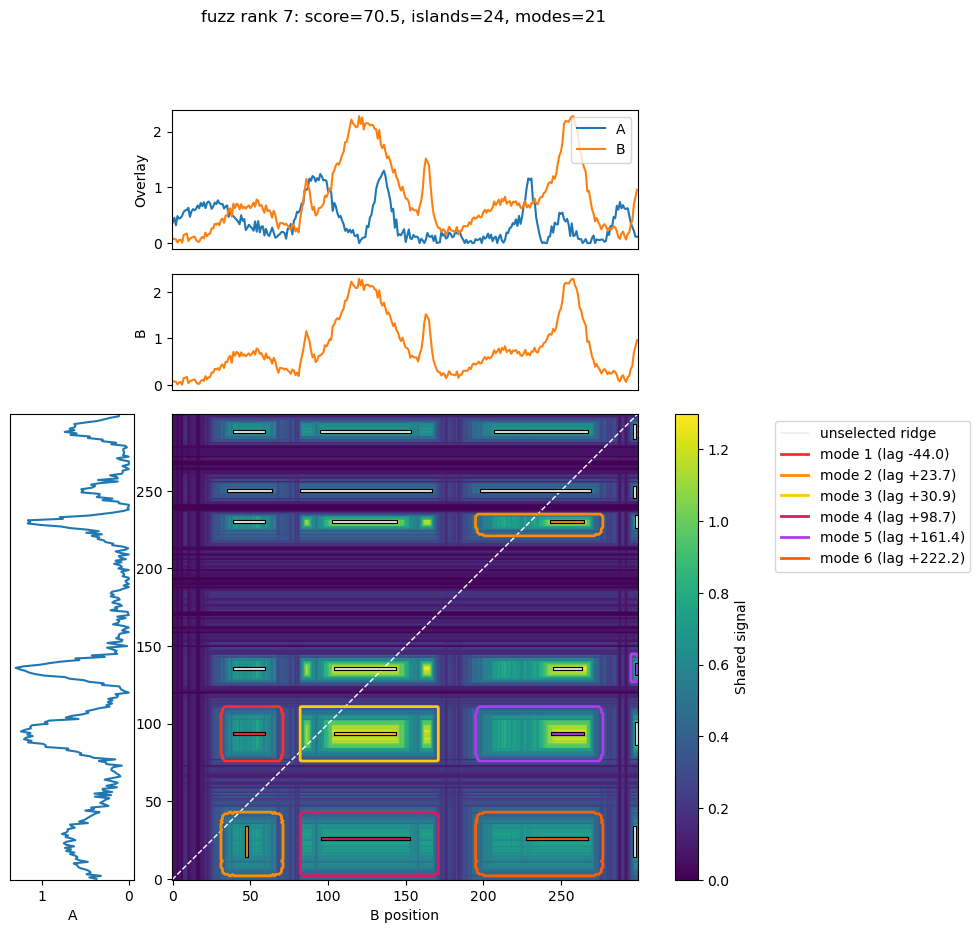

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-238.510350,"(21,)","(21,)",1,1,68.931359,68.931359,0.073677,False,0.0
1,2,-200.501340,"(17,)","(17,)",1,1,41.549355,41.549355,0.044410,False,0.0
2,3,-180.494369,"(13,)","(13,)",1,1,90.805544,90.805544,0.097057,False,0.0
3,4,-163.510350,"(22,)","(22,)",1,1,73.604587,73.604587,0.078672,False,0.0
4,5,-125.501340,"(18,)","(18,)",1,1,42.866708,42.866708,0.045818,False,0.0
5,6,-105.999347,"(14,)","(14,)",1,1,115.552372,115.552372,0.123507,False,0.0
6,7,-85.526924,"(9,)","(9,)",1,1,165.059392,165.059392,0.176422,False,0.0
7,8,-50.510350,"(23,)","(23,)",1,1,71.780114,71.780114,0.076721,False,0.0
8,9,-44.005560,"(5,)","(5,)",1,1,629.004057,629.004057,0.672305,False,0.0
9,10,-12.224127,"(10, 19)","(10, 19)",2,2,263.489544,263.489544,0.281628,True,0.0


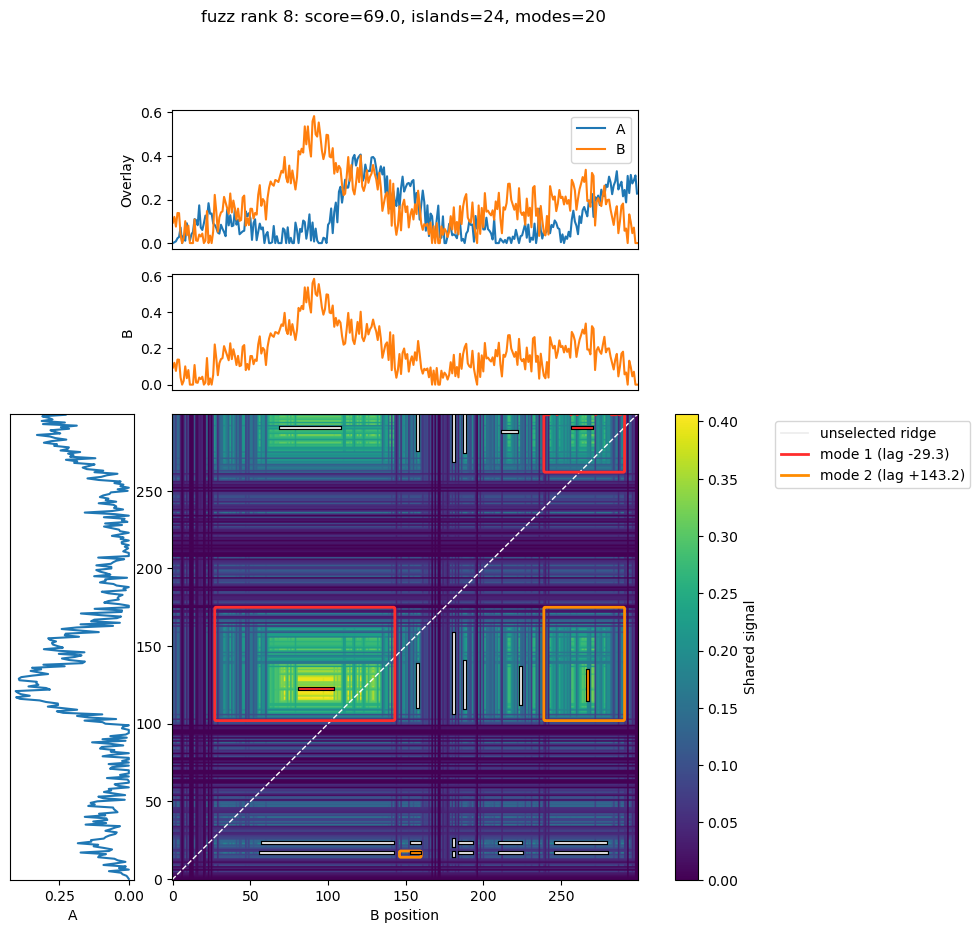

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-201.581036,"(19,)","(19,)",1,1,267.909585,267.909585,0.214892,False,0.0
1,2,-129.500000,"(20,)","(20,)",1,1,26.421102,26.421102,0.021193,False,0.0
2,3,-98.825971,"(21, 22)","(22,)",2,1,10.731436,11.624742,0.008608,False,1.0
3,4,-70.554400,"(24,)","(24,)",1,1,205.465968,205.465968,0.164805,False,0.0
4,5,-29.320749,"(13, 23)","(13, 23)",2,2,1246.718827,1246.718827,1.000000,False,0.0
5,6,33.500000,"(14,)","(14,)",1,1,24.153946,24.153946,0.019374,False,0.0
6,7,48.500000,"(15,)","(15,)",1,1,0.822534,0.822534,0.000660,False,0.0
7,8,63.521483,"(16,)","(16,)",1,1,9.769445,9.769445,0.007836,False,0.0
8,9,77.000000,"(7,)","(7,)",1,1,2.843529,2.843529,0.002281,False,0.0
9,10,82.500000,"(1,)","(1,)",1,1,1.546790,1.546790,0.001241,False,0.0


In [23]:
fuzz_records = run_adversarial_search(
    n_windows=FUZZ_WINDOWS, seed=SEED + 1000, n=N, max_peaks=8,
    noise_range=(0.0, 0.09), island_parameters=island_parameters
)
fuzz_table = pd.DataFrame([{key: value for key, value in row.items() if key != "result"} for row in fuzz_records])
display(fuzz_table.head(20))

for rank, row in enumerate(fuzz_records[:FUZZ_CASES_TO_PLOT], start=1):
    result = row["result"]
    title = f"fuzz rank {rank}: score={row['adversarial_score']:.1f}, islands={row['islands']}, modes={row['provisional_modes']}"
    utils.plot_simulated_islands(result, title=title)
    display(mode_table(result))

## 10. Compact review tables

These cells collect the deterministic cutoff tests and make it easier to compare the exact transition on each side without scrolling back through every figure.


In [24]:
deterministic_groups = {
    "seed": seed_results, "growth": growth_results, "split prominence": prominence_results,
    "split peak fraction": split_fraction_results, "split distance": distance_results,
    "seed area": seed_area_results, "zero lag": zero_lag_results,
    "mode lag": mode_lag_results, "displacement fold": fold_results,
    "mode score fraction": fraction_results, "ridge": ridge_results,
    "pillars": pillar_results, "edges": edge_results, "combined": combined_results,
}
review_rows = []
for group, results in deterministic_groups.items():
    for result in results:
        row = result_summary(result)
        row["group"] = group
        review_rows.append(row)
review_table = pd.DataFrame(review_rows)
display(review_table[["group", "case", "islands", "provisional_modes", "selected_modes",
                      "selected_islands", "deleted_islands", "central_gate", "central_reason", "selected_lags"]])

,group,case,islands,provisional_modes,selected_modes,selected_islands,deleted_islands,central_gate,central_reason,selected_lags
0,seed,seed just below: secondary height 0.399,2,2,1,1,1,retained,central_mode_won_conflicts,"(0.0,)"
1,seed,seed just above: secondary height 0.401,4,3,1,2,2,retained,central_mode_won_conflicts,"(0.0,)"
2,growth,growth bridge just below: 0.249,2,1,1,2,0,retained,central_mode_won_conflicts,"(24.5,)"
3,growth,growth bridge just above: 0.251,2,1,1,2,0,retained,central_mode_won_conflicts,"(24.5,)"
4,split prominence,split just below prominence: valley depth abou...,1,1,1,1,0,retained,central_mode_won_conflicts,"(27.0,)"
5,split prominence,split just above prominence: valley depth abou...,1,1,1,1,0,retained,central_mode_won_conflicts,"(27.0,)"
6,split peak fraction,secondary peak just below 0.5,2,1,1,2,0,retained,central_mode_won_conflicts,"(46.39,)"
7,split peak fraction,secondary peak just above 0.5,2,1,1,2,0,retained,central_mode_won_conflicts,"(46.35,)"
8,split distance,peak centers 7 positions apart,1,1,1,1,0,retained,central_mode_won_conflicts,"(1.0,)"
9,split distance,peak centers 9 positions apart,1,1,1,1,0,retained,central_mode_won_conflicts,"(0.0,)"


### Replot any suspicious case


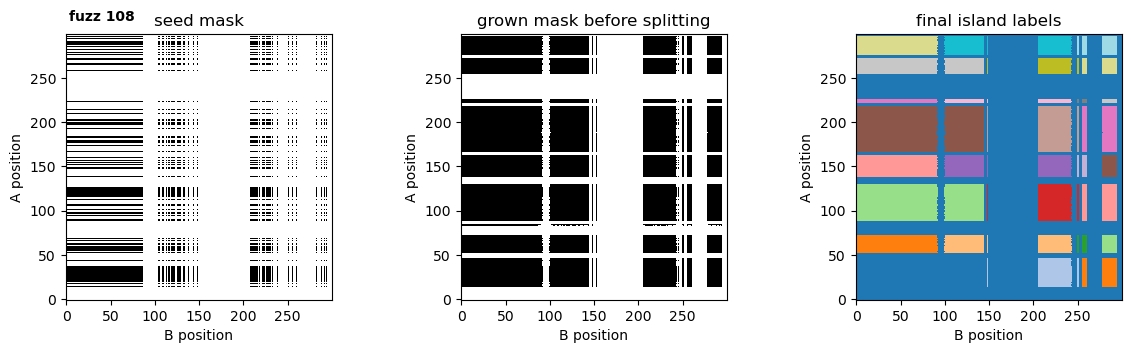

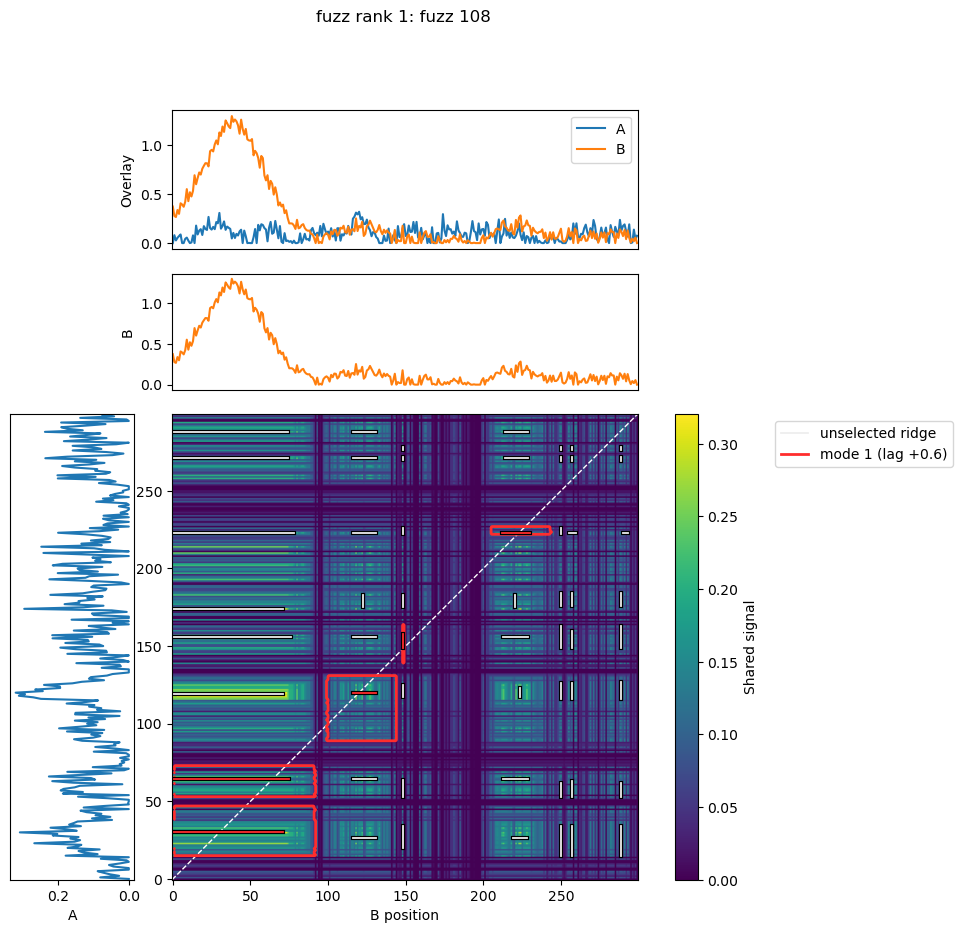

,mode,lag,islands,compatible,n_islands,n_independent,score,all_score,fraction,zero_lag,conflict_fraction
0,1,-251.000000,"(50,)","(50,)",1,1,49.920374,49.920374,0.158804,False,0.000000
1,2,-234.000000,"(43,)","(43,)",1,1,34.579911,34.579911,0.110004,False,0.000000
2,3,-184.000000,"(36,)","(36,)",1,1,2.291268,2.291268,0.007289,False,0.000000
3,4,-164.500000,"(51,)","(51,)",1,1,40.831000,40.831000,0.129889,False,0.000000
4,5,-147.500000,"(44,)","(44,)",1,1,28.373608,28.373608,0.090260,False,0.000000
5,6,-138.500000,"(29,)","(29,)",1,1,273.666874,273.666874,0.870573,False,0.000000
6,7,-129.000000,"(52,)","(52,)",1,1,0.094101,0.094101,0.000299,False,0.000000
7,8,-118.010524,"(45, 22)","(22, 45)",2,2,57.546649,57.546649,0.183064,False,0.000000
8,9,-99.500000,"(37,)","(37,)",1,1,1.953329,1.953329,0.006214,False,0.000000
9,10,-83.509671,"(15,)","(15,)",1,1,236.982895,236.982895,0.753876,False,0.000000


In [25]:
# Change these two values to inspect any fuzz result in more detail.
fuzz_rank_to_replot = 1
show_internal_stages = True

chosen = fuzz_records[fuzz_rank_to_replot - 1]["result"]
if show_internal_stages:
    plot_detection_stages([chosen])
utils.plot_simulated_islands(chosen, title=f"fuzz rank {fuzz_rank_to_replot}: {chosen['stress_label']}")
display(mode_table(chosen))